# 🤖 텍스트 모델링 입문
### — 감성분석 · 다중분류 · 토픽모델링까지 —

---

## 📋 학습 목표

이 노트북의 학습을 마치면 다음을 할 수 있습니다:

1. **텍스트 데이터**를 전처리하고 모델에 입력할 수 있는 형태로 변환
2. **감성분석**: 텍스트가 긍정인지 부정인지 KLUE-BERT로 자동 판별
3. **다중분류**: 뉴스 헤드라인을 7개 카테고리 중 하나로 분류
4. **토픽모델링**: 레이블 없이 문서 집합에서 숨겨진 주제를 자동 발견
5. **심화 분석**: 오답 분석, 혼동행렬, 토픽 병합 등

## 📚 목차

| Part | 주제 | 내용 |
|------|------|------|
| **Part 0** | 환경 설정 | 라이브러리 설치, GPU 확인, 한글 폰트 |
| **Part 1** | NLP 모델링 개념 | 텍스트→숫자, 파인튜닝, 태스크 유형 |
| **Part 2** | 감성분석 (Sentiment) | KLUE-BERT 파인튜닝 + 오답분석 + 신뢰도 분석 |
| **Part 3** | 다중분류 (Multi-class) | 뉴스 카테고리 분류 + 혼동행렬 + 오분류 패턴 분석 |
| **Part 4** | 토픽모델링 (Topic) | BERTopic + 시각화 + 토픽 병합 |
| **Part 5** | 정리 및 요약 | 3가지 태스크 비교, 실무 팁, 다음 단계 |


> 임베딩 교안에서 "텍스트를 벡터로 변환하는 방법"을 배웠다면, 이 교안에서는
> "그 벡터로 실제 유용한 판단을 내리는 방법"을 배웁니다.
>
> ⚡ **실행 환경**: Google Colab (GPU 권장)  
> **런타임 → 런타임 유형 변경 → GPU** 를 먼저 선택하세요.


---
# Part 0. 환경 설정

실습에 필요한 라이브러리를 설치하고, GPU 환경을 확인하며, 한글 폰트를 설정합니다.
각 라이브러리가 어떤 역할을 하는지 아래 다이어그램에서 확인하세요.

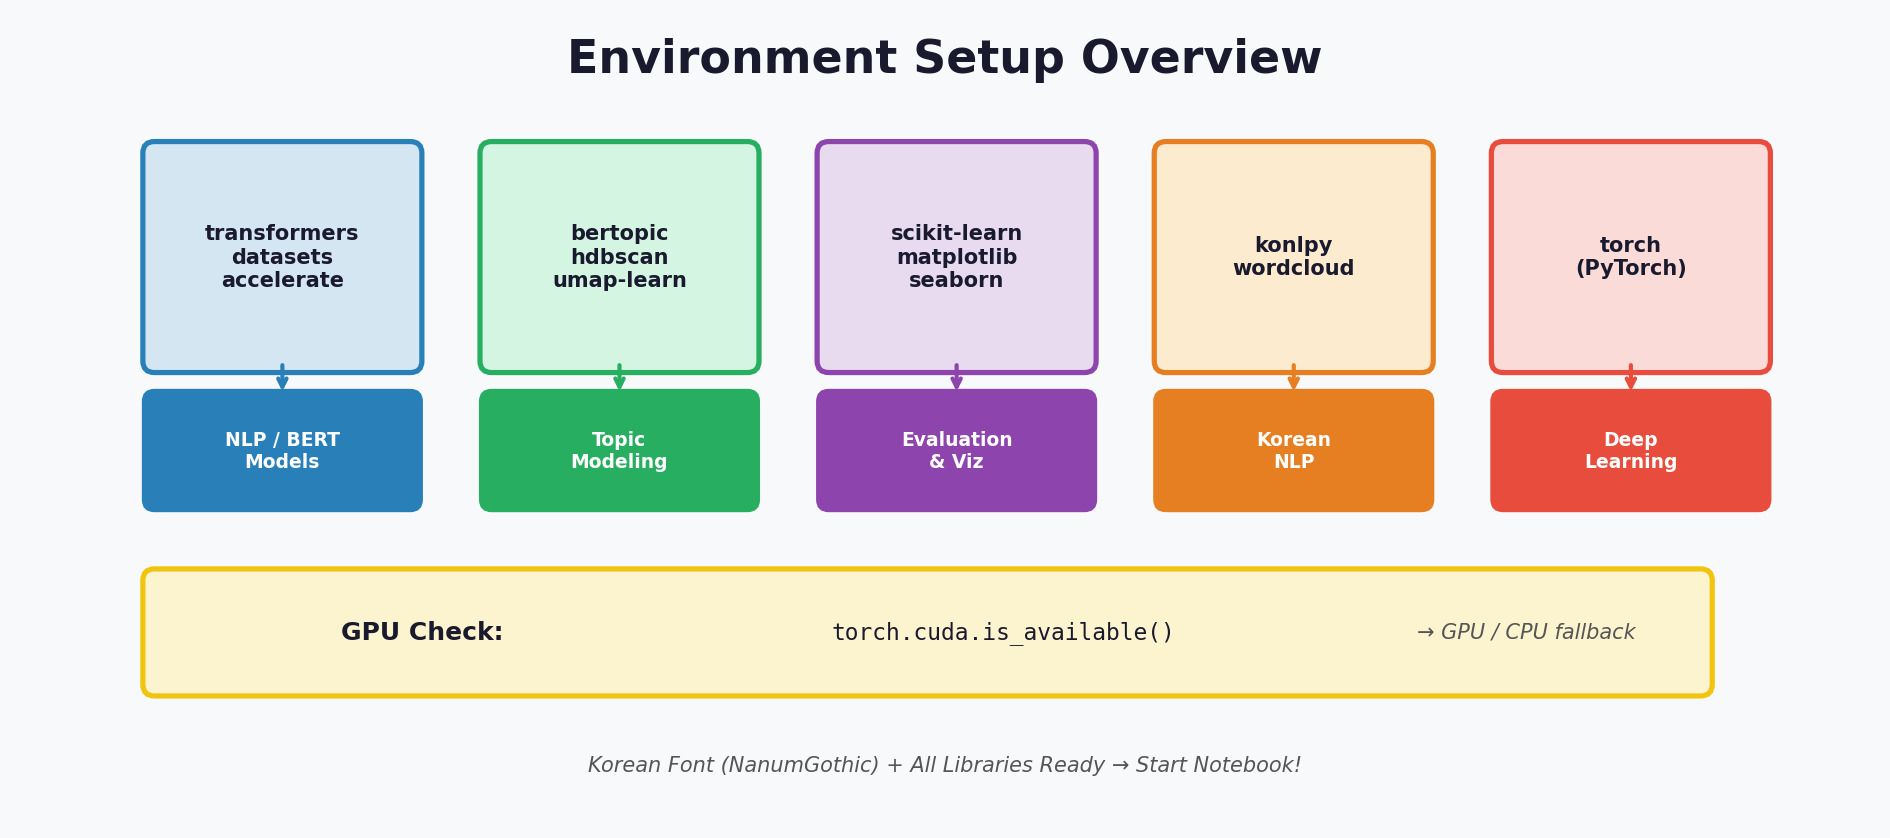

*▲ Environment Setup: 5 library groups needed for this notebook*

## 설치할 주요 라이브러리 상세 설명

| 그룹 | 라이브러리 | 역할 | 왜 필요한가? |
|------|-----------|------|-------------|
| **NLP/BERT** | `transformers`, `datasets`, `accelerate` | KLUE-BERT 모델 로드 및 파인튜닝 | Hugging Face의 사전학습 모델을 바로 가져다 사용할 수 있는 핵심 라이브러리 |
| **토픽모델링** | `bertopic`, `hdbscan`, `umap-learn` | 비지도 토픽 추출 | BERTopic은 UMAP(차원축소)과 HDBSCAN(클러스터링)을 내부적으로 사용 |
| **시각화** | `matplotlib`, `seaborn`, `wordcloud` | 결과 분석 차트 | 모델 성능 시각화, 혼동행렬, 워드클라우드 등 |
| **한국어 NLP** | `konlpy` | 형태소 분석기 | 토픽모델링에서 단어 분리 시 사용 (선택적) |
| **딥러닝** | `torch` (PyTorch) | GPU 가속 학습 | BERT 파인튜닝의 핵심 프레임워크 |

> ⚡ **실행 순서**: 반드시 **셀 순서대로** 실행하세요.
> 설치(Cell 1) → 임포트 및 폰트 설정(Cell 2) → 이후 실습 순으로 진행됩니다.

> 🖥️ **GPU 확인 방법**: Cell 2 실행 후 `device: cuda` 가 출력되어야 GPU를 사용 중입니다.
> `device: cpu` 가 출력된다면, 런타임 유형을 GPU로 변경 후 **런타임 → 모두 다시 시작** 하세요.

> ⏱️ **예상 설치 시간**: 라이브러리 설치에 2~5분이 소요될 수 있습니다. `pip install -q` 의
> `-q` 옵션은 불필요한 로그를 숨겨 출력을 간결하게 유지합니다.

In [ ]:
# Colab / 로컬 환경 공통 설치
!pip install -q transformers datasets accelerate sentencepiece
!pip install -q bertopic hdbscan umap-learn
!pip install -q scikit-learn matplotlib seaborn wordcloud
!pip install -q konlpy  # 한국어 형태소 분석기

# Colab GPU 확인
import torch
if torch.cuda.is_available():
    print(f"✅ GPU 사용 가능: {torch.cuda.get_device_name(0)}")
    print(f"   메모리: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
elif torch.backends.mps.is_available():
    print("애플 실리콘 사용")
else:
    print("⚠️ GPU를 사용할 수 없습니다. Colab에서 런타임 > 런타임 유형 변경 > GPU를 선택하세요.")
    print("   CPU로도 실행 가능하지만 학습 시간이 오래 걸립니다.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 74.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 495.9/495.9 kB 34.6 MB/s eta 0:00:00
✅ GPU 사용 가능: Tesla T4
   메모리: 14.6 GB


In [ ]:
import os
import subprocess
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns


def setup_korean_font_colab():
    """Google Colab에서 한글 폰트 설정"""

    print("===== 한글 폰트 설정 시작 =====")

    # 1) 나눔 폰트 설치
    try:
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "-qq", "fonts-nanum"], check=True)
        print("[1/4] fonts-nanum 설치 완료")
    except Exception as e:
        print(f"[1/4] fonts-nanum 설치 중 오류: {e}")

    # 2) 시스템 폰트 캐시 갱신
    try:
        subprocess.run(["fc-cache", "-fv"], check=True, stdout=subprocess.DEVNULL)
        print("[2/4] 시스템 폰트 캐시 갱신 완료")
    except Exception as e:
        print(f"[2/4] 시스템 폰트 캐시 갱신 중 오류: {e}")

    # 3) matplotlib 폰트 캐시 삭제
    try:
        cache_dir = matplotlib.get_cachedir()
        for f in os.listdir(cache_dir):
            if "fontlist" in f:
                os.remove(os.path.join(cache_dir, f))
        print("[3/4] matplotlib 폰트 캐시 삭제 완료")
    except Exception as e:
        print(f"[3/4] matplotlib 폰트 캐시 삭제 중 오류: {e}")

    # 4) 폰트 파일 직접 등록
    font_candidates = [
        "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
        "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf",
        "/usr/share/fonts/truetype/nanum/NanumSquareR.ttf",
    ]

    selected_font = None
    for font_path in font_candidates:
        if os.path.exists(font_path):
            fm.fontManager.addfont(font_path)
            font_prop = fm.FontProperties(fname=font_path)
            selected_font = font_prop.get_name()
            break

    if selected_font is None:
        print("[4/4] 한글 폰트를 찾지 못했습니다.")
        return None

    # matplotlib 기본 폰트 설정
    plt.rcParams["font.family"] = selected_font
    plt.rcParams["axes.unicode_minus"] = False

    # seaborn도 같이 설정해야 덮어쓰기 방지 가능
    sns.set_theme(style="whitegrid", font=selected_font, rc={"axes.unicode_minus": False})

    print(f"[4/4] 한글 폰트 적용 완료: {selected_font}")
    return selected_font


# 실행
font_name = setup_korean_font_colab()
print("적용된 폰트:", font_name)

===== 한글 폰트 설정 시작 =====
[1/4] fonts-nanum 설치 완료
[2/4] 시스템 폰트 캐시 갱신 완료
[3/4] matplotlib 폰트 캐시 삭제 완료
[4/4] 한글 폰트 적용 완료: NanumGothic
적용된 폰트: NanumGothic


In [ ]:
# === 디바이스 설정 ===
# Colab: cuda / Mac: mps / 그 외: cpu
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print(f'✅ 사용 디바이스: {device}')

✅ 사용 디바이스: cuda


---
# Part 1. NLP 모델링 — 개념 이해

## 🤔 "모델링"이란?

임베딩 교안에서 **텍스트를 숫자(벡터)로 변환**하는 방법을 배웠습니다.  
이제 그 숫자들을 가지고 **실제로 유용한 작업을 수행**하는 단계입니다.

> 📌 임베딩은 "언어를 숫자로 바꾸는 것", 모델링은 "그 숫자로 판단하는 것"

아래 다이어그램은 NLP 모델링의 전체 흐름을 보여줍니다.  
**원시 텍스트**에서 시작해서 **예측 결과**까지 어떤 단계를 거치는지 확인하세요.

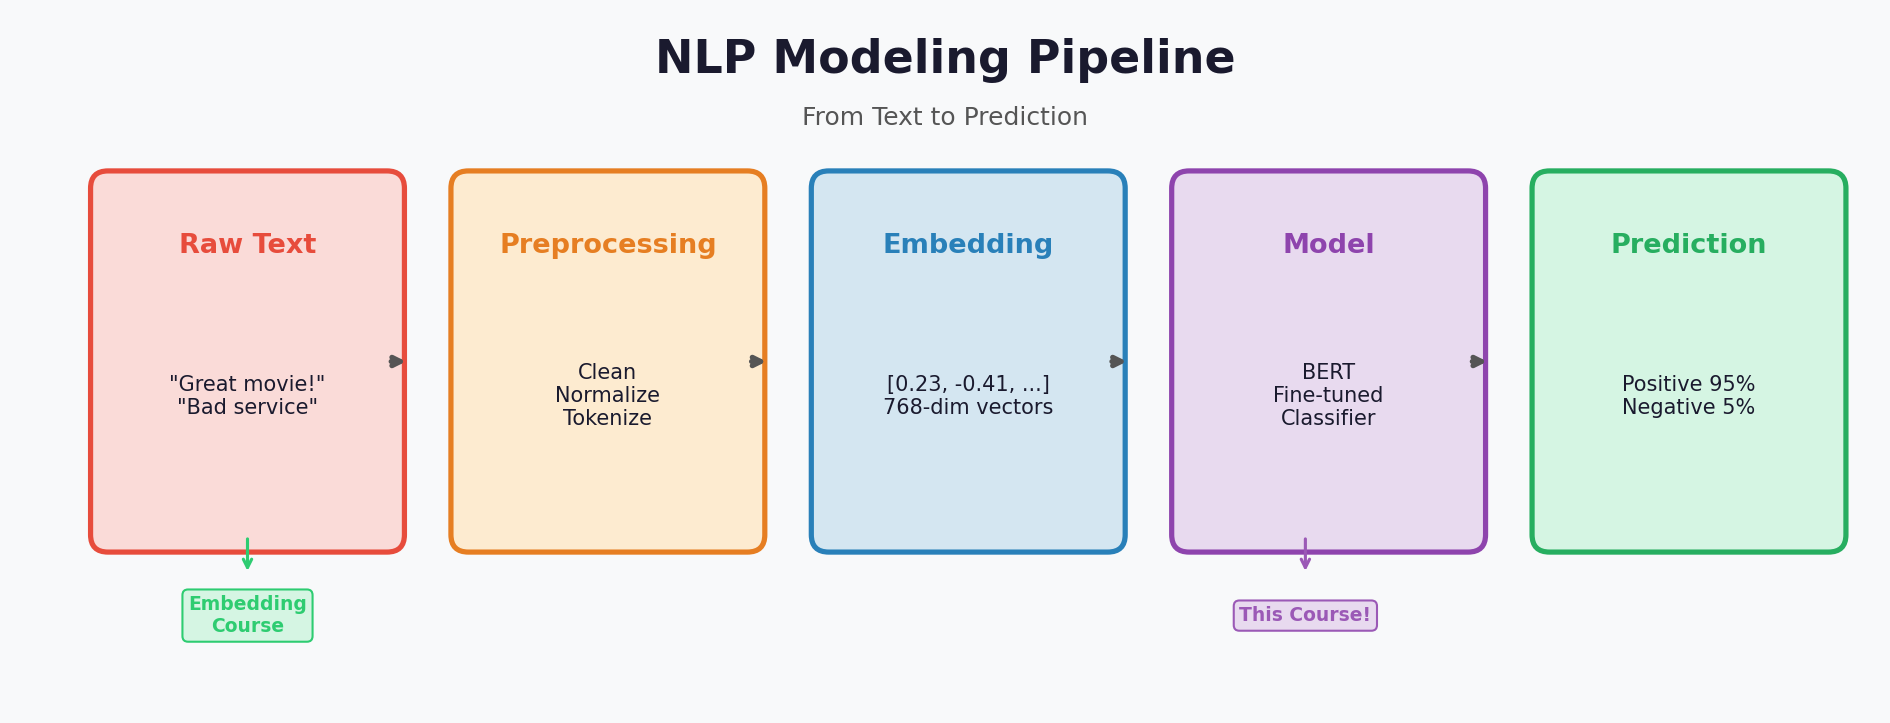

*▲ NLP 모델링 파이프라인: 텍스트 → 전처리 → 임베딩 → 모델 → 예측*

### 각 단계 설명

| 단계 | 역할 | 예시 |
|------|------|------|
| **Raw Text** | 사용자가 입력한 원시 텍스트 | `"Great movie!" / "Bad service"` |
| **Preprocessing** | 노이즈 제거, 정규화, 토크나이징 | 특수문자 제거, 소문자 변환, 단어 분리 |
| **Embedding** | 텍스트를 의미 있는 숫자 벡터로 변환 | `[0.23, -0.41, ...]` 768차원 벡터 |
| **Model** | 벡터에서 패턴을 학습하고 판단 | BERT + Fine-tuned Classifier |
| **Prediction** | 최종 결과 출력 (확률 포함) | `"Positive 95% / Negative 5%"` |

> 💡 **핵심**: 임베딩 교안에서 배운 Sentence-BERT, KLUE-BERT의 출력값이  
> 바로 이 "Embedding" 단계의 결과입니다. 이 교안에서는 Model ~ Prediction 단계를 배웁니다.

## 🎯 NLP 모델이 수행하는 대표 태스크

| 태스크 | 입력 | 출력 | 대표 활용 |
|--------|------|------|----------|
| **감성 분석** | 텍스트 | 긍정 / 부정 / 중립 | 리뷰 분석, 여론 모니터링 |
| **텍스트 분류** | 텍스트 | 카테고리 레이블 | 뉴스 분류, 스팸 탐지 |
| **기계 번역** | 소스 언어 문장 | 타깃 언어 문장 | 구글 번역, DeepL |
| **텍스트 요약** | 긴 문서 | 핵심 요약문 | 뉴스 요약, 문서 압축 |
| **질의응답 (QA)** | 질문 (+ 문서) | 정답 텍스트 | 검색, 챗봇, RAG |
| **텍스트 생성** | 프롬프트 / 문맥 | 이어지는 텍스트 | GPT, 글쓰기 보조 |
| **자연어 추론 (NLI)** | 전제 문장 + 가설 문장 | 함의 / 중립 / 모순 | 팩트체크, 논리 판별 |
| **의미 유사도** | 문장 쌍 | 유사도 점수 (0~1) | 중복 탐지, 문서 검색 |
| **대화 / 챗봇** | 대화 히스토리 | 응답 문장 | 고객센터, AI 어시스턴트 |
| **코드 생성** | 자연어 명세 / 코드 일부 | 코드 | GitHub Copilot, CodeLlama |
| **정보 추출** | 비정형 텍스트 | 구조화된 정보 (관계, 이벤트 등) | 계약서 분석, 의료 기록 파싱 |
> 🔑 **지도학습 vs 비지도학습**:  
> 지도학습(감성분석/다중분류)은 "정답 레이블"이 있는 데이터로 학습합니다.  
> 비지도학습(토픽모델링)은 레이블 없이 데이터의 패턴을 스스로 찾아냅니다.


## 🧠 사전학습 모델과 파인튜닝

딥러닝을 처음부터 학습시키려면 엄청난 데이터와 계산 비용이 필요합니다.  
**전이학습(Transfer Learning)** 은 이미 학습된 모델을 이용해서 태스크에 맞게 학습시켜 재사용합니다.

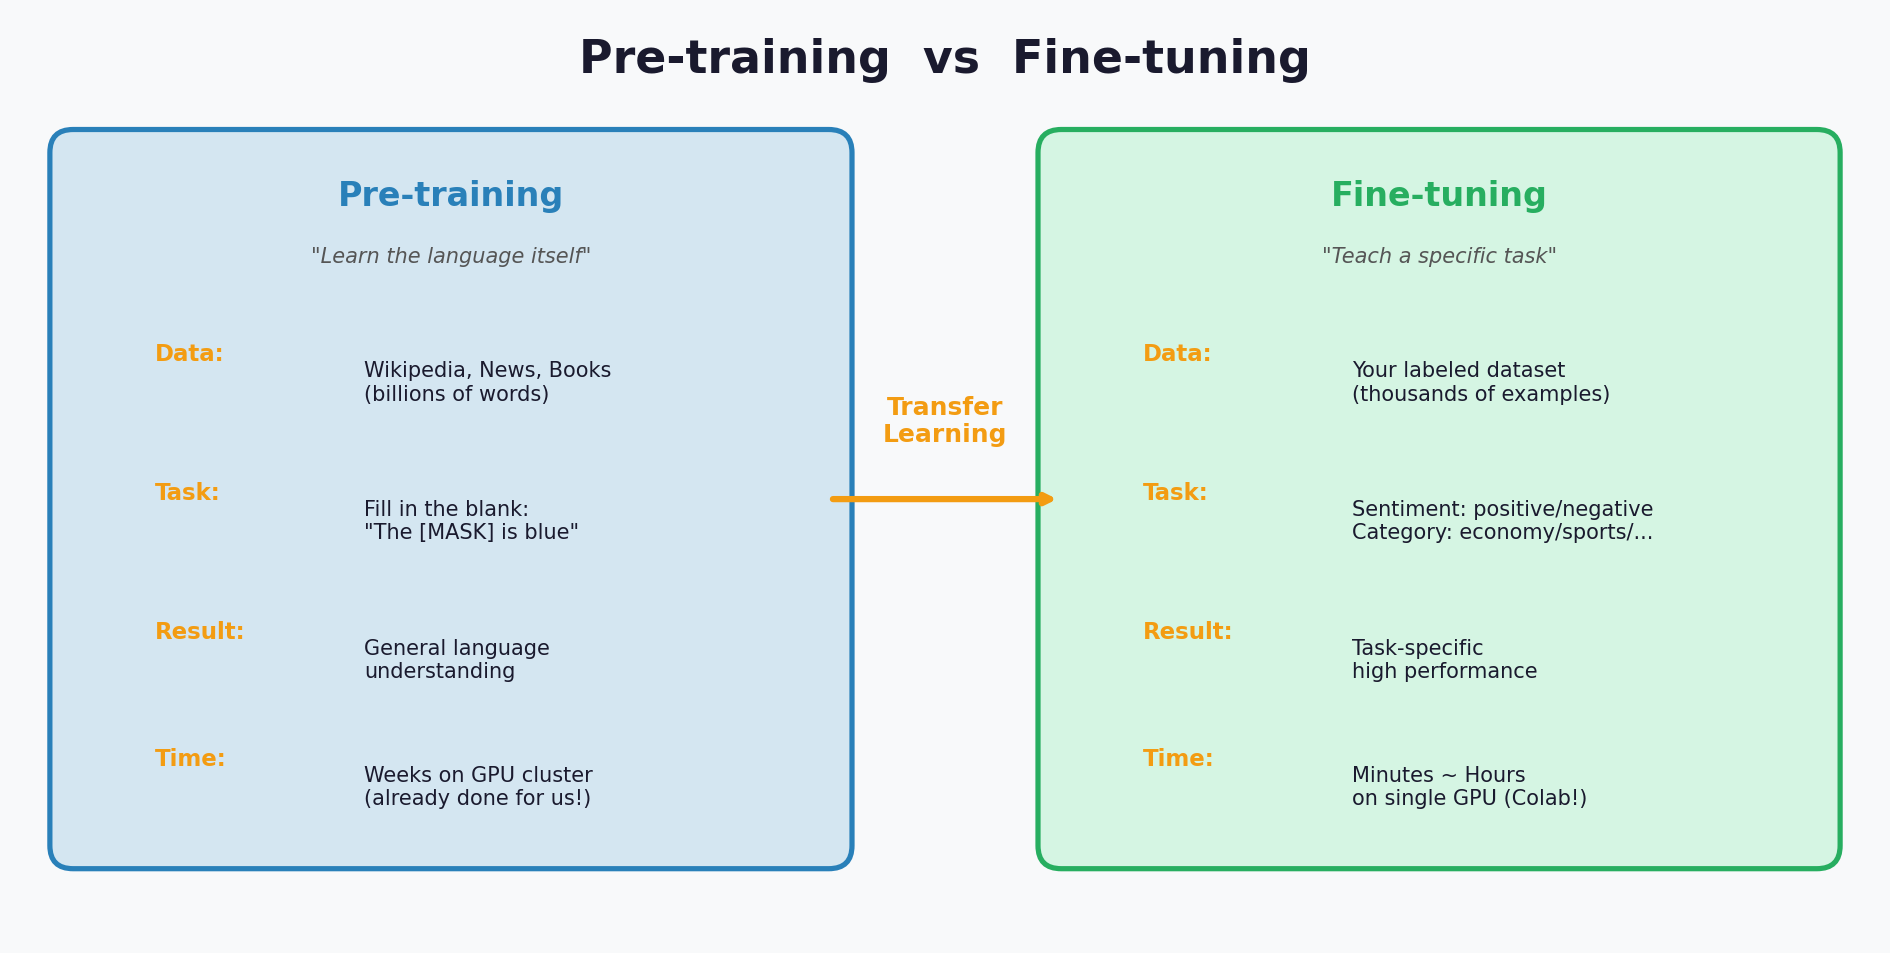

*▲ 사전학습으로 언어를 이해하고, 파인튜닝으로 특정 태스크에 적응*

### 사전학습 (Pre-training)
대량의 텍스트로 **언어 자체를 이해**하도록 학습된 모델입니다.
- 위키백과, 뉴스, 책 등 수십억 단어로 학습 (이미 완료된 작업!)
- `"[MASK] 영화는 재미있다"` 처럼 빈칸 맞추기 과제를 통해 문맥 이해 능력 습득
- 예: BERT, GPT, KLUE-BERT — 이 과정은 몇 주 ~ 몇 달이 걸릴 수 있습니다

### 파인튜닝 (Fine-tuning)
사전학습된 모델을 **내가 원하는 특정 작업에 맞게 조정**하는 것입니다.
- 적은 데이터(수천~수만 개)로도 높은 성능 달성 가능
- 마지막 분류 레이어만 새로 추가하고 전체 모델을 함께 미세 조정
- Colab에서 GPU 사용 시 **수십 분** 내에 완료 가능!
- 마치 "유창한 한국어 사용자"에게 특정 업무를 훈련시키는 것과 같습니다

> 💡 **비유**: 사전학습 = "한국어를 유창하게 하는 사람 (이미 있음!)"  
> 파인튜닝 = "그 사람에게 영화 리뷰 긍/부정 평가법을 가르치기"  
> 처음부터 사람을 키우는 것보다 **훨씬 빠르고 효율적**입니다.

## Hugging Face Hub란?

**Hugging Face**는 자연어 처리(NLP) 및 AI 분야의 오픈소스 플랫폼으로,  
수십만 개의 사전학습 모델과 데이터셋을 공유하는 **Model Hub**를 운영합니다.

| 구성 요소 | 설명 |
|---|---|
| **Model Hub** | BERT, GPT, T5 등 다양한 모델 공유 저장소 |
| **Dataset Hub** | NLP/CV 벤치마크 데이터셋 공유 |
| **Transformers** | 모델 로드·파인튜닝 통합 라이브러리 |
| **Datasets** | 데이터 전처리 및 로딩 라이브러리 |

---


## 🇰🇷 오늘 사용할 모델: KLUE-BERT

**KLUE (Korean Language Understanding Evaluation)** 벤치마크를 위해 만들어진 한국어 특화 BERT 모델입니다.  
일반 BERT는 영어 중심으로 학습되었지만, KLUE-BERT는 **한국어 텍스트**로 처음부터 학습되어  
한국어의 특성(교착어, 형태소, 존댓말 등)을 훨씬 잘 이해합니다.

| 항목 | 내용 |
|------|------|
| 모델명 | `klue/bert-base` |
| 파라미터 수 | 약 1.1억 개 (110M) |
| 학습 데이터 | 한국어 위키(17GB), 뉴스, 모두의 말뭉치 등 총 62GB |
| 토크나이저 | WordPiece (한국어 32,000 어휘로 최적화) |
| 임베딩 차원 | 768 |
| Transformer 층 | 12층 |
| 특징 | KLUE 8개 태스크에서 기존 BERT 대비 평균 5% 이상 성능 향상 |

```python
from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained("klue/bert-base")
model     = AutoModel.from_pretrained("klue/bert-base")
```

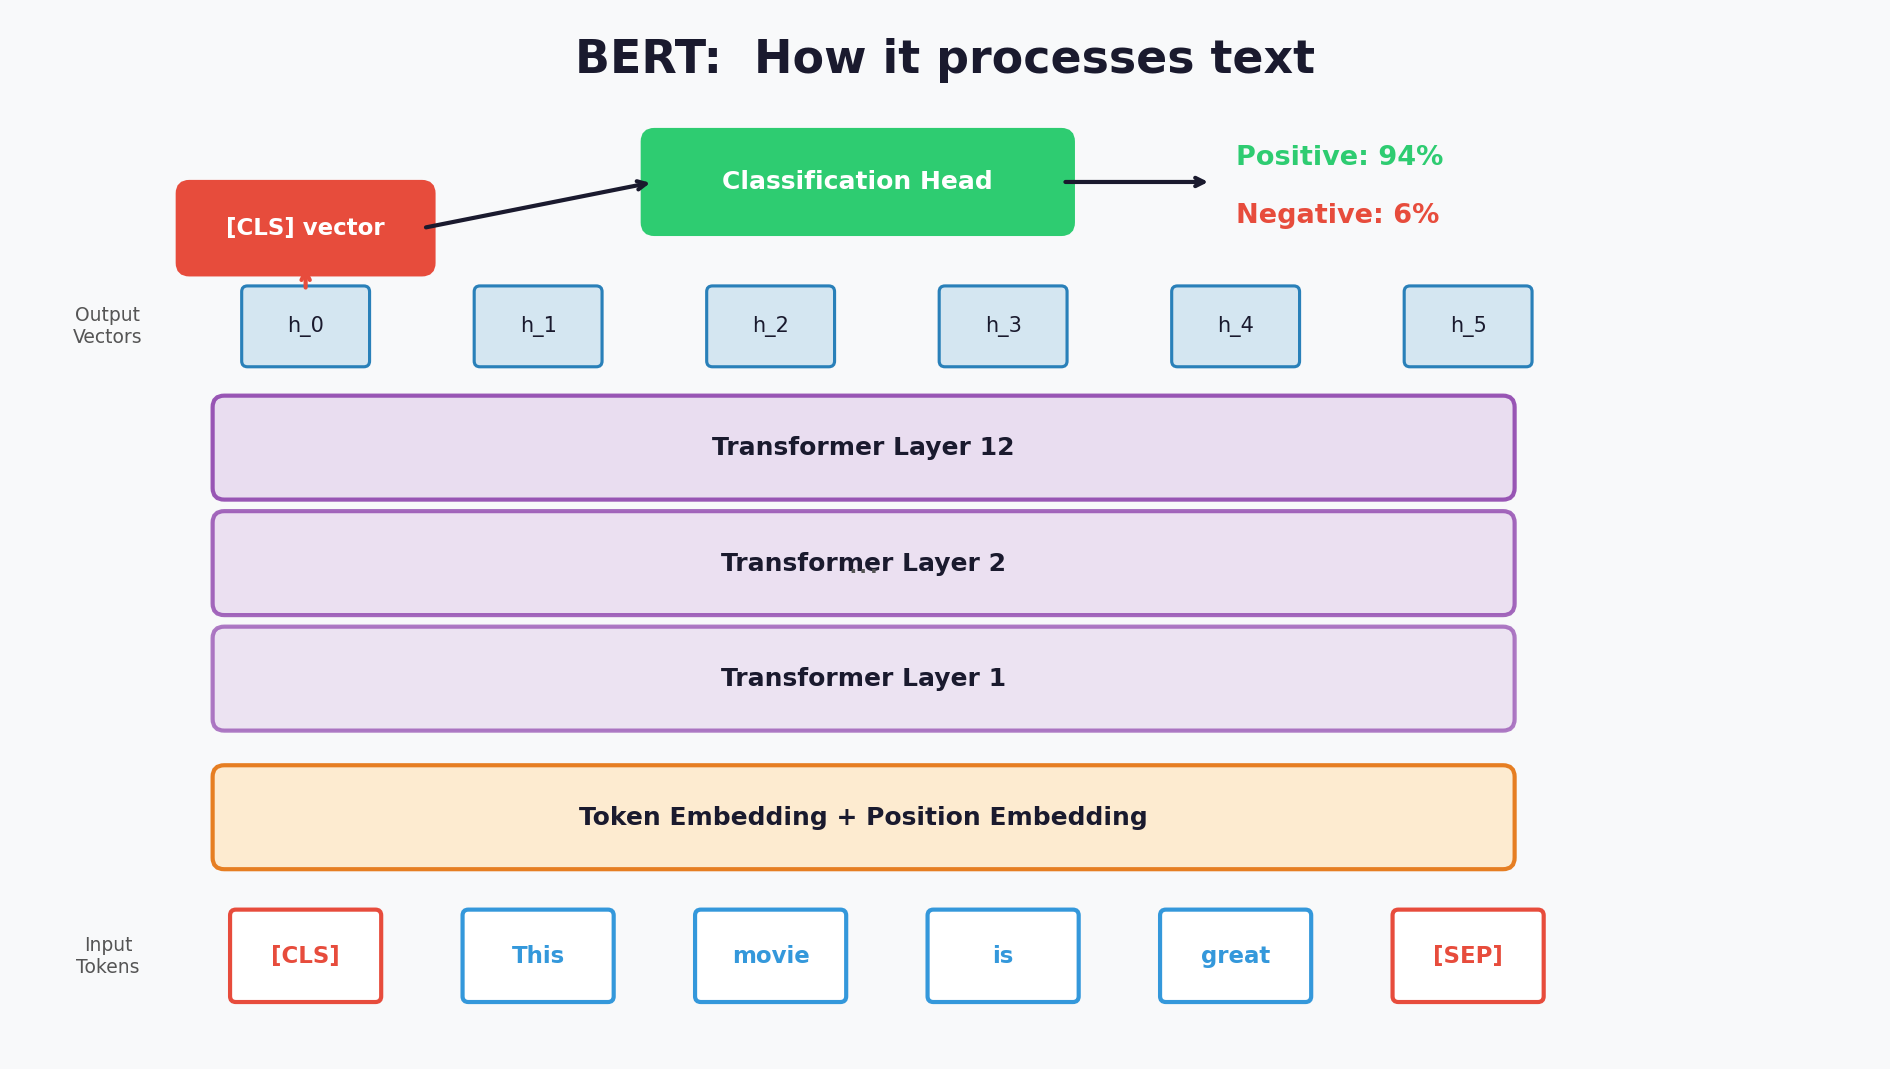

*▲ BERT: 토큰화 → 임베딩 → Transformer 12층 → [CLS] 벡터로 분류*

### BERT의 동작 원리

```
입력 문장: "이 영화 정말 재미있다"
    ↓ ① 토큰화 (WordPiece)
["[CLS]", "이", "영화", "정말", "재미있", "##다", "[SEP]"]
← 특수 토큰 →          ← 의미 단위로 분리 →

    ↓ ② 임베딩 (각 토큰 → 768차원 벡터)
[v_CLS, v_이, v_영화, v_정말, v_재미있, v_다, v_SEP] -> v_는 벡터화를 의미

    ↓ ③ Transformer Self-Attention
각 토큰이 다른 모든 토큰과 "관계"를 파악
예: "재미있" 토큰이 "영화"와 강하게 연결됨

    ↓ ④ [CLS] 토큰의 최종 벡터 추출
[0.82, -0.15, 0.43, ...] (768차원)  ← 문장 전체의 의미 압축

    ↓ ⑤ 분류 헤드 (Linear Layer + Softmax)
"긍정" (94%) / "부정" (6%)
```

### WordPiece 토크나이저 - 한국어에서 중요한 이유

한국어는 **교착어**입니다. 하나의 어근에 조사/어미가 붙어 의미가 달라집니다:
- `먹다`, `먹어`, `먹었다`, `먹으면서`, `먹히다` → 모두 "먹-"에서 파생
- WordPiece는 이런 공통 부분(서브워드)을 인식해 어휘 수를 효율적으로 관리합니다
- `"재미있다"` → `["재미있", "##다"]` 처럼 의미 단위로 분리됩니다
- `##` 접두사는 "이전 토큰과 붙어있음"을 의미합니다

> 💡 **[CLS] 토큰**: 문장 맨 앞에 항상 추가되는 특수 토큰입니다.  
> Transformer를 통과하면서 **문장 전체의 의미가 압축**되어,  
> 분류 태스크에서는 이 [CLS] 벡터만 분류 헤드에 전달합니다.

In [ ]:
# KLUE-BERT 토크나이저 체험
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("klue/bert-base")

# 예시 문장들
sentences = [
    "이 영화 정말 재미있다",
    "삼성전자가 신제품을 출시했습니다",
    "오늘 날씨가 좋아서 기분이 좋다",
]

print("=== KLUE-BERT 토크나이저 체험 ===")
print()

for sent in sentences:
    # tokens = tokenizer.tokenize(sent)
    tokens = tokenizer.convert_ids_to_tokens(tokenizer.encode(sent))
    token_ids = tokenizer.encode(sent)

    print(f"원문: {sent}")
    print(f"토큰: {tokens}")
    print(f"토큰 ID: {token_ids}")
    print(f"토큰 수: {len(tokens)}")
    print("-" * 50)

# 특수 토큰 설명
print()
print("📌 특수 토큰 설명:")
print(f"  [CLS] (ID: {tokenizer.cls_token_id}) — 문장 전체를 대표하는 토큰")
print(f"  [SEP] (ID: {tokenizer.sep_token_id}) — 문장의 끝을 표시")
print(f"  [PAD] (ID: {tokenizer.pad_token_id}) — 길이 맞추기용 빈 칸")
print(f"  [UNK] (ID: {tokenizer.unk_token_id}) — 사전에 없는 단어")


config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

=== KLUE-BERT 토크나이저 체험 ===

원문: 이 영화 정말 재미있다
토큰: ['[CLS]', '이', '영화', '정말', '재미있', '##다', '[SEP]']
토큰 ID: [2, 1504, 3771, 3944, 6001, 2062, 3]
토큰 수: 7
--------------------------------------------------
원문: 삼성전자가 신제품을 출시했습니다
토큰: ['[CLS]', '삼성전자', '##가', '신', '##제품', '##을', '출시', '##했', '##습', '##니다', '[SEP]']
토큰 ID: [2, 4798, 2116, 1327, 8350, 2069, 4542, 2371, 2219, 3606, 3]
토큰 수: 11
--------------------------------------------------
원문: 오늘 날씨가 좋아서 기분이 좋다
토큰: ['[CLS]', '오늘', '날씨', '##가', '좋아', '##서', '기분', '##이', '좋', '##다', '[SEP]']
토큰 ID: [2, 3822, 5792, 2116, 5723, 2112, 4754, 2052, 1560, 2062, 3]
토큰 수: 11
--------------------------------------------------

📌 특수 토큰 설명:
  [CLS] (ID: 2) — 문장 전체를 대표하는 토큰
  [SEP] (ID: 3) — 문장의 끝을 표시
  [PAD] (ID: 0) — 길이 맞추기용 빈 칸
  [UNK] (ID: 1) — 사전에 없는 단어


## 🔬 BERT 내부 들여다보기: 토큰 → 임베딩 → Transformer

앞에서 텍스트가 **토큰 ID**(정수)로 변환되는 것을 확인했습니다.  
하지만 BERT 모델에는 정수가 직접 들어가지 않습니다. 내부적으로 다음 변환이 일어납니다:

```
토큰 ID [2, 3456, 7890, ...]       ← 단순한 정수 (의미 없음)
         ↓ Embedding Layer (학습된 lookup table)
임베딩 벡터 [[0.12, -0.34, ...],    ← 768차원 실수 벡터 (의미 포함)
            [0.56,  0.78, ...],
            ...]
         ↓ 12개 Transformer Layer (Self-Attention)
문맥 반영 벡터 [[0.45, -0.12, ...], ← 주변 단어 정보가 반영된 벡터
              ...]
         ↓ [CLS] 토큰의 최종 벡터 추출
분류 벡터 [0.89, -0.23, ...]         ← 문장 전체를 대표하는 1개 벡터
         ↓ Classification Head (Linear Layer)
예측 확률 [긍정: 0.92, 부정: 0.08]   ← Softmax 출력
```

아래 코드에서 **각 단계의 실제 텐서**를 직접 확인합니다.  
숫자가 어떻게 변하는지, 차원이 어떻게 바뀌는지 눈으로 보세요!

In [ ]:
# === 🔬 BERT 내부: 토큰 → 임베딩 → Transformer 과정 직접 확인 ===
from transformers import AutoModel

# BERT 모델 로드 (분류 헤드 없는 순수 BERT)
bert_base = AutoModel.from_pretrained("klue/bert-base")
bert_base.eval()

# 예시 문장 토큰화
example_text = "이 영화 정말 재미있다"
inputs = tokenizer(example_text, return_tensors="pt", padding=True, truncation=True)

print("=" * 65)
print("🔬 BERT 내부 처리 과정 — 단계별 확인")
print("=" * 65)

# ── 단계 1: 토큰화 결과 (정수 ID) ──
print("\n📌 [단계 1] 토큰화 — 텍스트를 정수 ID로 변환")
print(f"   원문: {example_text}")
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
ids = inputs['input_ids'][0].tolist()
print(f"   토큰:  {tokens}")
print(f"   ID:    {ids}")
print(f"   shape: {inputs['input_ids'].shape}  → (배치=1, 토큰수={inputs['input_ids'].shape[1]})")

# ── 단계 1.5: BERT 입력의 3가지 구성요소 ──
print("\n📌 [단계 1.5] BERT 입력 3요소")
print(f"   input_ids:      {inputs['input_ids'][0].tolist()}")
print(f"   attention_mask: {inputs['attention_mask'][0].tolist()}")
print(f"   token_type_ids: {inputs['token_type_ids'][0].tolist()}")
print("   → attention_mask: 1=실제토큰, 0=패딩 (모델이 무시할 위치)")
print("   → token_type_ids: 문장A=0, 문장B=1 (단일 문장이면 모두 0)")

# ── 단계 2: 임베딩 레이어 ──
print("\n📌 [단계 2] 임베딩 — 정수 ID를 768차원 벡터로 변환")
with torch.no_grad():
    # 임베딩 레이어만 실행
    embedding_output = bert_base.embeddings(inputs['input_ids'],
                                            token_type_ids=inputs['token_type_ids'])

print(f"   입력 shape:  {inputs['input_ids'].shape}  (배치, 토큰수) — 정수")
print(f"   출력 shape:  {embedding_output.shape}  (배치, 토큰수, 768) — 실수 벡터")
print(f"\n   '영화' 토큰의 768차원 벡터 (처음 10개 값):")
movie_idx = tokens.index('영화') if '영화' in tokens else 2
print(f"   {embedding_output[0][movie_idx][:10].tolist()}")
print(f"   ... (나머지 758개 값 생략)")

# ── 단계 3: Transformer 12개 레이어 통과 ──
print("\n📌 [단계 3] Transformer 12개 레이어 통과")
with torch.no_grad():
    outputs = bert_base(**inputs, output_hidden_states=True)

print(f"   hidden_states 개수: {len(outputs.hidden_states)}개 (임베딩 + 12 레이어)")
print()
print("   [CLS] 토큰 벡터의 변화 (각 레이어별 L2 노름):")
for i, layer_output in enumerate(outputs.hidden_states):
    cls_vec = layer_output[0][0]  # [CLS] 토큰
    norm = cls_vec.norm().item()
    bar = '█' * int(norm * 2)
    label = 'Embedding' if i == 0 else f'Layer {i:2d}'
    print(f"   {label:10s} | {bar} {norm:.2f}")

# ── 단계 4: 최종 [CLS] 벡터 ──
print("\n📌 [단계 4] 최종 [CLS] 벡터 — 문장 전체를 대표")
cls_final = outputs.last_hidden_state[0][0]  # 마지막 레이어의 [CLS]
print(f"   shape: {cls_final.shape}  → 768차원 벡터 1개")
print(f"   값 (처음 10개): {cls_final[:10].tolist()}")
print(f"\n   💡 이 768차원 벡터가 분류 레이어(Linear)에 입력되어")
print(f"   💡 [긍정 확률, 부정 확률]로 변환됩니다!")

# 메모리 정리 (시각화 셀에서 재사용 후 정리합니다)
# → 다음 셀에서 bert_base를 재활용합니다

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: klue/bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


🔬 BERT 내부 처리 과정 — 단계별 확인

📌 [단계 1] 토큰화 — 텍스트를 정수 ID로 변환
   원문: 이 영화 정말 재미있다
   토큰:  ['[CLS]', '이', '영화', '정말', '재미있', '##다', '[SEP]']
   ID:    [2, 1504, 3771, 3944, 6001, 2062, 3]
   shape: torch.Size([1, 7])  → (배치=1, 토큰수=7)

📌 [단계 1.5] BERT 입력 3요소
   input_ids:      [2, 1504, 3771, 3944, 6001, 2062, 3]
   attention_mask: [1, 1, 1, 1, 1, 1, 1]
   token_type_ids: [0, 0, 0, 0, 0, 0, 0]
   → attention_mask: 1=실제토큰, 0=패딩 (모델이 무시할 위치)
   → token_type_ids: 문장A=0, 문장B=1 (단일 문장이면 모두 0)

📌 [단계 2] 임베딩 — 정수 ID를 768차원 벡터로 변환
   입력 shape:  torch.Size([1, 7])  (배치, 토큰수) — 정수
   출력 shape:  torch.Size([1, 7, 768])  (배치, 토큰수, 768) — 실수 벡터

   '영화' 토큰의 768차원 벡터 (처음 10개 값):
   [0.6160624623298645, 0.12419513612985611, -0.7787317037582397, 0.4498469829559326, -0.6399834156036377, 0.6101656556129456, 0.6872724890708923, 0.9639749526977539, -0.566166341304779, 0.5816969871520996]
   ... (나머지 758개 값 생략)

📌 [단계 3] Transformer 12개 레이어 통과
   hidden_states 개수: 13개 (임베딩 + 12 레이어)

   [CLS] 토큰 벡터의 변화 (각 레이어별 L2 

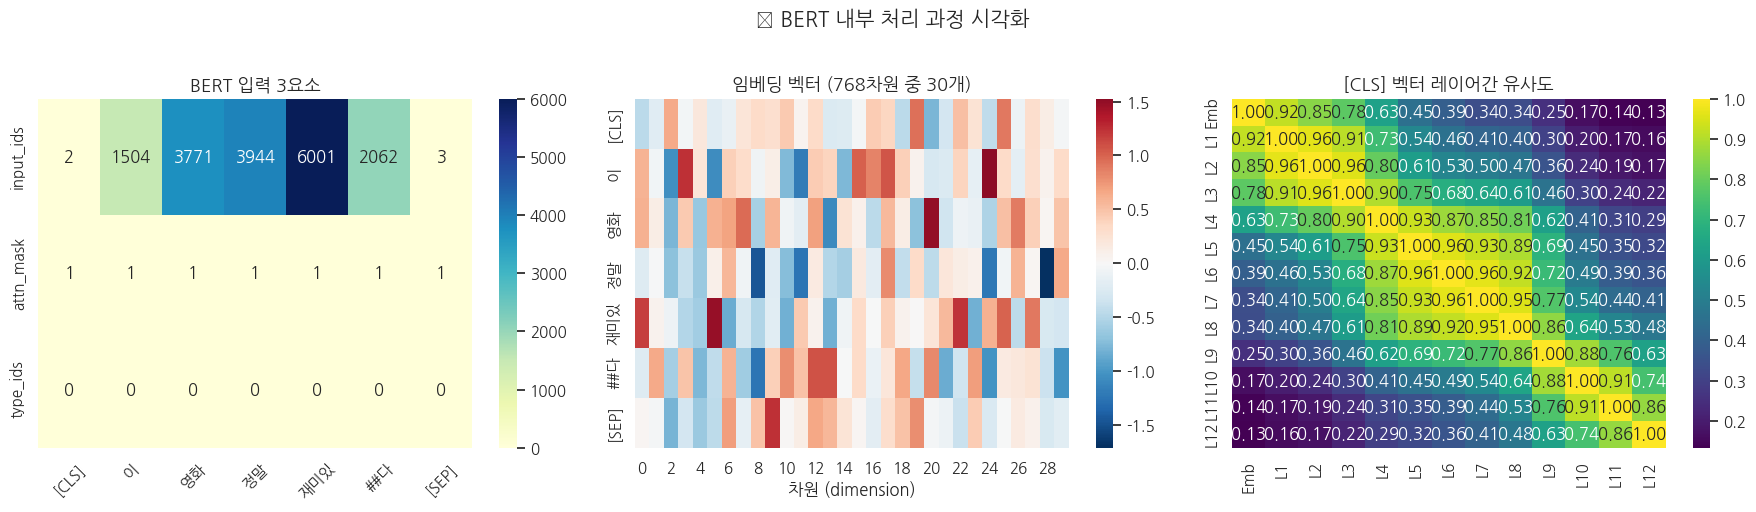


💡 인사이트:
  - 왼쪽: BERT에 들어가는 3가지 입력 (토큰ID, 어텐션마스크, 토큰타입)
  - 가운데: 각 토큰이 768차원 벡터로 변환된 모습 (색상 = 벡터 값)
  - 오른쪽: 레이어를 지날수록 [CLS] 벡터가 점점 달라짐 → 문맥 정보가 축적!


In [ ]:
# === 📊 임베딩 과정 시각화 ===
# 위에서 확인한 과정을 그래프로 시각화합니다

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) input_ids / attention_mask / token_type_ids 히트맵
input_data = np.array([
    inputs['input_ids'][0].numpy(),
    inputs['attention_mask'][0].numpy(),
    inputs['token_type_ids'][0].numpy()
])
sns.heatmap(input_data, annot=True, fmt='d', cmap='YlGnBu', ax=axes[0],
            xticklabels=tokens, yticklabels=['input_ids', 'attn_mask', 'type_ids'])
axes[0].set_title('BERT 입력 3요소', fontsize=13, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

# 2) 임베딩 벡터 히트맵 (처음 30차원만)
# 이전 셀의 bert_base 모델을 재사용합니다 (재로드 불필요!)
with torch.no_grad():
    _emb = bert_base.embeddings(inputs['input_ids'], token_type_ids=inputs['token_type_ids'])
    _out = bert_base(**inputs, output_hidden_states=True)

emb_np = _emb[0, :, :30].numpy()  # 처음 30차원
sns.heatmap(emb_np, cmap='RdBu_r', center=0, ax=axes[1],
            yticklabels=tokens)
axes[1].set_title('임베딩 벡터 (768차원 중 30개)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('차원 (dimension)')

# 3) 레이어별 [CLS] 벡터 변화 (코사인 유사도)
from sklearn.metrics.pairwise import cosine_similarity as cos_sim
n_layers = len(_out.hidden_states)
cls_vectors = [_out.hidden_states[i][0][0].numpy().reshape(1, -1) for i in range(n_layers)]

sim_matrix = np.zeros((n_layers, n_layers))
for i in range(n_layers):
    for j in range(n_layers):
        sim_matrix[i][j] = cos_sim(cls_vectors[i], cls_vectors[j])[0][0]

layer_labels = ['Emb'] + [f'L{i}' for i in range(1, n_layers)]
sns.heatmap(sim_matrix, annot=True, fmt='.2f', cmap='viridis', ax=axes[2],
            xticklabels=layer_labels, yticklabels=layer_labels)
axes[2].set_title('[CLS] 벡터 레이어간 유사도', fontsize=13, fontweight='bold')

plt.suptitle('🔬 BERT 내부 처리 과정 시각화', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n💡 인사이트:")
print("  - 왼쪽: BERT에 들어가는 3가지 입력 (토큰ID, 어텐션마스크, 토큰타입)")
print("  - 가운데: 각 토큰이 768차원 벡터로 변환된 모습 (색상 = 벡터 값)")
print("  - 오른쪽: 레이어를 지날수록 [CLS] 벡터가 점점 달라짐 → 문맥 정보가 축적!")

# 시각화 완료 — BERT 모델 메모리 정리
del bert_base, _emb, _out, embedding_output, outputs
torch.cuda.empty_cache() if torch.cuda.is_available() else None

---
# Part 2. 감성분석 (Sentiment Analysis)

## 📖 감성분석이란?

텍스트에 담긴 **감정, 의견, 태도**를 자동으로 판별하는 기술입니다.  
가장 단순한 형태는 "긍정 vs 부정"의 이진분류이며,  
확장하면 5점 척도(매우 부정/부정/중립/긍정/매우 긍정)나 감정 유형(기쁨/슬픔/분노 등)도 가능합니다.

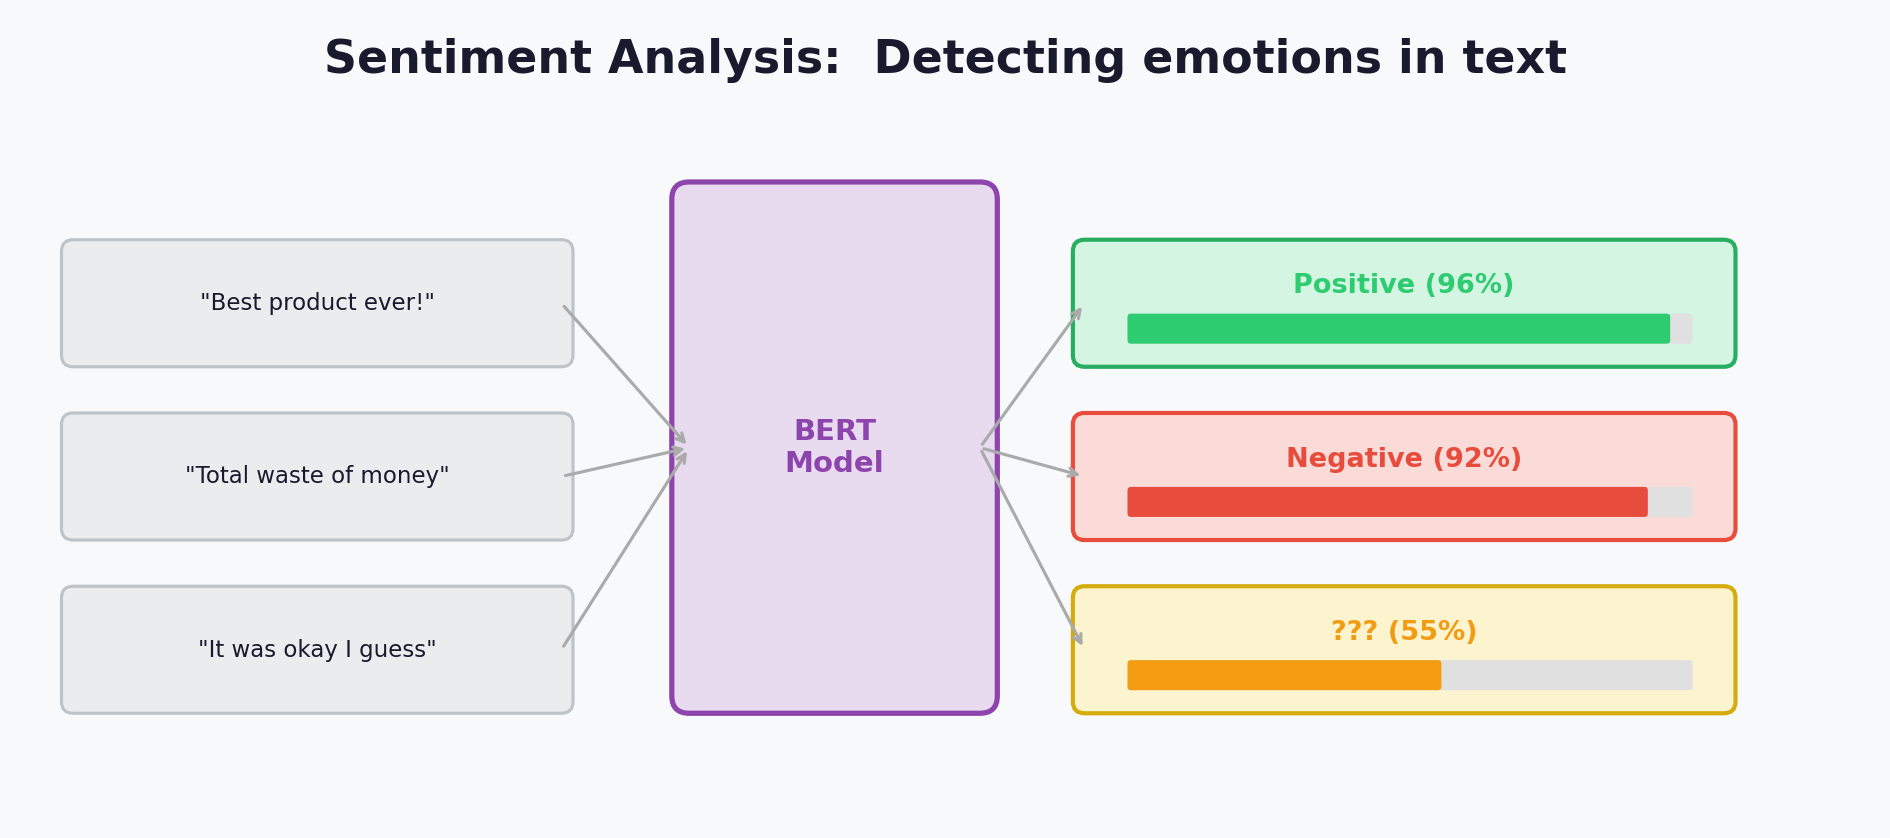

*▲ 감성분석: BERT 모델이 각 텍스트에 대해 긍정/부정 확률을 출력*

위 다이어그램에서 세 번째 문장 `"It was okay I guess"` 에 주목하세요.  
모델이 55%의 낮은 확신도로 예측하는 이유는 **문장 자체가 모호**하기 때문입니다.  
이처럼 감성분석은 단순한 키워드 매칭이 아닌 **문맥 이해**가 필수적입니다.


### 활용 분야

| 분야 | 활용 예시 | 비즈니스 가치 |
|------|-----------|--------------|
| 마케팅 | 제품 리뷰 긍/부정 분석, 브랜드 이미지 모니터링 | 고객 불만을 실시간으로 파악 |
| 금융 | 뉴스 감성으로 주가 방향 예측 | 알고리즘 트레이딩에 활용 |
| 고객서비스 | 불만 접수 자동 분류, 우선순위 지정 | 처리 시간 단축 |
| 정치 | 여론 동향 분석, 정책 반응 모니터링 | 여론 조사 보완 |

### 감성분석의 난이도

```
🟢 쉬움:  "이 제품 최고입니다!"                    → 긍정 ✅ (확신도 높음)
🟡 보통:  "가격 대비 괜찮아요"                     → 긍정? 중립? 🤔
🔴 어려움: "역시 기대를 저버리지 않는군요"           → 맥락에 따라 긍정/부정 😵
🔴 어려움: "배송은 빠른데 제품이 불량이에요"         → 혼합 감성 (Mixed) 😵‍💫
```

> 단순 키워드 매칭이 아닌, **문맥을 이해하는 BERT 모델**이 필요한 이유입니다.  
> "역시"라는 단어만으로는 긍정인지 부정인지 알 수 없습니다.


### 오늘 사용할 데이터: NSMC (Naver Sentiment Movie Corpus)

| 항목 | 내용 |
|------|------|
| 출처 | 네이버 영화 리뷰 (사용자 평점) |
| 크기 | 학습 15만 건 + 테스트 5만 건 |
| 레이블 | 0 = 부정 (1-5점), 1 = 긍정 (6-10점) |
| 특징 | 한국어 감성분석 벤치마크 표준 데이터셋 |
| 난이도 | 리뷰 특성상 줄임말, 오타, 비속어 포함 → 전처리 중요 |

> ⚡ **학습 시간 절약**: 전체 15만 건을 학습하면 GPU에서도 수 시간이 걸립니다.  
> 이 교안에서는 **서브샘플링**(일부만 사용)으로 Colab에서 빠르게 실습 가능하게 합니다.

In [ ]:
import pandas as pd
from datasets import Dataset, DatasetDict

print("=== NSMC (Naver Sentiment Movie Corpus) 직접 로드 ===")
print("네이버 영화 리뷰 데이터: 15만 학습 + 5만 테스트\n")

# 1. 깃허브 원본 txt 파일 직접 로드 (Tab 구분자)
train_df = pd.read_table("https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt")
test_df = pd.read_table("https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt")

# 2. 결측치(NaN) 제거 (원본 nsmc.py에서 수행하던 작업)
train_df = train_df.dropna(subset=['document'])
test_df = test_df.dropna(subset=['document'])

# 3. Hugging Face Dataset 객체로 변환
dataset = DatasetDict({
    'train': Dataset.from_pandas(train_df, preserve_index=False),
    'test': Dataset.from_pandas(test_df, preserve_index=False)
})

print(f"학습 데이터: {len(dataset['train']):,}개")
print(f"테스트 데이터: {len(dataset['test']):,}개\n")

# 샘플 확인 (기존과 동일)
print("--- 데이터 샘플 ---")
for i in range(5):
    row = dataset['train'][i]
    label = "긍정 👍" if row['label'] == 1 else "부정 👎"
    print(f"[{label}] {row['document'][:60]}...")

# 레이블 분포 (기존과 동일)
train_labels = dataset['train']['label']
print(f"\n--- 레이블 분포 ---")
print(f"긍정: {sum(train_labels):,}개 ({sum(train_labels)/len(train_labels)*100:.1f}%)")
print(f"부정: {len(train_labels)-sum(train_labels):,}개 ({(1-sum(train_labels)/len(train_labels))*100:.1f}%)")

=== NSMC (Naver Sentiment Movie Corpus) 직접 로드 ===
네이버 영화 리뷰 데이터: 15만 학습 + 5만 테스트

학습 데이터: 149,995개
테스트 데이터: 49,997개

--- 데이터 샘플 ---
[부정 👎] 아 더빙.. 진짜 짜증나네요 목소리...
[긍정 👍] 흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나...
[부정 👎] 너무재밓었다그래서보는것을추천한다...
[부정 👎] 교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정...
[긍정 👍] 사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 던스트가 너무나도 이뻐보였...

--- 레이블 분포 ---
긍정: 74,825개 (49.9%)
부정: 75,170개 (50.1%)


In [ ]:
# === 데이터 전처리 ===
import re

def clean_text(text):
    """한국어 텍스트 정제 함수"""
    if text is None or not isinstance(text, str):
        return ""
    text = re.sub(r'[^가-힣a-zA-Z0-9\s.,!?]', ' ', text)  # 특수문자 제거
    text = re.sub(r'\s+', ' ', text).strip()  # 다중 공백 제거
    return text

# 전처리 적용 + None/빈 문자열 제거
def preprocess_dataset(dataset_split):
    texts, labels = [], []
    for row in dataset_split:
        cleaned = clean_text(row['document'])
        if len(cleaned) > 0:
            texts.append(cleaned)
            labels.append(row['label'])
    return texts, labels

train_texts, train_labels = preprocess_dataset(dataset['train'])
test_texts, test_labels = preprocess_dataset(dataset['test'])

print(f"전처리 후 학습 데이터: {len(train_texts):,}개")
print(f"전처리 후 테스트 데이터: {len(test_texts):,}개")

# Colab에서 빠르게 실행하기 위해 서브샘플링
# (전체 데이터로 학습하면 ~30분, 서브샘플이면 ~5-10분)
TRAIN_SIZE = 10000
TEST_SIZE = 2000

np.random.seed(42)
train_idx = np.random.choice(len(train_texts), TRAIN_SIZE, replace=False)
test_idx = np.random.choice(len(test_texts), TEST_SIZE, replace=False)

train_texts_sub = [train_texts[i] for i in train_idx]
train_labels_sub = [train_labels[i] for i in train_idx]
test_texts_sub = [test_texts[i] for i in test_idx]
test_labels_sub = [test_labels[i] for i in test_idx]

print(f"\n서브샘플링: 학습 {TRAIN_SIZE:,}개, 테스트 {TEST_SIZE:,}개")
print("(전체 데이터 학습 시 TRAIN_SIZE, TEST_SIZE를 늘려주세요)")


전처리 후 학습 데이터: 149,607개
전처리 후 테스트 데이터: 49,845개

서브샘플링: 학습 10,000개, 테스트 2,000개
(전체 데이터 학습 시 TRAIN_SIZE, TEST_SIZE를 늘려주세요)


In [ ]:
# === BERT 입력 형태로 토큰화 ===
from transformers import AutoTokenizer
from torch.utils.data import Dataset as TorchDataset, DataLoader

tokenizer = AutoTokenizer.from_pretrained("klue/bert-base")

class TextClassificationDataset(TorchDataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.encodings = tokenizer(texts, truncation=True, padding=True,
                                    max_length=max_len, return_tensors='pt')
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

print("토큰화 진행 중...")
train_dataset = TextClassificationDataset(train_texts_sub, train_labels_sub, tokenizer)
test_dataset = TextClassificationDataset(test_texts_sub, test_labels_sub, tokenizer)

print(f"✅ 토큰화 완료")
print(f"   입력 텐서 shape: {train_dataset.encodings['input_ids'].shape}")
print(f"   (샘플 수, 최대 토큰 길이)")

# 토큰화 결과 확인
sample = train_dataset[0]
print(f"\n--- 토큰화 예시 ---")
print(f"원문: {train_texts_sub[0][:50]}...")
decoded = tokenizer.decode(sample['input_ids'], skip_special_tokens=False)
print(f"토큰 복원: {decoded[:80]}...")
print(f"레이블: {'긍정' if sample['labels'].item() == 1 else '부정'}")

토큰화 진행 중...
✅ 토큰화 완료
   입력 텐서 shape: torch.Size([10000, 127])
   (샘플 수, 최대 토큰 길이)

--- 토큰화 예시 ---
원문: 왜 살아있는 고양이를 써가면서까지 찍었지? 살려달라고 우는데 불쌍해...
토큰 복원: [CLS] 왜 살아있는 고양이를 써가면서까지 찍었지? 살려달라고 우는데 불쌍해 [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] ...
레이블: 부정


In [ ]:
# === KLUE-BERT 감성분석 파인튜닝 ===
from transformers import AutoModelForSequenceClassification
from transformers import Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, f1_score

# 모델 로드 (분류 헤드 포함)
model = AutoModelForSequenceClassification.from_pretrained(
    "klue/bert-base",
    num_labels=2  # 긍정/부정
)

# 평가 메트릭 정의
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, average='weighted')
    return {"accuracy": acc, "f1": f1}

# 학습 설정
training_args = TrainingArguments(
    output_dir="./sentiment_model",
    num_train_epochs=3,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    warmup_steps=100,
    weight_decay=0.01,
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none",  # wandb 비활성화
    fp16=torch.cuda.is_available(),  # GPU면 혼합정밀도
)

# Trainer 생성
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
)

print("=== 감성분석 모델 파인튜닝 시작 ===")
print(f"모델: klue/bert-base")
print(f"학습 데이터: {len(train_dataset):,}개")
print(f"에폭: {training_args.num_train_epochs}")
print(f"배치 크기: {training_args.per_device_train_batch_size}")
print(f"디바이스: {'GPU' if torch.cuda.is_available() else 'CPU'}")
print()

# 학습 실행 (⏱️ Colab T4 GPU 기준 약 5~8분 소요)
trainer.train()
print("\n✅ 학습 완료!")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: klue/bert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on you

=== 감성분석 모델 파인튜닝 시작 ===
모델: klue/bert-base
학습 데이터: 10,000개
에폭: 3
배치 크기: 32
디바이스: GPU



Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.350015,0.318748,0.862500,0.862169
2,0.203423,0.331349,0.871000,0.870991
3,0.077096,0.475058,0.871000,0.870998


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La


✅ 학습 완료!


=== 감성분석 성능 평가 ===

              precision    recall  f1-score   support

          부정     0.8679    0.8749    0.8714       999
          긍정     0.8741    0.8671    0.8706      1001

    accuracy                         0.8710      2000
   macro avg     0.8710    0.8710    0.8710      2000
weighted avg     0.8710    0.8710    0.8710      2000



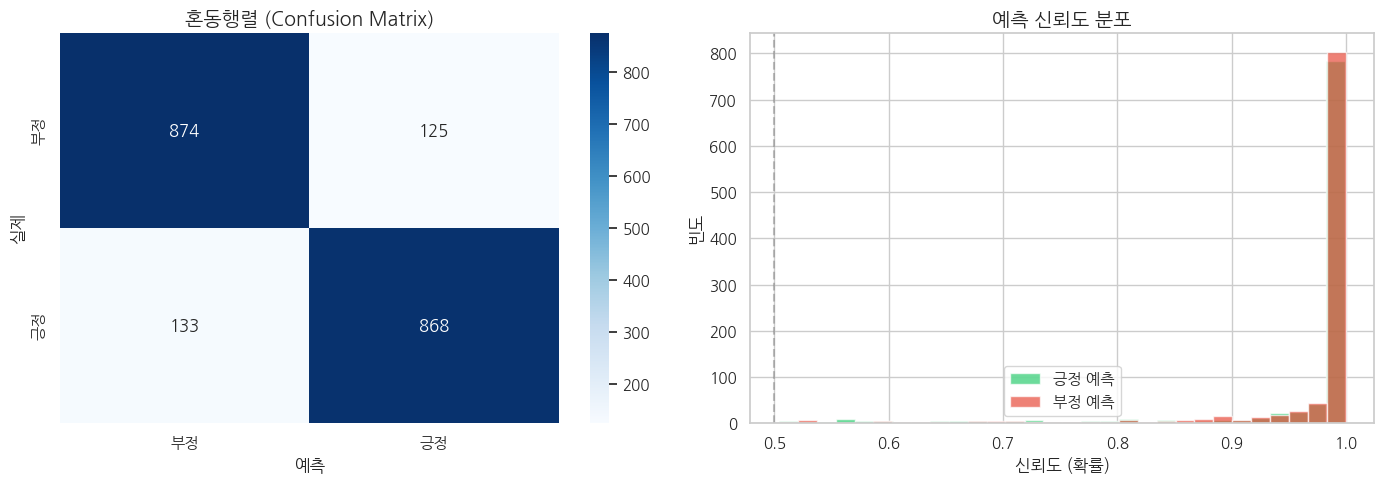

In [ ]:
# === 감성분석 결과 평가 ===
from sklearn.metrics import classification_report, confusion_matrix

# 예측 수행
predictions = trainer.predict(test_dataset)
preds = np.argmax(predictions.predictions, axis=-1)
probs = torch.softmax(torch.tensor(predictions.predictions), dim=-1).numpy()

print("=== 감성분석 성능 평가 ===")
print()
print(classification_report(
    test_labels_sub, preds,
    target_names=["부정", "긍정"],
    digits=4
))

# 혼동행렬 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 혼동행렬
cm = confusion_matrix(test_labels_sub, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=["부정", "긍정"], yticklabels=["부정", "긍정"])
axes[0].set_title("혼동행렬 (Confusion Matrix)", fontsize=14, fontweight='bold')
axes[0].set_xlabel("예측", fontsize=12)
axes[0].set_ylabel("실제", fontsize=12)

# 신뢰도 분포
axes[1].hist(probs[preds==1, 1], bins=30, alpha=0.7, label='긍정 예측', color='#2ecc71')
axes[1].hist(probs[preds==0, 0], bins=30, alpha=0.7, label='부정 예측', color='#e74c3c')
axes[1].set_title("예측 신뢰도 분포", fontsize=14, fontweight='bold')
axes[1].set_xlabel("신뢰도 (확률)", fontsize=12)
axes[1].set_ylabel("빈도", fontsize=12)
axes[1].legend(fontsize=11)
axes[1].axvline(x=0.5, color='gray', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


- 정확도는 87%대인데 신뢰도는 1.0 근처에 많이 몰려 있으므로, 모델이 실제보다 확신을 조금 과하게 주는(overconfident) 경향이 있을 가능성이 있다.

### 🔍 심화: 오답 분석 (Error Analysis)

> 모델 성능을 높이는 가장 빠른 길은 **어디서 왜 틀리는지** 아는 것을 확인하는게 중요합니다.

단순히 정확도 숫자만 보는 것이 아닌, 오답의 **패턴**을 분석합니다.  
이 과정을 통해 데이터 보강이나 전처리 개선의 방향을 찾을 수 있습니다.

#### 분석할 3가지 오답 유형

| 유형 | 정의 | 의미 | 대처 방법 |
|------|------|------|----------|
| **확신 오답** | 높은 확신도(>90%)로 틀린 케이스 | 모델의 근본적 약점 또는 레이블 오류 | 데이터 재검토, 특정 패턴 데이터 보강 |
| **불확신 오답** | 낮은 확신도(50~60%)로 틀린 케이스 | 데이터 자체가 모호하거나 경계에 위치 | 레이블 기준 명확화, 중립 클래스 추가 |
| **길이별 오답** | 짧거나 긴 텍스트에서 성능 저하 | BERT의 토큰 처리 특성과 관련 | 길이별 데이터 보강, max_length 조정 |

> 💡 **확신 오답이 특히 위험한 이유**: 모델이 틀렸음에도 "확신"하기 때문에  
> 실제 서비스에서 사용자에게 잘못된 정보를 **높은 신뢰도로** 전달할 수 있습니다.

#### 아래 코드가 생성하는 분석

1. **High Confidence Errors 표**: 확신도 상위 오답 샘플 — 실제 텍스트 직접 확인
2. **텍스트 길이별 정확도 그래프**: 짧은 문장 vs 긴 문장 성능 비교
3. **신뢰도 분포 히스토그램**: 맞춘 것 vs 틀린 것의 확신도 분포 비교
4. **Calibration 분석**: 모델이 "95% 확신"이라 말할 때 실제로 95%가 맞는지 확인


In [ ]:
# === 오답 분석 ===
print("=== 심화: 오답 분석 ===")
print()

# 1. 확신했지만 틀린 케이스 (High Confidence Errors)
confidence = np.max(probs, axis=1)
errors = preds != np.array(test_labels_sub)

high_conf_errors = np.where(errors & (confidence > 0.9))[0]
print(f"🔴 높은 확신으로 틀린 예측: {len(high_conf_errors)}개")
print("-" * 60)
for idx in high_conf_errors[:5]:
    actual = "긍정" if test_labels_sub[idx] == 1 else "부정"
    predicted = "긍정" if preds[idx] == 1 else "부정"
    print(f"  실제: {actual} | 예측: {predicted} (확신도: {confidence[idx]:.3f})")
    print(f"  텍스트: {test_texts_sub[idx][:70]}...")
    print()

# 2. 불확실한 예측 (Low Confidence)
uncertain = np.where((confidence < 0.6) & (confidence > 0.4))[0]
print(f"\n🟡 불확실한 예측 (0.4 < 확신도 < 0.6): {len(uncertain)}개")
print("-" * 60)
for idx in uncertain[:5]:
    actual = "긍정" if test_labels_sub[idx] == 1 else "부정"
    predicted = "긍정" if preds[idx] == 1 else "부정"
    correct = "✅" if actual == predicted else "❌"
    print(f"  {correct} 실제: {actual} | 예측: {predicted} (확신도: {confidence[idx]:.3f})")
    print(f"  텍스트: {test_texts_sub[idx][:70]}...")
    print()


=== 심화: 오답 분석 ===

🔴 높은 확신으로 틀린 예측: 168개
------------------------------------------------------------
  실제: 긍정 | 예측: 부정 (확신도: 0.996)
  텍스트: 게일 핸슨 때문에 끝까지 참고 봤다만......

  실제: 부정 | 예측: 긍정 (확신도: 0.986)
  텍스트: 그놈은메탈어쩌고저쩌고빨리끝났으면좋겠어요.왜냐햐면짜증나서...

  실제: 부정 | 예측: 긍정 (확신도: 0.998)
  텍스트: 제일 좋아하는 영화입니다!...

  실제: 긍정 | 예측: 부정 (확신도: 0.973)
  텍스트: 가나다라마바사아자차카타파하...

  실제: 부정 | 예측: 긍정 (확신도: 0.986)
  텍스트: 뻔한 이야기로도 정성들인 연기와 연출이면 어느정도는 볼만하게 만든다....


🟡 불확실한 예측 (0.4 < 확신도 < 0.6): 43개
------------------------------------------------------------
  ✅ 실제: 긍정 | 예측: 긍정 (확신도: 0.579)
  텍스트: 아 용준형진심개죠앙 . 너무잘생긴듯 근대 자꾸하연수랑 강하늘이랑 잇지말아여 슬퍼...

  ❌ 실제: 부정 | 예측: 긍정 (확신도: 0.520)
  텍스트: 제목하나만큼은 잘지었다....

  ✅ 실제: 긍정 | 예측: 긍정 (확신도: 0.504)
  텍스트: 개주인들만 알수잇는 고통.. 그리고 흑백대신 다음엔 컬러로도 리바이브해주세요...

  ✅ 실제: 긍정 | 예측: 긍정 (확신도: 0.536)
  텍스트: 생각해보니 키류멋지네...

  ❌ 실제: 긍정 | 예측: 부정 (확신도: 0.525)
  텍스트: 길들여지지않는 야생의 인간 문명에선 외계인으로밖에 표현이안되나,,...



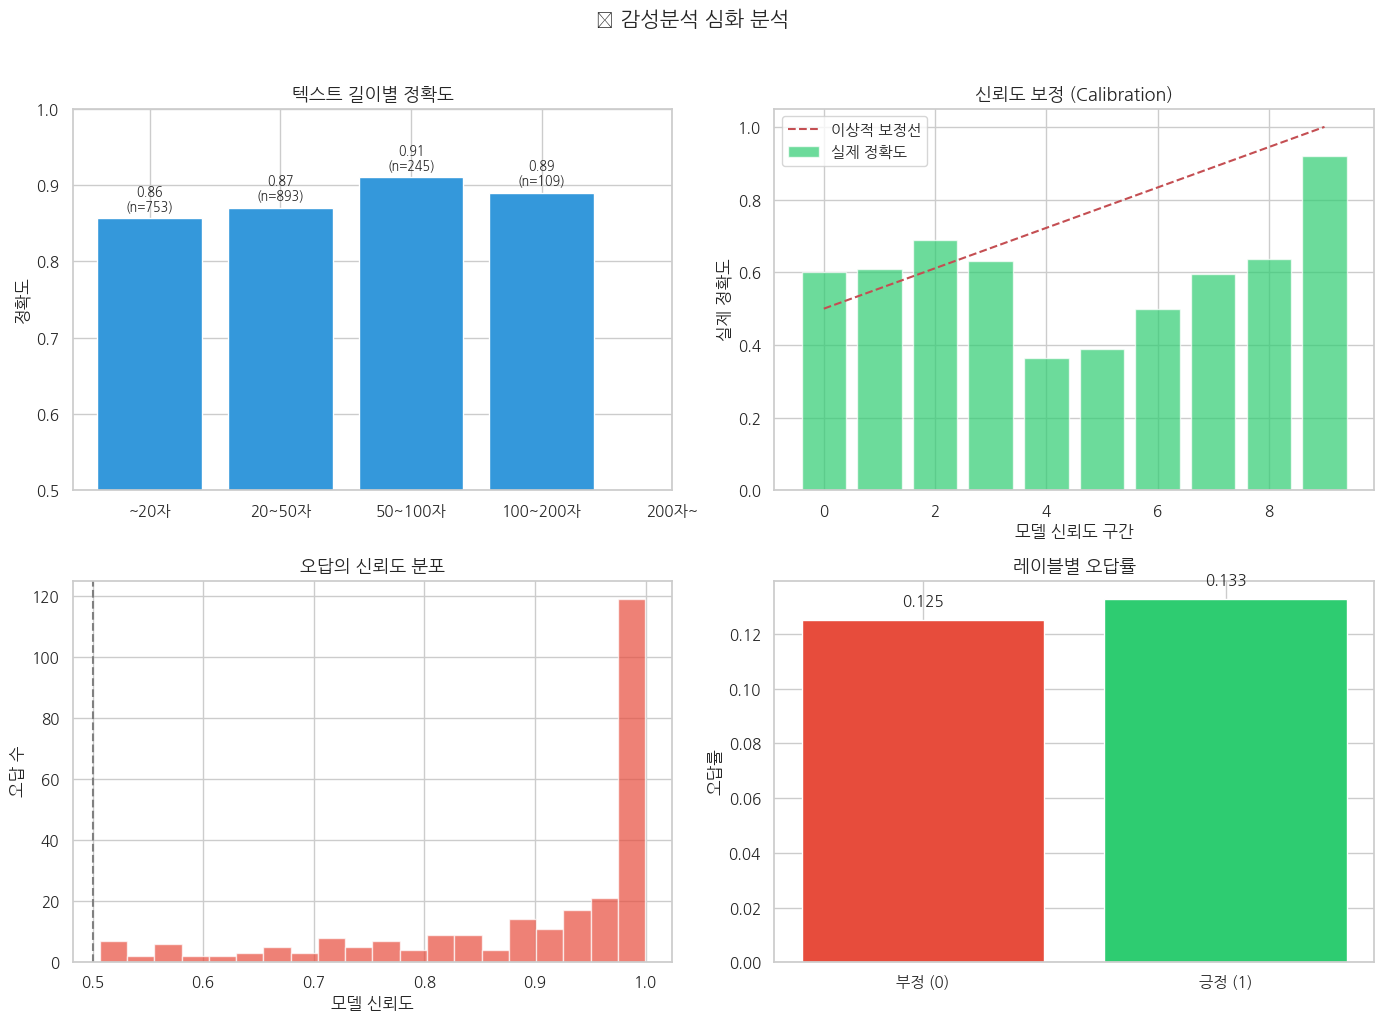


💡 분석 인사이트:
  - 가장 정확도 높은 길이대: 50~100자 (0.910)
  - 가장 정확도 낮은 길이대: ~20자 (0.857)
  - 높은 확신 오답 비율: 65.1%


In [ ]:
# === 텍스트 길이별 성능 + 신뢰도 심화 분석 ===
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) 텍스트 길이별 정확도
lengths = [len(t) for t in test_texts_sub]
length_bins = pd.cut(lengths, bins=[0, 20, 50, 100, 200, 500],
                      labels=['~20자', '20~50자', '50~100자', '100~200자', '200자~'])

df_analysis = pd.DataFrame({
    'length_bin': length_bins,
    'correct': ~errors,
    'confidence': confidence,
    'actual': test_labels_sub,
    'predicted': preds.tolist()
})

acc_by_len = df_analysis.groupby('length_bin')['correct'].mean()
count_by_len = df_analysis.groupby('length_bin')['correct'].count()

bars = axes[0,0].bar(range(len(acc_by_len)), acc_by_len.values, color='#3498db')
axes[0,0].set_xticks(range(len(acc_by_len)))
axes[0,0].set_xticklabels(acc_by_len.index, rotation=0)
axes[0,0].set_title("텍스트 길이별 정확도", fontsize=13, fontweight='bold')
axes[0,0].set_ylabel("정확도")
axes[0,0].set_ylim(0.5, 1.0)
for i, (v, c) in enumerate(zip(acc_by_len.values, count_by_len.values)):
    axes[0,0].text(i, v + 0.01, f"{v:.2f}\n(n={c})", ha='center', fontsize=9)

# 2) 신뢰도 vs 실제 정확도 (Calibration)
conf_bins = pd.cut(confidence, bins=10)
calibration = df_analysis.groupby(conf_bins)['correct'].agg(['mean', 'count'])

axes[0,1].bar(range(len(calibration)), calibration['mean'].values,
              color='#2ecc71', alpha=0.7, label='실제 정확도')
axes[0,1].plot(range(len(calibration)), np.linspace(0.5, 1.0, len(calibration)),
              'r--', label='이상적 보정선')
axes[0,1].set_title("신뢰도 보정 (Calibration)", fontsize=13, fontweight='bold')
axes[0,1].set_ylabel("실제 정확도")
axes[0,1].set_xlabel("모델 신뢰도 구간")
axes[0,1].legend()
axes[0,1].set_xticks(range(0, len(calibration), 2))

# 3) 오답의 신뢰도 분포
axes[1,0].hist(confidence[errors], bins=20, color='#e74c3c', alpha=0.7, edgecolor='white')
axes[1,0].set_title("오답의 신뢰도 분포", fontsize=13, fontweight='bold')
axes[1,0].set_xlabel("모델 신뢰도")
axes[1,0].set_ylabel("오답 수")
axes[1,0].axvline(x=0.5, color='gray', linestyle='--')

# 4) 긍정/부정별 오답률
error_by_label = df_analysis.groupby('actual').apply(
    lambda x: (~x['correct']).mean()
)
colors = ['#e74c3c', '#2ecc71']
axes[1,1].bar(['부정 (0)', '긍정 (1)'], error_by_label.values, color=colors)
axes[1,1].set_title("레이블별 오답률", fontsize=13, fontweight='bold')
axes[1,1].set_ylabel("오답률")
for i, v in enumerate(error_by_label.values):
    axes[1,1].text(i, v + 0.005, f"{v:.3f}", ha='center', fontsize=11)

plt.suptitle("📊 감성분석 심화 분석", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n💡 분석 인사이트:")
print(f"  - 가장 정확도 높은 길이대: {acc_by_len.idxmax()} ({acc_by_len.max():.3f})")
print(f"  - 가장 정확도 낮은 길이대: {acc_by_len.idxmin()} ({acc_by_len.min():.3f})")
print(f"  - 높은 확신 오답 비율: {len(high_conf_errors)/max(sum(errors),1)*100:.1f}%")


In [ ]:
# === 🎯 직접 감성분석 체험 ===
print("=== 직접 감성분석 체험 ===")
print()

# 다양한 테스트 문장
test_sentences = [
    "이 영화는 내 인생 최고의 영화다",
    "시간 낭비였다 다시는 안 본다",
    "그냥 그랬어요 보통이에요",
    "기대를 저버리지 않는 감독이다",        # 긍정인데 어려울 수 있음
    "역시 기대했던 대로 별로였다",           # 부정인데 어려울 수 있음
    "배우들 연기는 좋은데 스토리가 아쉽다",  # 혼합 감성
]

model.eval()
device = next(model.parameters()).device

for sent in test_sentences:
    inputs = tokenizer(sent, return_tensors='pt', truncation=True,
                       max_length=128, padding=True).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        prob = torch.softmax(outputs.logits, dim=-1)[0]

    pred = "긍정 👍" if prob[1] > prob[0] else "부정 👎"
    conf = max(prob[0].item(), prob[1].item())

    bar_pos = int(prob[1].item() * 20)
    bar = "█" * bar_pos + "░" * (20 - bar_pos)

    print(f"입력: {sent}")
    print(f"판정: {pred} (확신도: {conf:.3f})")
    print(f"부정 [{bar}] 긍정")
    print()


=== 직접 감성분석 체험 ===

입력: 이 영화는 내 인생 최고의 영화다
판정: 긍정 👍 (확신도: 0.998)
부정 [███████████████████░] 긍정

입력: 시간 낭비였다 다시는 안 본다
판정: 부정 👎 (확신도: 0.999)
부정 [░░░░░░░░░░░░░░░░░░░░] 긍정

입력: 그냥 그랬어요 보통이에요
판정: 부정 👎 (확신도: 0.998)
부정 [░░░░░░░░░░░░░░░░░░░░] 긍정

입력: 기대를 저버리지 않는 감독이다
판정: 긍정 👍 (확신도: 0.996)
부정 [███████████████████░] 긍정

입력: 역시 기대했던 대로 별로였다
판정: 부정 👎 (확신도: 0.999)
부정 [░░░░░░░░░░░░░░░░░░░░] 긍정

입력: 배우들 연기는 좋은데 스토리가 아쉽다
판정: 부정 👎 (확신도: 0.994)
부정 [░░░░░░░░░░░░░░░░░░░░] 긍정



---
# Part 3. 다중분류 (Multi-class Classification)

## 📖 다중분류란?

감성분석은 "긍정 vs 부정" 2가지 중 하나를 고르는 **이진분류**였습니다.  
다중분류는 **3개 이상의 카테고리** 중 하나를 선택하는 것입니다.

BERT 구조는 동일하지만, **마지막 분류 레이어의 출력 크기**가 다릅니다:
- 이진분류: 출력 2개 → `Softmax(2)` → [긍정 확률, 부정 확률]
- 다중분류: 출력 7개 → `Softmax(7)` → [경제%, 정치%, 스포츠%, ...]

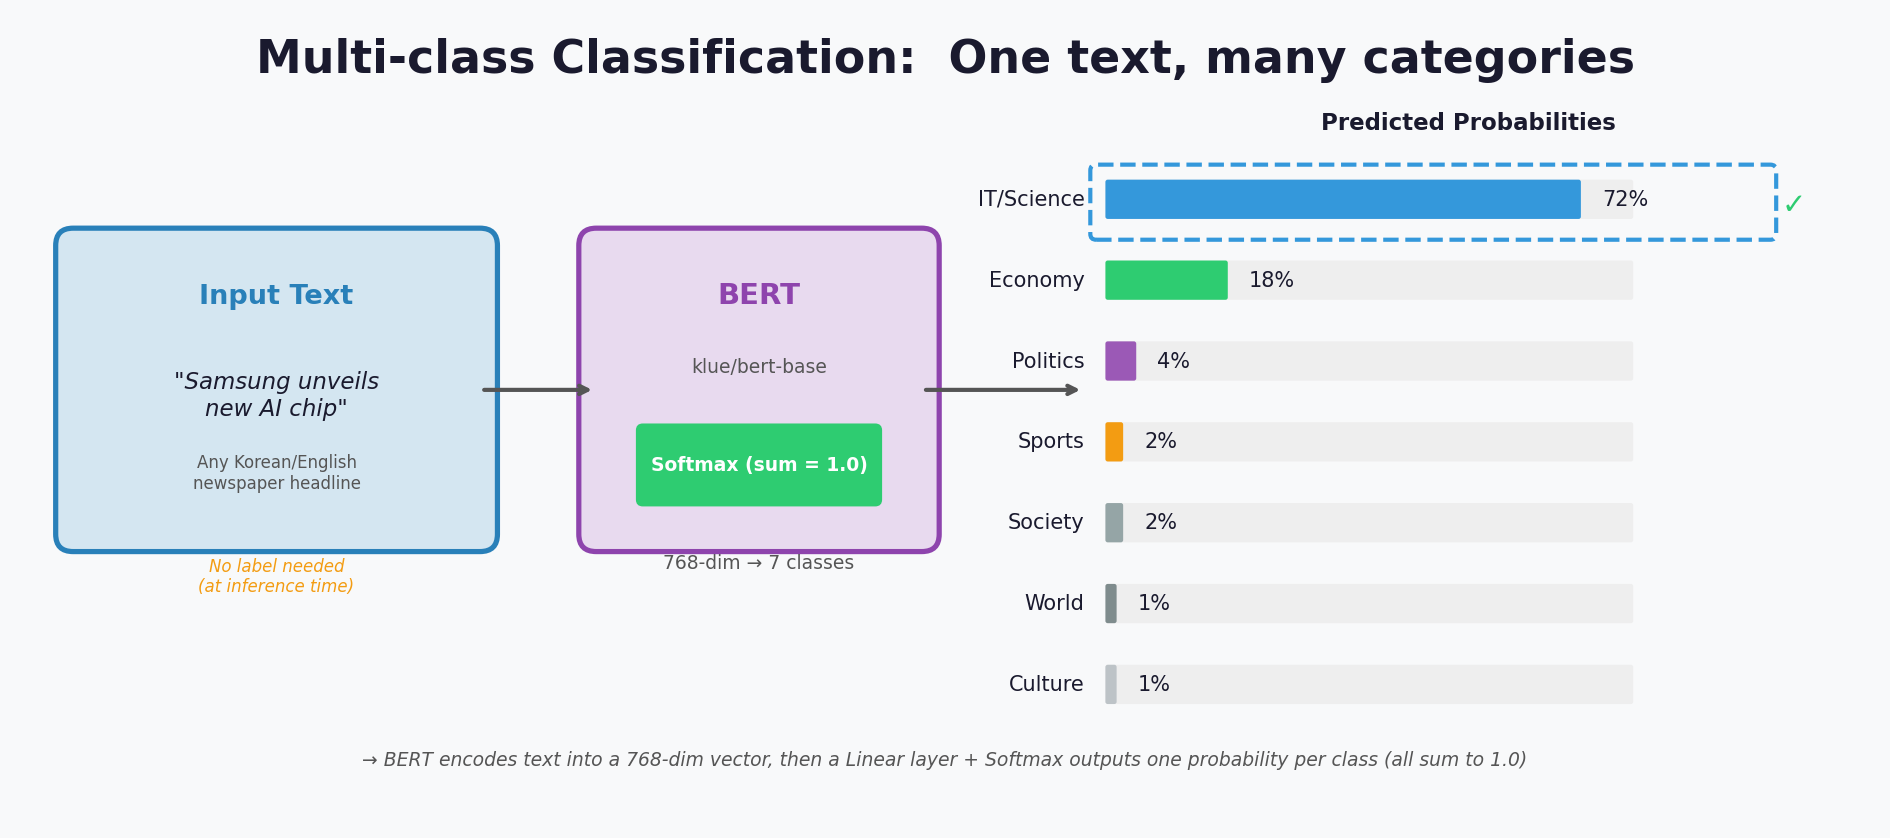

*▲ 다중분류: 하나의 텍스트를 여러 카테고리 중 하나로 분류*

위 다이어그램을 보면:
- **Input Text**: "Samsung unveils new AI chip" → IT/과학 관련 뉴스
- **BERT + Softmax**: 768차원 벡터를 7개 클래스 확률로 변환
- **예측 결과**: IT/Science 72%, Economy 18%, Politics 4% ... (모든 확률의 합 = 100%)
- **최종 예측**: 가장 높은 확률의 클래스 = "IT/Science" ✅


### 이진분류 vs 다중분류 비교

| 항목 | 이진분류 (감성분석) | 다중분류 (뉴스 분류) |
|------|---------------------|---------------------|
| 클래스 수 | 2개 (긍정/부정) | 7개 (경제/정치/스포츠...) |
| 출력층 활성화 | Sigmoid 또는 Softmax(2) | Softmax(7) |
| 손실함수 | Binary Cross-Entropy | Cross-Entropy |
| 주요 지표 | Accuracy, F1 | Macro-F1, Confusion Matrix |
| 예시 | 스팸 필터, 리뷰 분석 | 뉴스 분류, 의도 분류 |

> 💡 **Softmax란?** 여러 개의 값을 받아 **합이 1이 되는 확률 분포**로 변환합니다.  
> `[3.2, 1.1, -0.5]` → `[0.72, 0.24, 0.04]`  
> 가장 큰 값에 더 높은 확률이 배정됩니다 (지수 함수로 차이를 증폭).

> 🎯 **클래스 불균형 주의**: 뉴스 데이터는 "경제" 기사가 "생활문화" 기사보다 많을 수 있습니다.  
> 이런 경우 단순 Accuracy 대신 **Macro-F1 스코어**를 보는 것이 중요합니다.  
> Macro-F1은 각 클래스별 F1을 구한 뒤 평균 내어, 소수 클래스의 성능도 공평하게 반영합니다.


### 오늘 사용할 데이터: KLUE-YNAT (연합뉴스 토픽 분류)

| 항목 | 내용 |
|------|------|
| 출처 | 연합뉴스 헤드라인 (한국어) |
| 크기 | 학습 45,678건 + 검증 9,107건 |
| 카테고리 | IT/과학, 경제, 생활문화, 정치, 사회, 스포츠, 세계 (7개) |
| 특징 | KLUE 벤치마크 공식 데이터셋, 뉴스 헤드라인 특성상 짧은 문장 |
| 주의점 | 헤드라인만으로 판단하므로 맥락이 제한적 — 카테고리 경계가 모호한 경우 있음 |

> ⚡ **층화 추출 (Stratified Sampling)**: 각 카테고리의 비율을 유지하며 서브샘플링합니다.  
> 예: 전체에서 경제가 20%라면, 서브샘플에도 경제가 20%가 되도록 추출합니다.  
> 이렇게 해야 학습 데이터가 특정 카테고리에 치우치지 않습니다.

In [ ]:
# === GPU 메모리 정리 ===
# 감성분석 모델을 CPU로 이동하여 GPU VRAM 확보 (보너스 셀에서 재사용)
model.cpu()
del trainer
torch.cuda.empty_cache() if torch.cuda.is_available() else None
print("✅ 감성분석 모델 → CPU 이동 완료 (GPU VRAM 확보)")
print()

# === 다중분류 데이터 준비 ===
from datasets import load_dataset

# KLUE-TC (Topic Classification) 또는 자체 뉴스 카테고리 데이터 사용
print("=== 뉴스 카테고리 분류 데이터 준비 ===")
print()

# KLUE-YNAT (연합뉴스 토픽 분류) 데이터셋 로드
dataset_ynat = load_dataset("klue", "ynat")

# 카테고리 매핑
label_names = {
    0: "IT/과학", 1: "경제", 2: "사회", 3: "생활/문화",
    4: "세계", 5: "스포츠", 6: "정치"
}

print(f"학습 데이터: {len(dataset_ynat['train']):,}개")
print(f"검증 데이터: {len(dataset_ynat['validation']):,}개")
print(f"카테고리: {len(label_names)}개")
print()

# 카테고리별 분포
from collections import Counter
label_dist = Counter(dataset_ynat['train']['label'])
print("--- 카테고리별 분포 ---")
for label_id in sorted(label_dist.keys()):
    name = label_names[label_id]
    count = label_dist[label_id]
    bar = "█" * (count // 1000)
    print(f"  {name:8s} | {bar} {count:,}개")

# 샘플 확인
print("\n--- 데이터 샘플 ---")
for i in range(7):
    row = dataset_ynat['train'][i * 5000]
    print(f"  [{label_names[row['label']]:8s}] {row['title'][:55]}...")


✅ 감성분석 모델 → CPU 이동 완료 (GPU VRAM 확보)

=== 뉴스 카테고리 분류 데이터 준비 ===



README.md: 0.00B [00:00, ?B/s]

ynat/train-00000-of-00001.parquet:   0%|          | 0.00/4.17M [00:00<?, ?B/s]

ynat/validation-00000-of-00001.parquet:   0%|          | 0.00/847k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/45678 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/9107 [00:00<?, ? examples/s]

학습 데이터: 45,678개
검증 데이터: 9,107개
카테고리: 7개

--- 카테고리별 분포 ---
  IT/과학    | █████ 5,235개
  경제       | ██████ 6,118개
  사회       | █████ 5,133개
  생활/문화    | █████ 5,751개
  세계       | ████████ 8,320개
  스포츠      | ███████ 7,742개
  정치       | ███████ 7,379개

--- 데이터 샘플 ---
  [생활/문화   ] 유튜브 내달 2일까지 크리에이터 지원 공간 운영...
  [스포츠     ] 월드컵 유니폼 입어본 선수들 가볍고 편하다...
  [경제      ] SKT AI 누구로 스타벅스 커피 주문한다…연내 서비스 개발...
  [세계      ] 폼페이오 방러 전 브뤼셀서 이란문제 논의…전쟁이 목표 아냐종합...
  [IT/과학   ] 몸집 큰 육식 공룡은 뿔 난 경우 많아...
  [경제      ] 집 팔까 증여할까…종부세에 놀란 다주택자 절세 상담 줄이어종합...
  [경제      ] 英 공직자 경제통계 사전열람 막자 시장 이상변동 줄어...


In [ ]:
# === 다중분류 데이터 전처리 ===
# Colab에서 무리 없이 돌아가도록 서브샘플링
TRAIN_SIZE_MC = 8000   # 카테고리당 ~1,140개
TEST_SIZE_MC = 1400    # 카테고리당 ~200개

np.random.seed(42)

# 층화 추출 (Stratified Sampling) — 각 카테고리 비율 유지
from sklearn.model_selection import train_test_split

mc_texts = [clean_text(row['title']) for row in dataset_ynat['train']]
mc_labels = [row['label'] for row in dataset_ynat['train']]

# 빈 텍스트 제거
valid_idx = [i for i, t in enumerate(mc_texts) if len(t) > 0]
mc_texts = [mc_texts[i] for i in valid_idx]
mc_labels = [mc_labels[i] for i in valid_idx]

# 층화 서브샘플링
mc_train_texts, mc_temp_texts, mc_train_labels, mc_temp_labels = train_test_split(
    mc_texts, mc_labels, train_size=TRAIN_SIZE_MC, stratify=mc_labels, random_state=42
)

mc_test_texts = [clean_text(row['title']) for row in dataset_ynat['validation'] if clean_text(row['title'])]
mc_test_labels = [row['label'] for row in dataset_ynat['validation'] if clean_text(row['title'])]

# 테스트도 서브샘플
if len(mc_test_texts) > TEST_SIZE_MC:
    mc_test_texts, _, mc_test_labels, _ = train_test_split(
        mc_test_texts, mc_test_labels, train_size=TEST_SIZE_MC,
        stratify=mc_test_labels, random_state=42
    )

print(f"학습: {len(mc_train_texts):,}개, 테스트: {len(mc_test_texts):,}개")

# 토큰화
mc_train_dataset = TextClassificationDataset(mc_train_texts, mc_train_labels, tokenizer, max_len=64)
mc_test_dataset = TextClassificationDataset(mc_test_texts, mc_test_labels, tokenizer, max_len=64)

print(f"✅ 토큰화 완료 (max_len=64, 뉴스 제목은 짧으므로)")


학습: 8,000개, 테스트: 1,400개
✅ 토큰화 완료 (max_len=64, 뉴스 제목은 짧으므로)


In [ ]:
# 토큰화 결과 확인
sample = mc_train_dataset[0]
print(f"\n--- 토큰화 예시 ---")
print(f"원문: {mc_train_texts[0]}")
decoded = tokenizer.decode(sample['input_ids'], skip_special_tokens=False)
print(f"토큰 복원: {decoded[:80]}...")
print(f"레이블: {sample['labels'].item()}")


--- 토큰화 예시 ---
원문: 해외미디어 독자 맞춤형 서비스로 구독 수익 늘리는 신문
토큰 복원: [CLS] 해외미디어 독자 맞춤형 서비스로 구독 수익 늘리는 신문 [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [...
레이블: 4


In [ ]:
# === 다중분류 모델 학습 ===
from transformers import AutoModelForSequenceClassification

# 7개 카테고리 분류 모델
model_mc = AutoModelForSequenceClassification.from_pretrained(
    "klue/bert-base",
    num_labels=7
)

training_args_mc = TrainingArguments(
    output_dir="./multiclass_model",
    num_train_epochs=3,  # Colab GPU 기준 ~5분 소요
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    warmup_steps=100,
    weight_decay=0.01,
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none",
    fp16=torch.cuda.is_available(),
)

def compute_metrics_mc(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, average='weighted')
    return {"accuracy": acc, "f1": f1}

trainer_mc = Trainer(
    model=model_mc,
    args=training_args_mc,
    train_dataset=mc_train_dataset,
    eval_dataset=mc_test_dataset,
    compute_metrics=compute_metrics_mc,
)

print("=== 다중분류 모델 학습 시작 ===")
print(f"모델: klue/bert-base (7-class)")
print(f"카테고리: {', '.join(label_names.values())}")
print()

# ⏱️ Colab T4 GPU 기준 약 3~5분 소요
trainer_mc.train()
print("\n✅ 학습 완료!")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: klue/bert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on you

=== 다중분류 모델 학습 시작 ===
모델: klue/bert-base (7-class)
카테고리: IT/과학, 경제, 사회, 생활/문화, 세계, 스포츠, 정치



Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.453925,0.475356,0.847143,0.846869
2,0.315966,0.438756,0.859286,0.859051
3,0.125601,0.479312,0.854286,0.854019


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La


✅ 학습 완료!


=== 다중분류 성능 평가 ===

              precision    recall  f1-score   support

       IT/과학     0.7912    0.8471    0.8182        85
          경제     0.8303    0.8744    0.8518       207
          사회     0.8734    0.8489    0.8610       569
       생활/문화     0.8726    0.8768    0.8747       211
          세계     0.8750    0.8203    0.8468       128
         스포츠     0.8614    0.9775    0.9158        89
          정치     0.8381    0.7928    0.8148       111

    accuracy                         0.8579      1400
   macro avg     0.8489    0.8625    0.8547      1400
weighted avg     0.8585    0.8579    0.8576      1400



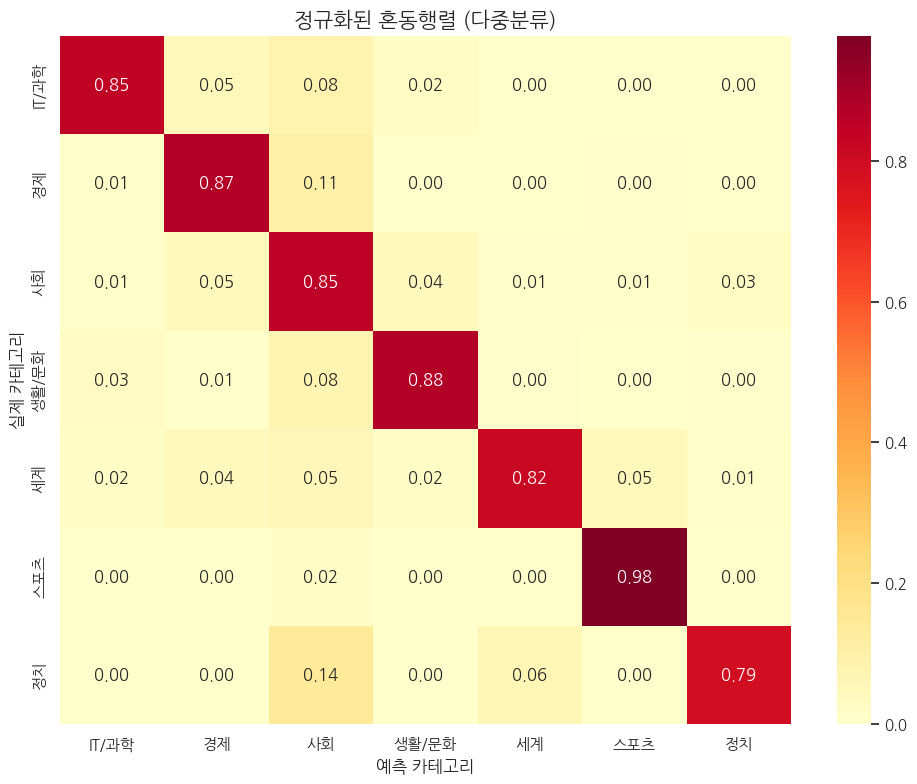


💡 혼동행렬 읽는 법:
  - 대각선 값이 높을수록 좋음 (올바른 예측)
  - 대각선 밖의 높은 값 = 자주 혼동하는 카테고리 쌍


In [ ]:
# === 다중분류 결과 평가 ===
preds_mc = trainer_mc.predict(mc_test_dataset)
pred_labels_mc = np.argmax(preds_mc.predictions, axis=-1)
probs_mc = torch.softmax(torch.tensor(preds_mc.predictions), dim=-1).numpy()

print("=== 다중분류 성능 평가 ===")
print()
print(classification_report(
    mc_test_labels, pred_labels_mc,
    target_names=list(label_names.values()),
    digits=4
))

# 혼동행렬 시각화
fig, ax = plt.subplots(figsize=(10, 8))
cm_mc = confusion_matrix(mc_test_labels, pred_labels_mc)
cm_normalized = cm_mc.astype('float') / cm_mc.sum(axis=1)[:, np.newaxis]

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='YlOrRd', ax=ax,
            xticklabels=list(label_names.values()),
            yticklabels=list(label_names.values()))
ax.set_title("정규화된 혼동행렬 (다중분류)", fontsize=15, fontweight='bold')
ax.set_xlabel("예측 카테고리", fontsize=12)
ax.set_ylabel("실제 카테고리", fontsize=12)
plt.tight_layout()
plt.show()

print("\n💡 혼동행렬 읽는 법:")
print("  - 대각선 값이 높을수록 좋음 (올바른 예측)")
print("  - 대각선 밖의 높은 값 = 자주 혼동하는 카테고리 쌍")


### 🔍 심화: 오분류 패턴 분석

혼동행렬에서 한 단계 더 들어가, **어떤 카테고리끼리 왜 혼동하는지** 패턴을 분석합니다.

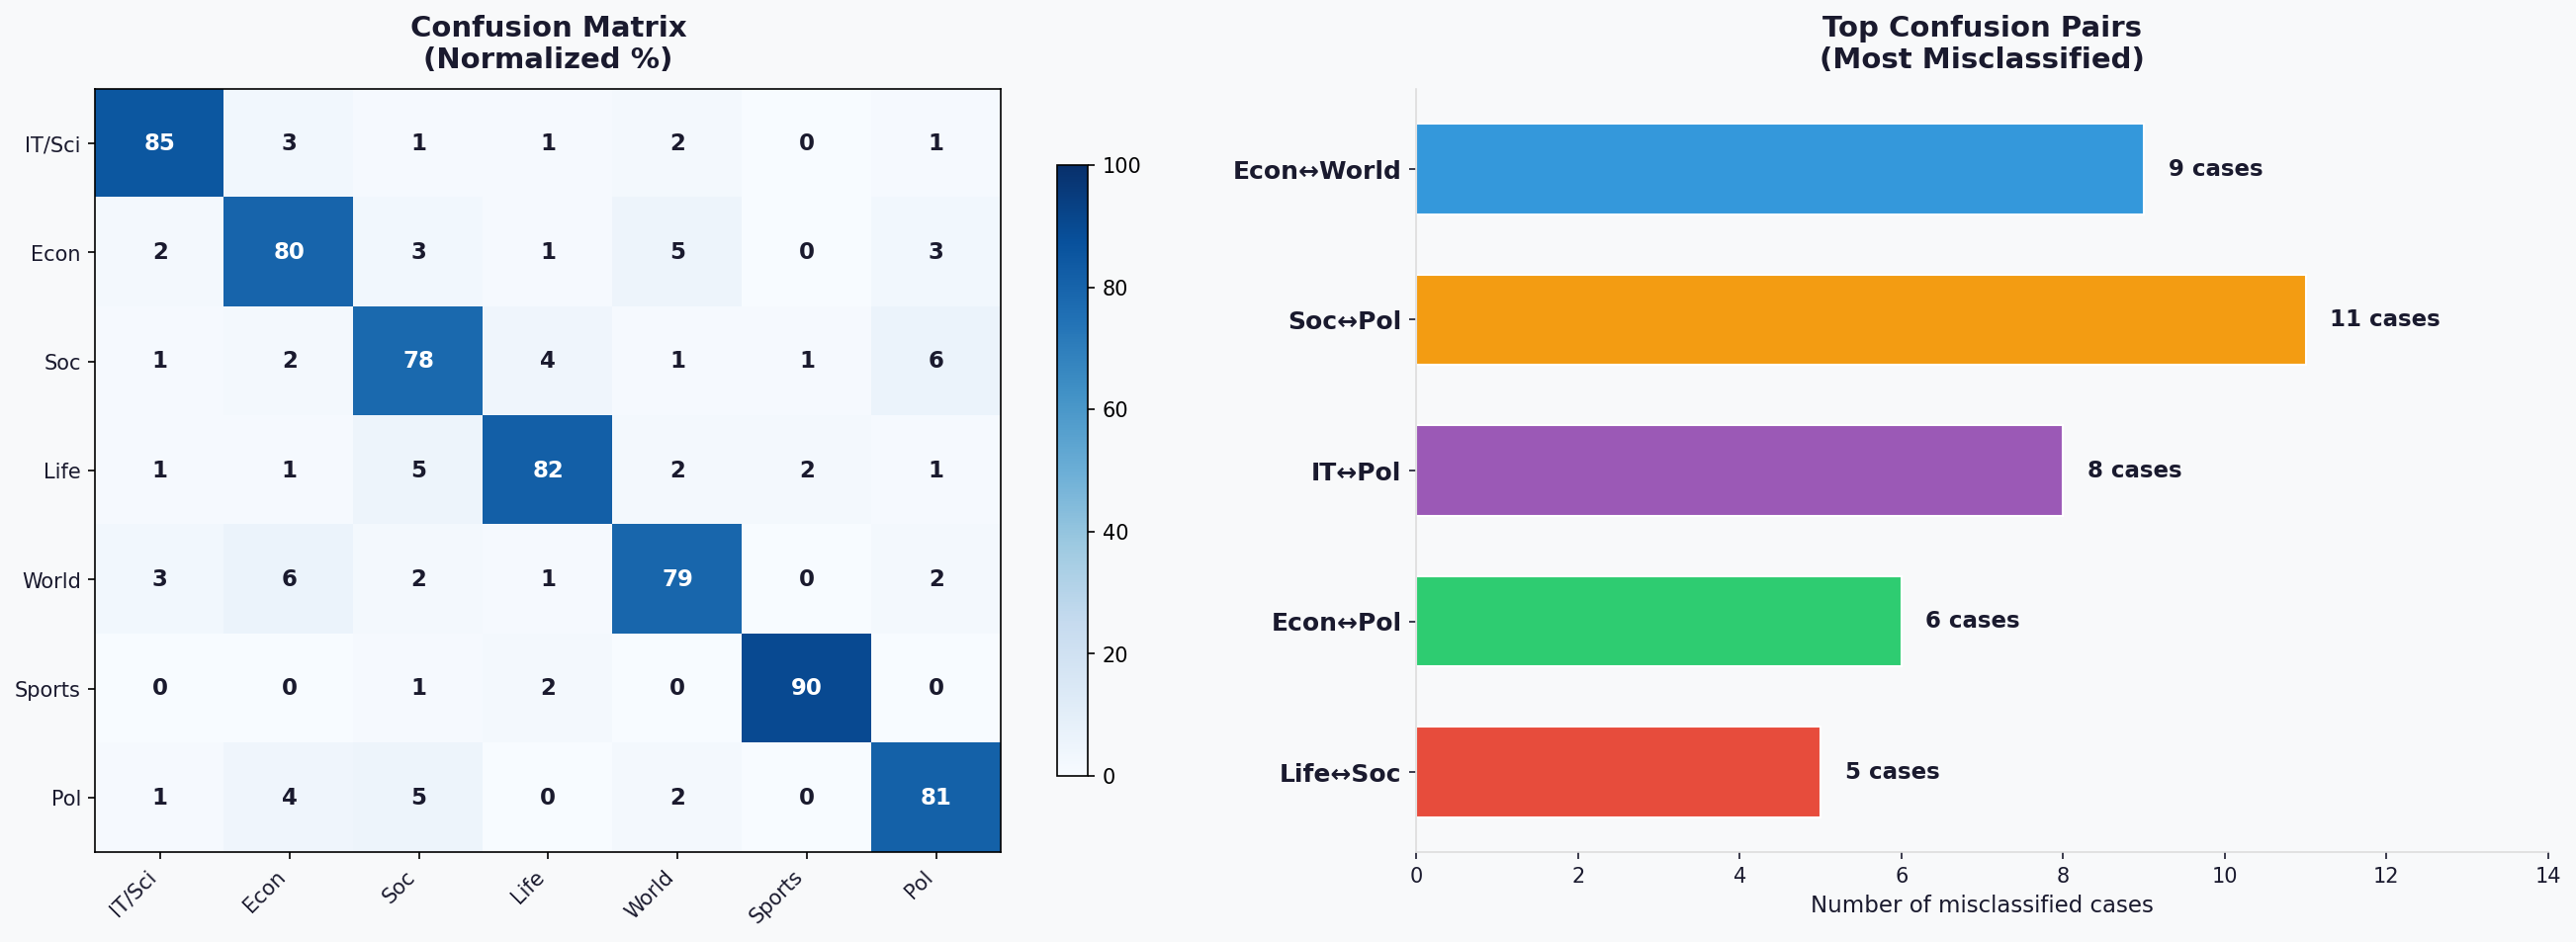

*▲ 오분류 패턴 분석: 혼동행렬 (좌) + 상위 혼동 카테고리 쌍 (우)*

#### 혼동행렬(Confusion Matrix) 읽는 법

```
        [예측 경제] [예측 정치] [예측 스포츠] ...
[실제 경제]  85건      8건        0건         ← 행: 실제 클래스
[실제 정치]   6건     78건        1건
[실제 스포츠] 0건      2건       91건
```
- **대각선** (좌상→우하): 올바르게 분류된 경우 — **높을수록 좋음**
- **비대각선**: 혼동이 발생한 경우 — 특히 큰 숫자에 주목
- **행 합산**: 실제 해당 클래스의 총 개수
- **열 합산**: 해당 클래스로 예측된 총 개수

#### 분석 방향

| 분석 | 무엇을 보나? | 어떻게 활용하나? |
|------|-------------|----------------|
| **혼동행렬** | 행=실제, 열=예측 → 대각선이 높을수록 좋음 | 전체 오류 패턴 파악 |
| **혼동 쌍 발굴** | 경제↔세계, 사회↔정치 처럼 의미적으로 겹치는 쌍 | 데이터 보강 방향 결정 |
| **오분류 텍스트** | 실제로 어떤 문장이 헷갈렸는지 직접 확인 | 레이블 기준 재검토 |

> 💡 **왜 특정 카테고리끼리 혼동할까?**  
> `"삼성전자 주가"` → 경제? IT/과학? 둘 다 맞는 것 같습니다.  
> `"대통령, 법 개정안 서명"` → 정치? 사회? 경계가 애매합니다.  
> **뉴스 헤드라인**은 실제로 카테고리 경계가 모호한 경우가 많아,  
> 인간 레이블러도 동의하지 않는 케이스가 존재합니다.  
> 이런 경우 오답이 반드시 "모델의 문제"가 아닐 수 있습니다.

In [ ]:
# === 오분류 패턴 심화 분석 ===
print("=== 오분류 패턴 분석 ===")
print()

# 1. 가장 많이 혼동하는 카테고리 쌍 찾기
confusion_pairs = []
for i in range(7):
    for j in range(7):
        if i != j and cm_mc[i][j] > 0:
            confusion_pairs.append((label_names[i], label_names[j], cm_mc[i][j]))

confusion_pairs.sort(key=lambda x: -x[2])

print("📊 가장 많이 혼동하는 카테고리 쌍 (Top 5):")
print("-" * 55)
for actual, predicted, count in confusion_pairs[:5]:
    print(f"  {actual:8s} → {predicted:8s} : {count}건")

# 2. 각 혼동 쌍의 실제 오분류 텍스트 예시
print()
print("📝 혼동 사례 상세:")
print("=" * 60)

top_pair = confusion_pairs[0]
actual_label = [k for k, v in label_names.items() if v == top_pair[0]][0]
pred_label = [k for k, v in label_names.items() if v == top_pair[1]][0]

examples = []
for i, (true, pred) in enumerate(zip(mc_test_labels, pred_labels_mc)):
    if true == actual_label and pred == pred_label:
        examples.append((mc_test_texts[i], probs_mc[i]))

print(f"\n[{top_pair[0]} → {top_pair[1]}으로 잘못 분류된 사례]")
for text, prob in examples[:5]:
    top3_idx = np.argsort(prob)[::-1][:3]
    top3 = [(label_names[idx], prob[idx]) for idx in top3_idx]
    print(f"  텍스트: {text[:60]}...")
    print(f"  Top-3: {' | '.join([f'{n}: {p:.2f}' for n, p in top3])}")
    print()


=== 오분류 패턴 분석 ===

📊 가장 많이 혼동하는 카테고리 쌍 (Top 5):
-------------------------------------------------------
  사회       → 경제       : 26건
  사회       → 생활/문화    : 23건
  경제       → 사회       : 22건
  생활/문화    → 사회       : 16건
  정치       → 사회       : 16건

📝 혼동 사례 상세:

[사회 → 경제으로 잘못 분류된 사례]
  텍스트: 현대해상 주총서 조용일 이성재 대표 선임...
  Top-3: 경제: 0.85 | 사회: 0.14 | IT/과학: 0.00

  텍스트: 화이브라더스 특수효과 업체 매드맨 인수...
  Top-3: 경제: 0.89 | IT/과학: 0.04 | 사회: 0.04

  텍스트: 신년사 한창수 아시아나 사장 새로운 시작 수익성 개선 과제...
  Top-3: 경제: 0.81 | 사회: 0.17 | IT/과학: 0.01

  텍스트: 4대 그룹 내년 사업계획 키워드는 위기 속 기회 모색...
  Top-3: 경제: 0.84 | 사회: 0.14 | IT/과학: 0.01

  텍스트: 시노펙스 손경익 이진희 대표이사 체제로 변경...
  Top-3: 경제: 0.92 | 사회: 0.06 | 세계: 0.01



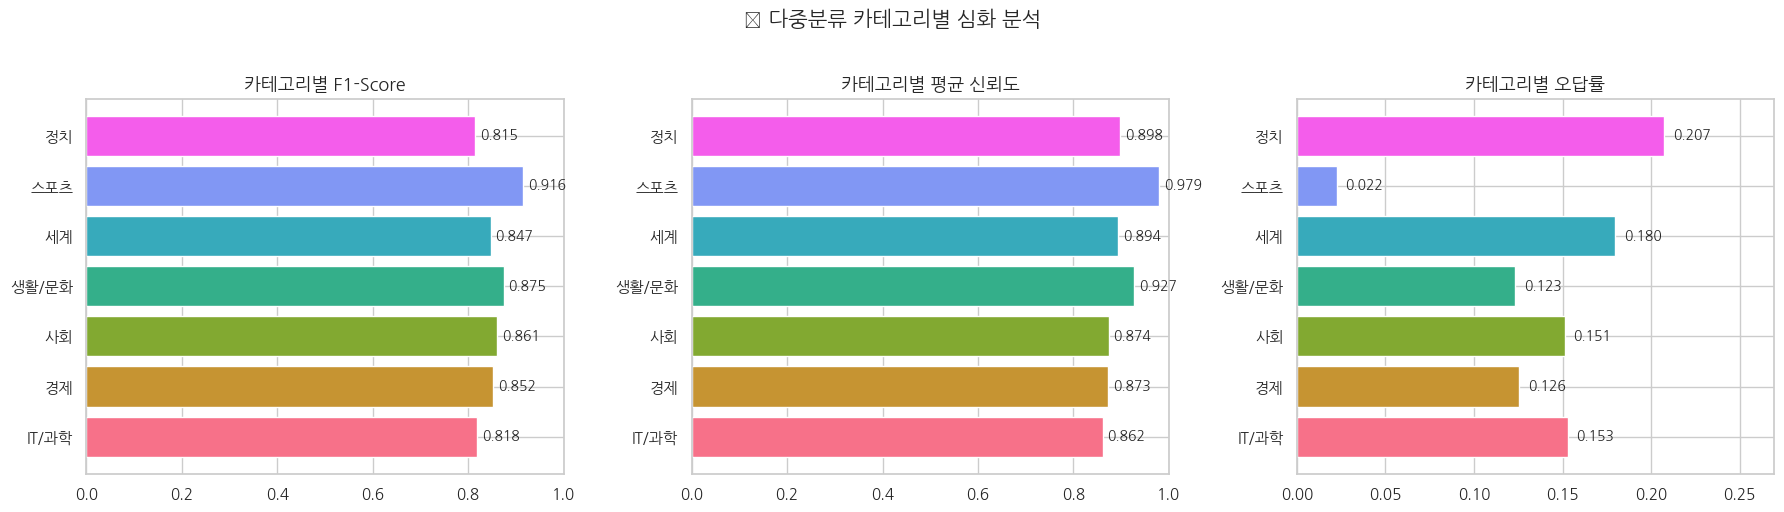


💡 분석 인사이트:
  - 가장 잘 분류하는 카테고리: 스포츠 (F1: 0.916)
  - 가장 어려운 카테고리: 정치 (F1: 0.815)
  - 정치 카테고리가 어려운 이유를 위 혼동 사례에서 확인하세요!


In [ ]:
# === 카테고리별 신뢰도 + 성능 심화 시각화 ===
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) 카테고리별 F1-score
from sklearn.metrics import f1_score as f1_per_class
f1_per = f1_score(mc_test_labels, pred_labels_mc, average=None)

colors = sns.color_palette('husl', 7)
bars = axes[0].barh(list(label_names.values()), f1_per, color=colors)
axes[0].set_title("카테고리별 F1-Score", fontsize=13, fontweight='bold')
axes[0].set_xlim(0, 1)
for i, v in enumerate(f1_per):
    axes[0].text(v + 0.01, i, f"{v:.3f}", va='center', fontsize=10)

# 2) 카테고리별 평균 신뢰도
avg_conf_per_class = []
for c in range(7):
    mask = np.array(mc_test_labels) == c
    if mask.sum() > 0:
        avg_conf_per_class.append(np.max(probs_mc[mask], axis=1).mean())
    else:
        avg_conf_per_class.append(0)

axes[1].barh(list(label_names.values()), avg_conf_per_class, color=colors)
axes[1].set_title("카테고리별 평균 신뢰도", fontsize=13, fontweight='bold')
axes[1].set_xlim(0, 1)
for i, v in enumerate(avg_conf_per_class):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va='center', fontsize=10)

# 3) 카테고리별 오답률
error_per_class = []
for c in range(7):
    mask = np.array(mc_test_labels) == c
    if mask.sum() > 0:
        error_per_class.append((pred_labels_mc[mask] != c).mean())
    else:
        error_per_class.append(0)

axes[2].barh(list(label_names.values()), error_per_class, color=colors)
axes[2].set_title("카테고리별 오답률", fontsize=13, fontweight='bold')
axes[2].set_xlim(0, max(error_per_class) * 1.3)
for i, v in enumerate(error_per_class):
    axes[2].text(v + 0.005, i, f"{v:.3f}", va='center', fontsize=10)

plt.suptitle("📊 다중분류 카테고리별 심화 분석", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 인사이트 요약
best_cat = list(label_names.values())[np.argmax(f1_per)]
worst_cat = list(label_names.values())[np.argmin(f1_per)]
print(f"\n💡 분석 인사이트:")
print(f"  - 가장 잘 분류하는 카테고리: {best_cat} (F1: {max(f1_per):.3f})")
print(f"  - 가장 어려운 카테고리: {worst_cat} (F1: {min(f1_per):.3f})")
print(f"  - {worst_cat} 카테고리가 어려운 이유를 위 혼동 사례에서 확인하세요!")


---
# Part 4. 토픽모델링 (Topic Modeling)

## 📖 토픽모델링이란?

앞의 감성분석/다중분류는 **레이블이 있는** 지도학습이었습니다.  
토픽모델링은 **레이블 없이** 문서 집합에서 숨겨진 주제를 자동으로 발견하는 **비지도학습**입니다.

> 📌 "이 1,000개의 뉴스 기사들은 어떤 주제들로 구성되어 있을까?" 라는 질문에 자동으로 답합니다.

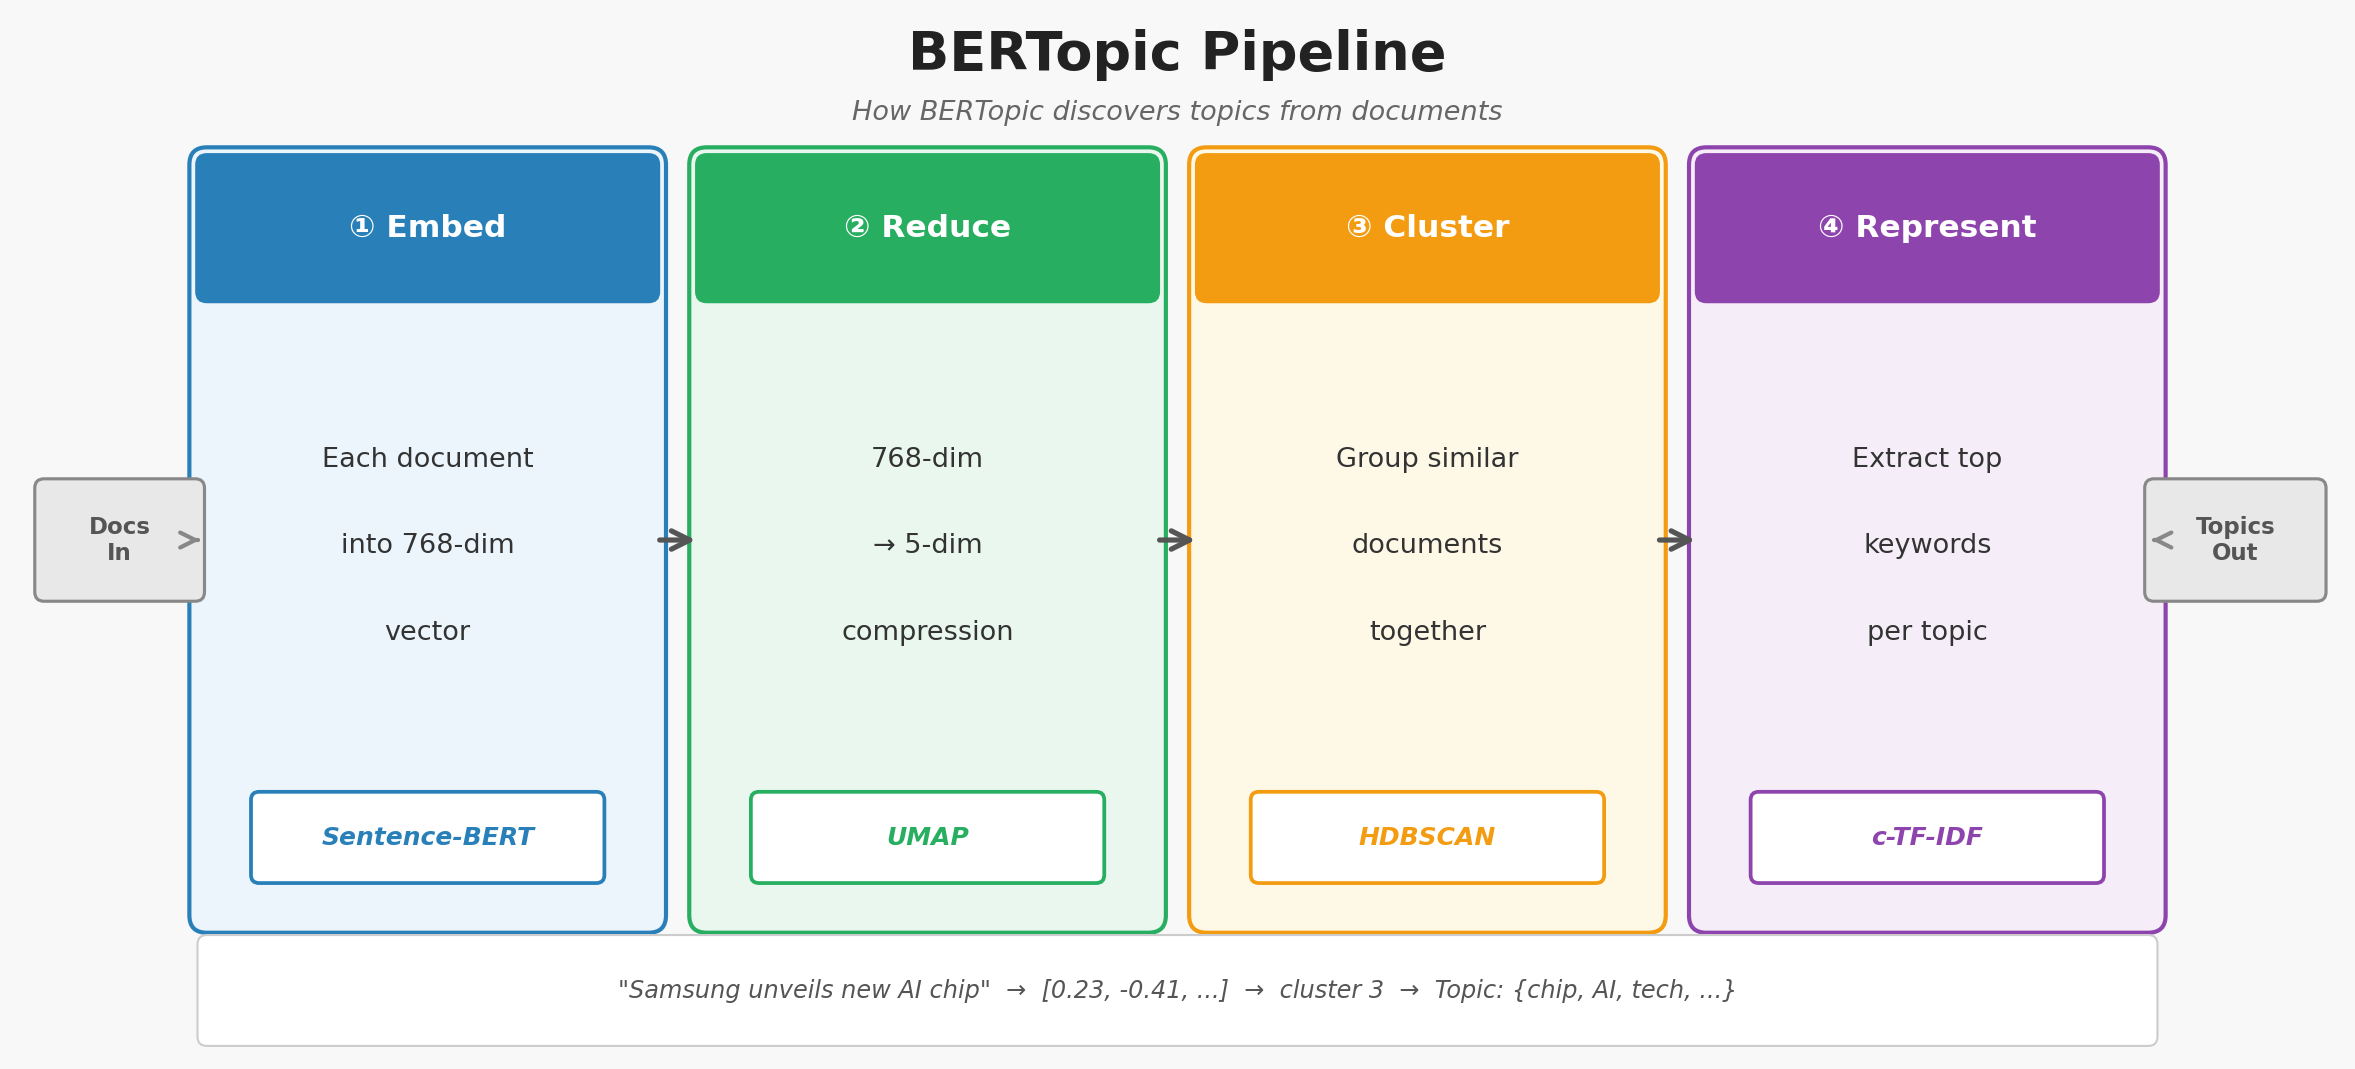

위 다이어그램의 4단계를 자세히 살펴보겠습니다:

| 단계 | 방법 | 역할 | 왜 이 방법을? |
|------|------|------|--------------|
| **① Embed** | Sentence-Transformers | 각 문서를 768차원 벡터로 변환 | BERT 임베딩으로 **의미**를 파악 |
| **② Reduce** | UMAP | 768차원 → 2~5차원으로 압축 | 고차원에서 클러스터링 어려움 (차원의 저주) |
| **③ Cluster** | HDBSCAN | 비슷한 문서들을 하나의 그룹으로 묶음 | 토픽 수를 미리 지정할 필요 없음! |
| **④ Keywords** | c-TF-IDF | 각 클러스터의 대표 키워드 추출 | 각 토픽이 어떤 주제인지 파악 |


### 지도학습 vs 비지도학습

| 항목 | 감성분석/다중분류 (지도학습) | 토픽모델링 (비지도학습) |
|------|--------------------------|----------------------|
| 레이블 | 필요 (긍정/부정, 카테고리) | **불필요** |
| 목적 | 정해진 카테고리로 분류 | 숨겨진 주제를 발견 |
| 결과 | "이 문서는 경제 뉴스 (95%)" | "이 문서들에는 5개 주제가 있다" |
| 장점 | 높은 정확도, 명확한 클래스 | 레이블 없이도 분석 가능, 새로운 발견 가능 |
| 단점 | 레이블링 비용 발생 | 토픽 해석이 주관적일 수 있음 |

> 💡 **언제 토픽모델링을 쓸까?**  
> 수천 개의 고객 불만 이메일을 분석할 때, 일일이 읽지 않고도  
> "환불 관련", "배송 지연", "제품 불량" 같은 주요 이슈를 자동으로 발견할 수 있습니다.


### BERTopic: 최신 토픽모델링

오늘은 **BERTopic**을 사용합니다. 전통적인 LDA 대비 장점:

| 특성 | LDA (전통 방법) | BERTopic (최신) |
|------|----------------|----------------|
| 임베딩 | 단어 빈도 기반 (TF-IDF) | BERT 임베딩 (문맥/의미 기반) |
| 토픽 수 | **사전 지정 필요** | **자동 결정** (데이터에서 학습) |
| 토픽 표현 | 단어 확률 분포 | 핵심 키워드 + c-TF-IDF 점수 |
| 한국어 지원 | 형태소 분석 필수 | 임베딩 모델이 알아서 처리 |
| 속도 | 빠름 | 임베딩 단계에서 다소 느림 |

> ⚠️ **HDBSCAN의 특성**: 모든 문서가 토픽에 배정되지 않을 수 있습니다.  
> 노이즈로 판단된 문서는 `-1` (Outlier) 토픽으로 분류됩니다.  
> 이는 버그가 아니라 HDBSCAN의 정상 동작입니다 — 명확한 주제가 없는 문서는 제외합니다.

In [ ]:
# === GPU 메모리 정리 ===
# 다중분류 모델을 CPU로 이동하여 GPU VRAM 확보 (보너스 셀에서 재사용)
model_mc.cpu()
del trainer_mc
torch.cuda.empty_cache() if torch.cuda.is_available() else None
print("✅ 다중분류 모델 → CPU 이동 완료 (GPU VRAM 확보)")
print()

# === 토픽모델링 데이터 준비 ===
print("=== 토픽모델링 데이터 준비 ===")
print("KLUE-YNAT 뉴스 제목 데이터를 활용합니다.")
print("(레이블은 있지만 토픽모델링에서는 사용하지 않습니다 — 나중에 비교용으로만!)")
print()

# 다양한 토픽을 위해 충분한 데이터 사용
TOPIC_SIZE = 5000

np.random.seed(42)
topic_idx = np.random.choice(len(mc_texts), min(TOPIC_SIZE, len(mc_texts)), replace=False)
topic_texts = [mc_texts[i] for i in topic_idx]
topic_true_labels = [mc_labels[i] for i in topic_idx]  # 비교용으로만 보관

print(f"토픽모델링 대상 문서: {len(topic_texts):,}개")
print()

# 길이 분포 확인
topic_lengths = [len(t) for t in topic_texts]
print(f"텍스트 길이 통계:")
print(f"  평균: {np.mean(topic_lengths):.0f}자")
print(f"  최소: {min(topic_lengths)}자 / 최대: {max(topic_lengths)}자")
print()
print("--- 샘플 ---")
for i in range(5):
    print(f"  {topic_texts[i][:60]}...")


✅ 다중분류 모델 → CPU 이동 완료 (GPU VRAM 확보)

=== 토픽모델링 데이터 준비 ===
KLUE-YNAT 뉴스 제목 데이터를 활용합니다.
(레이블은 있지만 토픽모델링에서는 사용하지 않습니다 — 나중에 비교용으로만!)

토픽모델링 대상 문서: 5,000개

텍스트 길이 통계:
  평균: 27자
  최소: 5자 / 최대: 42자

--- 샘플 ---
  한미 연구진 스스로 광합성하는 인공세포 제작 성공...
  터키 IS 가담 후 조직원 모집 외국인 4명 체포...
  사우디 홍해상 폭발 이란 유조선 조력 시도 이란은 부인종합...
  알리 호날두 넘어설 재목 공격포인트 40개 압도적...
  마니커 140억원 제3자배정 유상증자 결정...


In [ ]:
# === BERTopic 토픽모델링 실행 ===
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN

print("=== BERTopic 토픽모델링 ===")
print()

# 1. 임베딩 모델 (한국어 지원)
embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
print("✅ 임베딩 모델 로드 완료")

# 2. UMAP 차원축소 설정
umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric='cosine',
    random_state=42
)

# 3. HDBSCAN 클러스터링 설정
hdbscan_model = HDBSCAN(
    min_cluster_size=30,
    min_samples=10,
    metric='euclidean',
    prediction_data=True
)

# 4. BERTopic 모델 생성
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    top_n_words=10,
    language="multilingual",
    verbose=True
)

# 5. 토픽 추출
print("\n토픽 추출 중... (⏱️ Colab 기준 약 1~3분 소요)")
topics, probabilities = topic_model.fit_transform(topic_texts)

print(f"\n✅ 토픽 추출 완료!")
print(f"   발견된 토픽 수: {len(set(topics)) - (1 if -1 in topics else 0)}개")
print(f"   노이즈 문서 (-1): {topics.count(-1)}개 ({topics.count(-1)/len(topics)*100:.1f}%)")


=== BERTopic 토픽모델링 ===



modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

2026-04-07 05:42:10,467 - BERTopic - Embedding - Transforming documents to embeddings.


✅ 임베딩 모델 로드 완료

토픽 추출 중... (⏱️ Colab 기준 약 1~3분 소요)


Batches:   0%|          | 0/157 [00:00<?, ?it/s]

2026-04-07 05:42:13,117 - BERTopic - Embedding - Completed ✓
2026-04-07 05:42:13,118 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-04-07 05:42:47,352 - BERTopic - Dimensionality - Completed ✓
2026-04-07 05:42:47,354 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-04-07 05:42:47,549 - BERTopic - Cluster - Completed ✓
2026-04-07 05:42:47,557 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-04-07 05:42:47,653 - BERTopic - Representation - Completed ✓



✅ 토픽 추출 완료!
   발견된 토픽 수: 38개
   노이즈 문서 (-1): 2185개 (43.7%)


In [ ]:
# === 토픽 결과 탐색 ===
print("=== 발견된 토픽 목록 ===")
print()

topic_info = topic_model.get_topic_info()
print(topic_info.head(15).to_string(index=False))

print("\n\n--- 주요 토픽 상세 ---")
for topic_id in range(min(7, len(topic_info) - 1)):  # -1은 제외
    topic_words = topic_model.get_topic(topic_id)
    if topic_words:
        words = ", ".join([w for w, _ in topic_words[:7]])
        count = topic_info[topic_info['Topic'] == topic_id]['Count'].values[0]
        print(f"\n  토픽 {topic_id} ({count}건): {words}")


=== 발견된 토픽 목록 ===

 Topic  Count                 Name                                          Representation                                                                                      Representative_Docs
    -1   2185     -1_대통령_트럼프_개최_신간             [대통령, 트럼프, 개최, 신간, 개발, 감독, 게시판, 추진, 정부, 서울] [대한항공 우리카드 꺾고 2년 만에 정규리그 우승 확정종합, 아시안게임 한국 여자배구 베트남 꺾고 8강 조기 확정, 그래픽 LG 야심작 V30 베를린에서 공개 다음 달 21일 국내 출시]
     0    344        0_강원_감독_부산_확정            [강원, 감독, 부산, 확정, 제주, 전북, 대통령, 날씨, 프로축구, 손흥민]            [날씨 6일 전국 흐리고 비 태풍 영향권 제주 남해안 강풍, 전국 차차 흐려져 수도권 강원 충청 밤부터 비, 전북 강원 꺾고 선두 질주 최강희 K리그 감독 최다승종합]
     1    201      1_삼성_출시_스마트폰_애플      [삼성, 출시, 스마트폰, 애플, 모바일, 갤럭시, lg, 배터리, 삼성전자, 갤럭시s8]       [성장멈춘 스마트폰 애플 고가화 삼성 프리미엄 부각으로 대응, 대용량 배터리 스마트폰 LG X500 출시 첫날부터 공짜폰, SKT 30만원대 스마트폰 갤럭시 와이드 단독 출시]
     2    143     2_대통령_트럼프_국회_청와대          [대통령, 트럼프, 국회, 청와대, 더민주, 민주, 3당, 의결, 국회의장, 총선]             [더민주 사드방중 논란 대대적 반격 대통령 정면비판, 트럼프 개인비서 퇴직 대통령 가족 관련 이야기 누설, 대통령 개헌안 경제민주화 강화 국가의 노력 의무 신설속보]
 

=== 토픽별 핵심 키워드 시각화 ===


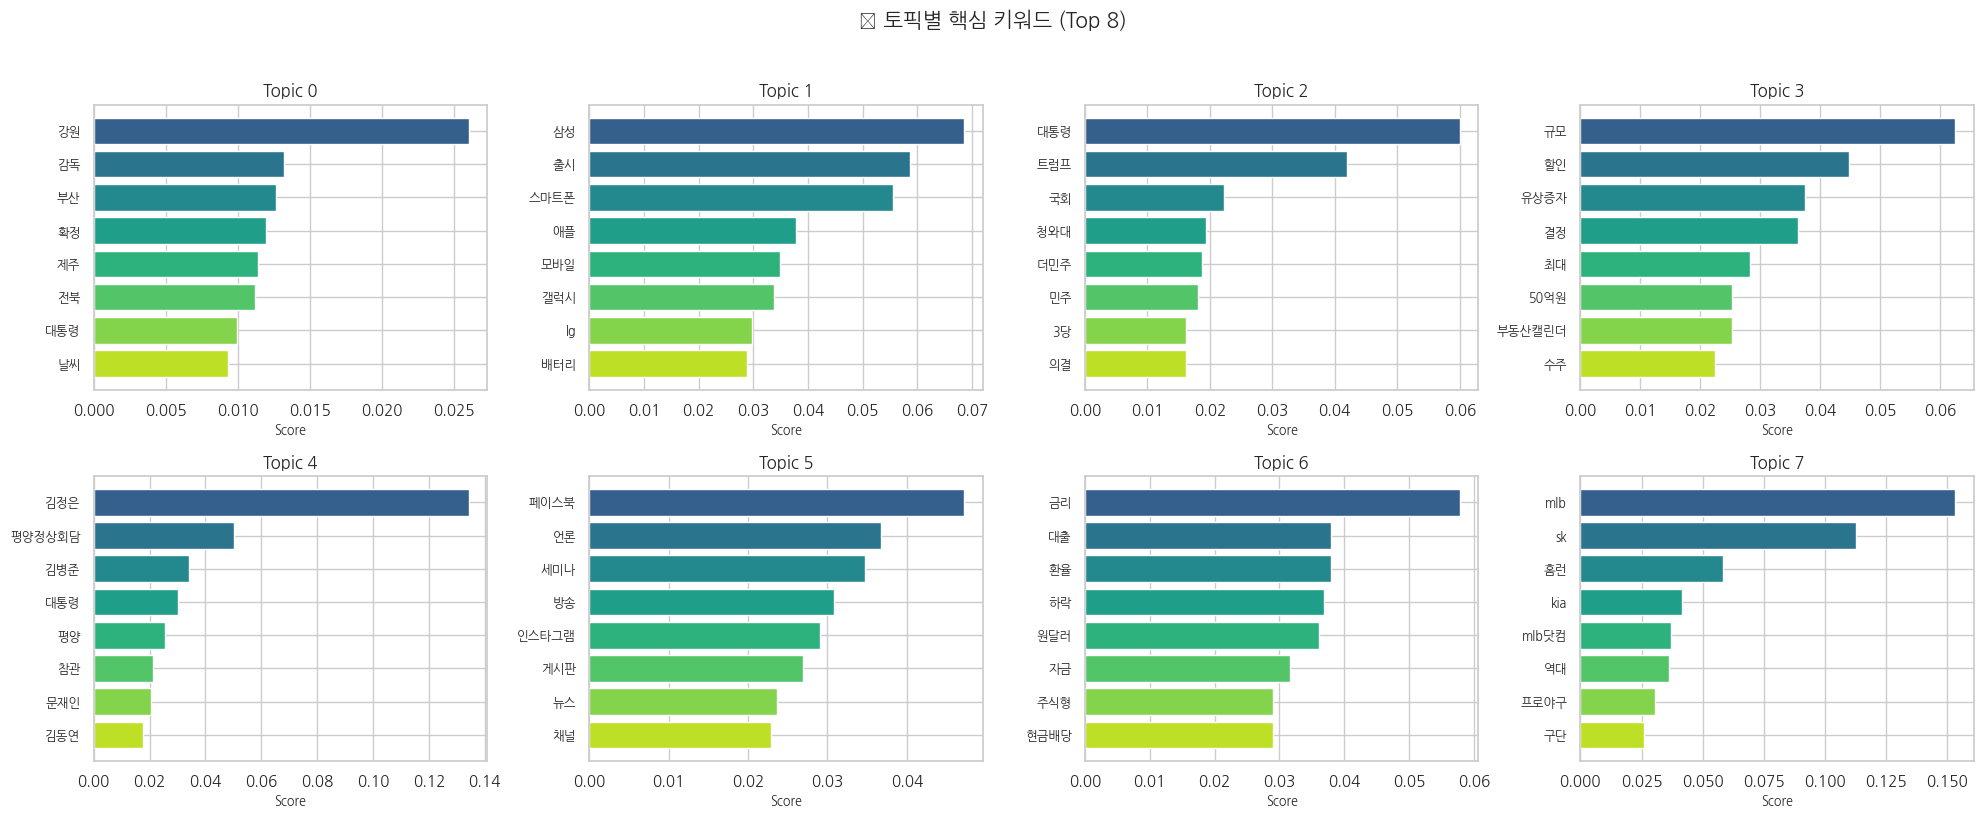

In [ ]:
# === 토픽 시각화 1: 토픽별 키워드 중요도 ===
print("=== 토픽별 핵심 키워드 시각화 ===")

# 상위 토픽의 키워드 중요도 바차트
n_topics_to_show = min(8, len(set(topics)) - (1 if -1 in topics else 0))
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()

for idx in range(n_topics_to_show):
    topic_words = topic_model.get_topic(idx)
    if topic_words:
        words = [w for w, _ in topic_words[:8]]
        scores = [s for _, s in topic_words[:8]]

        colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(words)))
        axes[idx].barh(range(len(words)), scores, color=colors)
        axes[idx].set_yticks(range(len(words)))
        axes[idx].set_yticklabels(words, fontsize=9)
        axes[idx].invert_yaxis()
        axes[idx].set_title(f"Topic {idx}", fontsize=12, fontweight='bold')
        axes[idx].set_xlabel("Score", fontsize=9)

# 남는 서브플롯 숨기기
for idx in range(n_topics_to_show, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("📊 토픽별 핵심 키워드 (Top 8)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


=== 문서들의 2D 토픽 분포 ===


Batches:   0%|          | 0/157 [00:00<?, ?it/s]

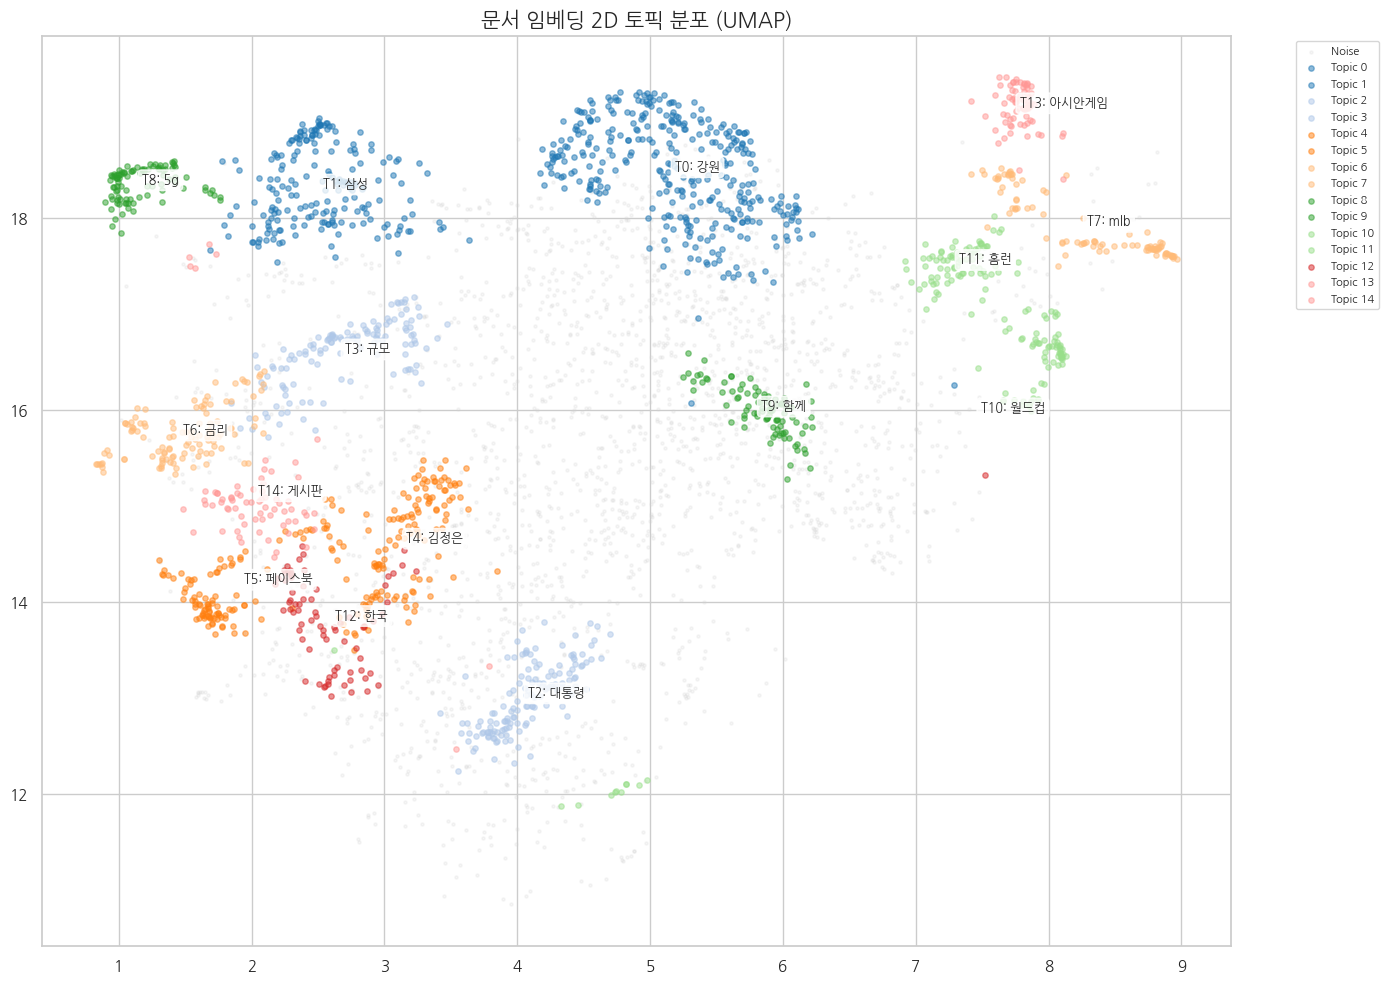

In [ ]:
# === 토픽 시각화 2: 2D 토픽 맵 ===
print("=== 문서들의 2D 토픽 분포 ===")

# 임베딩 → 2D 축소
embeddings = embedding_model.encode(topic_texts, show_progress_bar=True)
umap_2d = UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
               metric='cosine', random_state=42)
embeddings_2d = umap_2d.fit_transform(embeddings)

# 시각화
fig, ax = plt.subplots(figsize=(14, 10))

# 노이즈(-1) 제외하고 유효 토픽만
valid_mask = np.array(topics) != -1
topic_arr = np.array(topics)

# 노이즈 점 (회색)
ax.scatter(embeddings_2d[~valid_mask, 0], embeddings_2d[~valid_mask, 1],
           c='lightgray', alpha=0.2, s=5, label='Noise')

# 토픽별 점
unique_topics = sorted(set(topic_arr[valid_mask]))
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_topics)))

for i, t in enumerate(unique_topics[:15]):  # 상위 15개 토픽
    mask = topic_arr == t
    ax.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1],
               c=[colors[i]], alpha=0.5, s=15, label=f'Topic {t}')

    # 토픽 중심에 레이블
    cx, cy = embeddings_2d[mask, 0].mean(), embeddings_2d[mask, 1].mean()
    topic_words = topic_model.get_topic(t)
    if topic_words:
        top_word = topic_words[0][0]
        ax.annotate(f'T{t}: {top_word}', (cx, cy), fontsize=9, fontweight='bold',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

ax.set_title("문서 임베딩 2D 토픽 분포 (UMAP)", fontsize=15, fontweight='bold')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8, ncol=1)
plt.tight_layout()
plt.show()


### 🔧 심화: 토픽 병합 (Topic Merging)

BERTopic은 데이터에 따라 토픽을 너무 세세하게 나눌 수 있습니다.  
하지만 실제로는 **비슷한 토픽들을 병합**해서 더 큰 그림을 봐야 할 때가 있습니다.

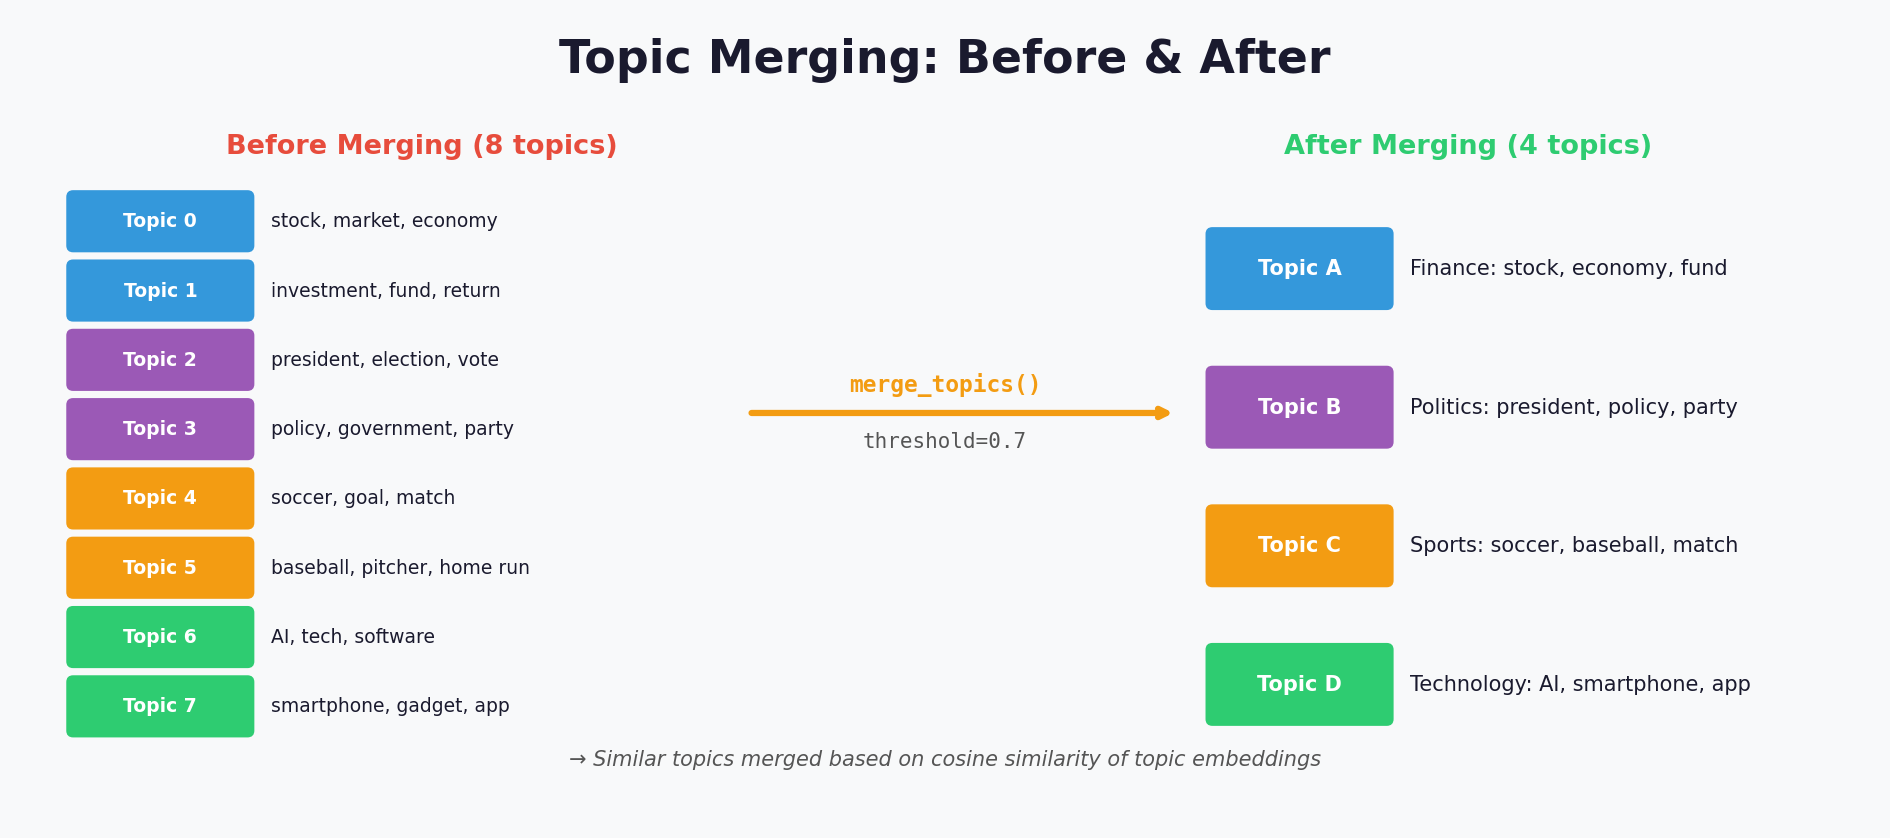

*▲ Topic Merging: 유사한 토픽들을 임베딩 유사도 기반으로 병합*

위 예시에서 12개의 세부 토픽이 4개의 큰 토픽으로 병합됩니다:
- `주식` + `경제성장` + `펀드` → **Finance** (금융)
- `대통령` + `법안` → **Politics** (정치)
- `야구` + `축구` + `농구` → **Sports** (스포츠)
- `AI` + `스마트폰` → **Technology** (기술)


#### 병합 프로세스

1. **유사도 계산**: 각 토픽의 대표 임베딩 벡터 간 **코사인 유사도** 측정  
   - 코사인 유사도 = 두 벡터의 방향이 얼마나 같은가 (1 = 완전히 같음, 0 = 관련 없음)  
   - 의미적으로 비슷한 토픽은 높은 유사도 값을 가짐

2. **임계값 설정**: `threshold=0.7` → 70% 이상 유사한 토픽 쌍을 탐지  
   - 임계값이 낮을수록: 더 많이 병합 (거친 분류)
   - 임계값이 높을수록: 덜 병합 (세밀한 분류)

3. **자동 병합**: `topic_model.merge_topics(docs, threshold)` 호출  
   - BERTopic이 병합 후 키워드를 자동으로 재계산

4. **결과 비교**: 병합 전/후 토픽 수, 키워드, 문서 배정 변화 확인

#### 언제 병합해야 하고, 언제 분리해야 할까?

| 상황 | 결정 | 이유 |
|------|------|------|
| `"주식, 코스피"` 토픽 + `"환율, 달러"` 토픽 | **병합** ✅ | 둘 다 "금융" 주제 |
| `"야구"` 토픽 + `"축구"` 토픽 | **선택적** | 스포츠로 합칠 수도, 개별 유지도 가능 |
| `"삼성"` 토픽 + `"LG"` 토픽 | **분리 유지** ❌ | 같은 산업이지만 다른 기업 이슈 |
| `"코로나19"` 토픽 + `"독감"` 토픽 | **선택적** | 분석 목적에 따라 다름 |

> 💡 **코사인 유사도**는 벡터의 **방향**만 보고 크기는 무시합니다.  
> "주식에 관한 짧은 기사"와 "주식에 관한 긴 기사"는 같은 방향이라 유사도가 높습니다.  
> 이 덕분에 문서 길이에 무관하게 **의미적 유사성**을 측정할 수 있습니다.

=== 토픽 간 유사도 분석 (개선판: 임베딩 기반) ===

유효 토픽 수(크기 >= 10): 35개
유사도 임계값: 0.70

🔍 병합 후보 pair (상위 10개):
  T0 (강원, 감독, 부산) ↔ T2 (아시안게임, 감독, 류현진): 0.962
  T2 (아시안게임, 감독, 류현진) ↔ T22 (여야, 없어, 진통): 0.949
  T0 (강원, 감독, 부산) ↔ T21 (독일, 테러, 풀려나): 0.941
  T2 (아시안게임, 감독, 류현진) ↔ T21 (독일, 테러, 풀려나): 0.930
  T21 (독일, 테러, 풀려나) ↔ T22 (여야, 없어, 진통): 0.930
  T4 (mlb, sk, 미세먼지) ↔ T11 (홈런, 연속, 다저스): 0.928
  T6 (규모, 할인, 유상증자) ↔ T28 (대신증권, 목표가, 주식): 0.921
  T18 (대통령, 인사하는, 개헌) ↔ T22 (여야, 없어, 진통): 0.917
  T2 (아시안게임, 감독, 류현진) ↔ T4 (mlb, sk, 미세먼지): 0.900
  T11 (홈런, 연속, 다저스) ↔ T26 (코스피, 상승, 장중): 0.893

🔗 최종 병합 그룹:
  [np.int64(0), np.int64(2), np.int64(4), np.int64(6), np.int64(10), np.int64(11), np.int64(18), np.int64(21), np.int64(22), np.int64(26), np.int64(28), np.int64(34)] -> T0(강원, 감독, 부산) / T2(아시안게임, 감독, 류현진) / T4(mlb, sk, 미세먼지) / T6(규모, 할인, 유상증자) / T10(월드컵, 올림픽, 우승) / T11(홈런, 연속, 다저스) / T18(대통령, 인사하는, 개헌) / T21(독일, 테러, 풀려나) / T22(여야, 없어, 진통) / T26(코스피, 상승, 장중) / T28(대신증권, 목표가, 주식) / T34(주말, 여행, 축제)
  [np.int64(15

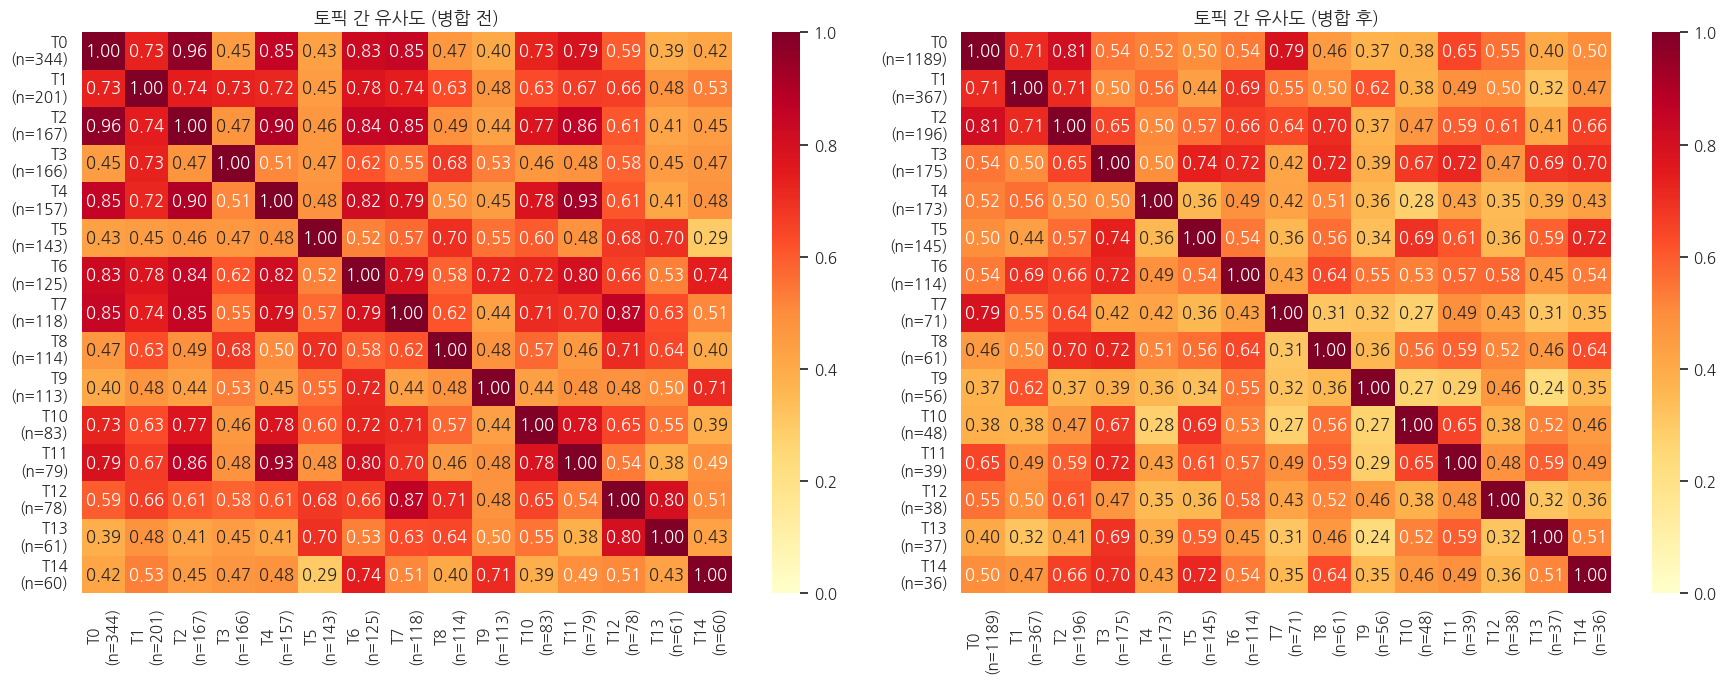

In [ ]:
# === 임베딩 기반 토픽 유사도 분석 + 개선된 토픽 병합 ===

from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import AgglomerativeClustering

# -----------------------------
# 설정값
# -----------------------------
SIM_THRESHOLD = 0.70      # 임계값
MIN_TOPIC_SIZE = 10       # 너무 작은 토픽은 centroid가 불안정해서 제외
CENTRAL_RATIO = 0.80      # 토픽 내 중심 문서 상위 80%만으로 centroid 계산
TOP_N_FOR_PLOT = 15       # 히트맵에 표시할 토픽 수(큰 토픽 우선)

# -----------------------------
# 유틸 함수
# -----------------------------
def top_words(topic_model, topic_id, topn=3):
    words = topic_model.get_topic(topic_id)
    if not words:
        return "?"
    return ", ".join([w for w, _ in words[:topn]])

def compute_robust_centroids(topic_assignments, embeddings, min_topic_size=10, central_ratio=0.8):
    """
    토픽별 centroid를 단순 평균이 아니라
    '중심 문서들만 평균'내는 방식으로 계산
    """
    topic_assignments = np.asarray(topic_assignments)
    emb = normalize(np.asarray(embeddings), norm="l2")

    valid_topics = []
    centroids = []
    topic_sizes = {}

    for t in sorted(set(topic_assignments)):
        if t == -1:
            continue

        idx = np.where(topic_assignments == t)[0]
        if len(idx) < min_topic_size:
            continue

        vecs = emb[idx]

        # 1차 centroid
        c0 = normalize(vecs.mean(axis=0, keepdims=True), norm="l2")[0]

        # centroid와 가까운 중심 문서만 남김
        sims = vecs @ c0
        keep_n = max(5, int(np.ceil(len(vecs) * central_ratio)))
        central_vecs = vecs[np.argsort(sims)[-keep_n:]]

        # 최종 robust centroid
        c = normalize(central_vecs.mean(axis=0, keepdims=True), norm="l2")[0]

        valid_topics.append(t)
        centroids.append(c)
        topic_sizes[t] = len(idx)

    if len(centroids) == 0:
        return [], np.empty((0, np.asarray(embeddings).shape[1])), {}

    return valid_topics, np.vstack(centroids), topic_sizes

def get_candidate_pairs(topic_ids, sim_matrix, threshold=0.80):
    """
    threshold 이상인 pair만 추출해서 유사도 높은 순으로 반환
    """
    pairs = []
    for i in range(len(topic_ids)):
        for j in range(i + 1, len(topic_ids)):
            if sim_matrix[i, j] >= threshold:
                pairs.append((topic_ids[i], topic_ids[j], float(sim_matrix[i, j])))

    pairs.sort(key=lambda x: -x[2])
    return pairs

def build_merge_groups(topic_ids, centroid_matrix, sim_threshold=0.80):
    """
    pair를 그냥 상위 몇 개 고르는 대신,
    complete-linkage clustering으로 '보수적 그룹 병합'
    """
    if len(topic_ids) < 2:
        return []

    distance_threshold = 1 - sim_threshold

    try:
        clusterer = AgglomerativeClustering(
            n_clusters=None,
            metric="cosine",
            linkage="complete",
            distance_threshold=distance_threshold
        )
    except TypeError:
        # 구버전 sklearn 호환
        clusterer = AgglomerativeClustering(
            n_clusters=None,
            affinity="cosine",
            linkage="complete",
            distance_threshold=distance_threshold
        )

    cluster_labels = clusterer.fit_predict(centroid_matrix)

    groups = {}
    for topic_id, label in zip(topic_ids, cluster_labels):
        groups.setdefault(label, []).append(topic_id)

    merge_groups = [sorted(v) for v in groups.values() if len(v) > 1]
    merge_groups.sort(key=lambda g: (-len(g), g))
    return merge_groups

def plot_similarity_heatmap(ax, topic_ids, sim_matrix, topic_sizes, title, top_n=15):
    """
    병합은 전체 토픽으로 하되, 시각화는 큰 토픽 위주로 top_n만 표시
    """
    if len(topic_ids) == 0:
        ax.text(0.5, 0.5, "표시할 토픽 없음", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title, fontsize=13, fontweight="bold")
        return

    plot_topics = sorted(topic_ids, key=lambda t: topic_sizes.get(t, 0), reverse=True)[:top_n]
    idx_map = {t: i for i, t in enumerate(topic_ids)}
    plot_idx = [idx_map[t] for t in plot_topics]

    plot_matrix = sim_matrix[np.ix_(plot_idx, plot_idx)]
    plot_labels = [f"T{t}\n(n={topic_sizes.get(t,0)})" for t in plot_topics]

    sns.heatmap(
        plot_matrix,
        annot=True,
        fmt=".2f",
        cmap="YlOrRd",
        ax=ax,
        xticklabels=plot_labels,
        yticklabels=plot_labels,
        vmin=0,
        vmax=1
    )
    ax.set_title(title, fontsize=13, fontweight="bold")

# -----------------------------
# 메인 로직
# -----------------------------
print("=== 토픽 간 유사도 분석 (개선판: 임베딩 기반) ===\n")

# 현재 토픽 할당
topic_arr_before = np.array(topic_model.topics_)

# 병합 전 centroid 계산
topic_ids_before, centroid_before, topic_sizes_before = compute_robust_centroids(
    topic_arr_before,
    embeddings,
    min_topic_size=MIN_TOPIC_SIZE,
    central_ratio=CENTRAL_RATIO
)

if len(topic_ids_before) < 2:
    print("병합할 수 있을 만큼 충분한 토픽이 없습니다.")
else:
    sim_before = cosine_similarity(centroid_before)

    # 후보 pair
    candidate_pairs = get_candidate_pairs(
        topic_ids_before,
        sim_before,
        threshold=SIM_THRESHOLD
    )

    # 최종 병합 그룹
    merge_groups = build_merge_groups(
        topic_ids_before,
        centroid_before,
        sim_threshold=SIM_THRESHOLD
    )

    print(f"유효 토픽 수(크기 >= {MIN_TOPIC_SIZE}): {len(topic_ids_before)}개")
    print(f"유사도 임계값: {SIM_THRESHOLD:.2f}\n")

    print("🔍 병합 후보 pair (상위 10개):")
    if candidate_pairs:
        for t1, t2, sim in candidate_pairs[:10]:
            print(
                f"  T{t1} ({top_words(topic_model, t1)}) "
                f"↔ T{t2} ({top_words(topic_model, t2)}): {sim:.3f}"
            )
    else:
        print("  없음")

    print("\n🔗 최종 병합 그룹:")
    if merge_groups:
        for g in merge_groups:
            desc = " / ".join([f"T{t}({top_words(topic_model, t)})" for t in g])
            print(f"  {g} -> {desc}")
    else:
        print("  없음")

    # 시각화
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    plot_similarity_heatmap(
        axes[0],
        topic_ids_before,
        sim_before,
        topic_sizes_before,
        title="토픽 간 유사도 (병합 전)",
        top_n=TOP_N_FOR_PLOT
    )

    # 실제 병합
    if merge_groups:
        # 주의: topic_texts는 fit / fit_transform 때 사용한 원본 문서 리스트여야 함
        topic_model.merge_topics(topic_texts, merge_groups)

        topic_arr_after = np.array(topic_model.topics_)

        topic_ids_after, centroid_after, topic_sizes_after = compute_robust_centroids(
            topic_arr_after,
            embeddings,
            min_topic_size=MIN_TOPIC_SIZE,
            central_ratio=CENTRAL_RATIO
        )

        sim_after = cosine_similarity(centroid_after) if len(topic_ids_after) > 0 else np.empty((0, 0))

        n_before = len(set([t for t in topic_arr_before if t != -1]))
        n_after = len(set([t for t in topic_arr_after if t != -1]))

        print(f"\n✅ 토픽 병합 완료")
        print(f"   병합 전: {n_before}개 → 병합 후: {n_after}개")

        plot_similarity_heatmap(
            axes[1],
            topic_ids_after,
            sim_after,
            topic_sizes_after,
            title="토픽 간 유사도 (병합 후)",
            top_n=TOP_N_FOR_PLOT
        )
    else:
        axes[1].text(0.5, 0.5, "병합 후보 없음", ha="center", va="center", transform=axes[1].transAxes)
        axes[1].set_title("토픽 간 유사도 (병합 후)", fontsize=13, fontweight="bold")

    plt.tight_layout()
    plt.show()

=== 토픽 모델링 결과 vs 실제 카테고리 비교 ===
(토픽모델링은 레이블 없이 추출했지만, 실제 레이블과 얼마나 일치하는지 확인)

📊 각 토픽의 실제 카테고리 구성:
-----------------------------------------------------------------
  Topic  0 (mlb       ) → 주 카테고리: 스포츠      (37%)
           분포: 스포츠: 440 | 생활/문화: 203 | 경제: 162

  Topic  1 (5g        ) → 주 카테고리: IT/과학    (57%)
           분포: IT/과학: 211 | 경제: 70 | 사회: 42

  Topic  2 (김정은       ) → 주 카테고리: 정치       (52%)
           분포: 정치: 102 | 사회: 33 | 생활/문화: 20

  Topic  3 (대통령       ) → 주 카테고리: 정치       (60%)
           분포: 정치: 105 | 세계: 51 | 사회: 12

  Topic  4 (작년        ) → 주 카테고리: 경제       (84%)
           분포: 경제: 146 | 세계: 14 | 사회: 8

  Topic  5 (이란        ) → 주 카테고리: 세계       (90%)
           분포: 세계: 131 | 정치: 7 | IT/과학: 2

  Topic  6 (페이스북      ) → 주 카테고리: 사회       (40%)
           분포: 사회: 46 | IT/과학: 26 | 세계: 14

  Topic  7 (nba       ) → 주 카테고리: 스포츠      (92%)
           분포: 스포츠: 65 | 세계: 3 | 정치: 3

  Topic  8 (중국        ) → 주 카테고리: 세계       (70%)
           분포: 세계: 43 | 스포츠: 6 | 생활/문화: 5

  Top

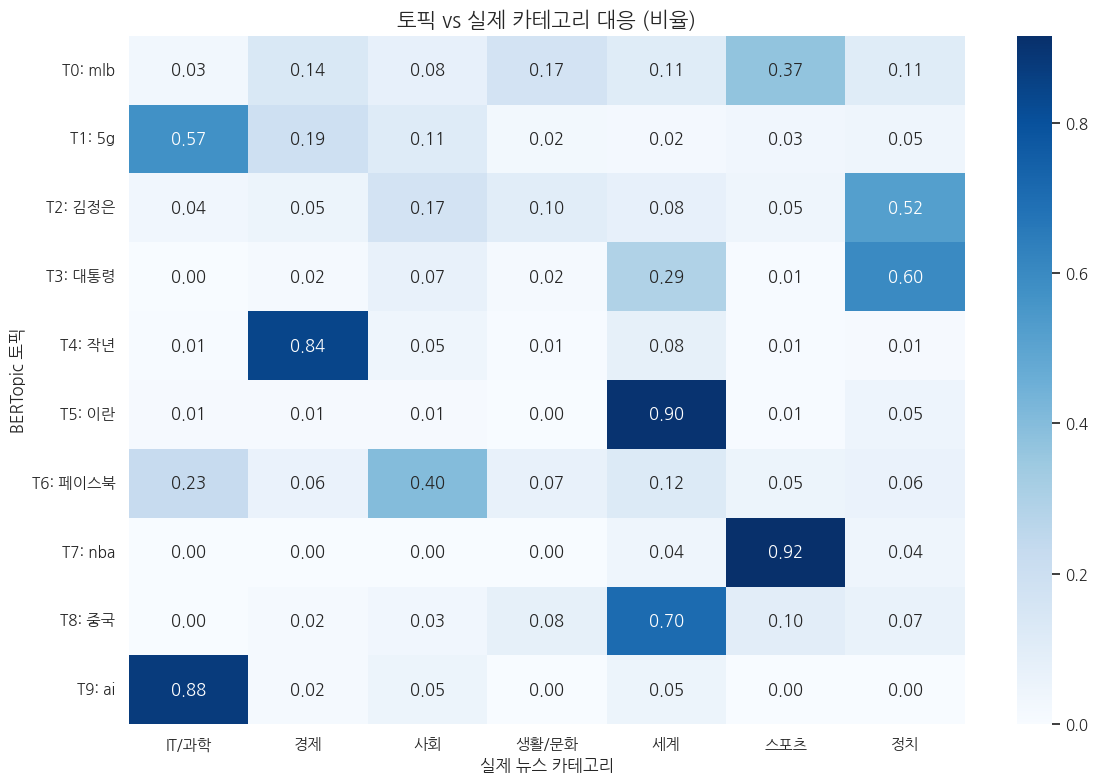


💡 인사이트:
  - 토픽이 실제 카테고리와 대체로 잘 대응된다면 → 토픽모델링이 효과적!
  - 여러 카테고리가 섞인 토픽 → 해당 주제가 여러 분야에 걸쳐 있다는 의미


In [ ]:
# === 토픽 vs 실제 카테고리 비교 ===
print("=== 토픽 모델링 결과 vs 실제 카테고리 비교 ===")
print("(토픽모델링은 레이블 없이 추출했지만, 실제 레이블과 얼마나 일치하는지 확인)")
print()

final_topics = topic_model.topics_

# 토픽-카테고리 대응표
from collections import defaultdict

topic_category_map = defaultdict(lambda: defaultdict(int))
for t, true_label in zip(final_topics, topic_true_labels):
    if t != -1:
        topic_category_map[t][label_names[true_label]] += 1

print("📊 각 토픽의 실제 카테고리 구성:")
print("-" * 65)

for t in sorted(topic_category_map.keys())[:10]:
    total = sum(topic_category_map[t].values())
    sorted_cats = sorted(topic_category_map[t].items(), key=lambda x: -x[1])

    topic_words = topic_model.get_topic(t)
    top_word = topic_words[0][0] if topic_words else '?'

    main_cat = sorted_cats[0][0]
    main_pct = sorted_cats[0][1] / total * 100

    detail = " | ".join([f"{cat}: {cnt}" for cat, cnt in sorted_cats[:3]])
    print(f"  Topic {t:2d} ({top_word:10s}) → 주 카테고리: {main_cat:8s} ({main_pct:.0f}%)")
    print(f"           분포: {detail}")
    print()

# 시각화: 토픽-카테고리 히트맵
fig, ax = plt.subplots(figsize=(12, 8))

topic_ids_valid = sorted([t for t in set(final_topics) if t != -1])[:10]
categories = list(label_names.values())

heatmap_data = np.zeros((len(topic_ids_valid), len(categories)))
for i, t in enumerate(topic_ids_valid):
    total = sum(topic_category_map[t].values())
    for j, cat in enumerate(categories):
        heatmap_data[i, j] = topic_category_map[t].get(cat, 0) / total

topic_row_labels = []
for t in topic_ids_valid:
    w = topic_model.get_topic(t)
    top = w[0][0] if w else '?'
    topic_row_labels.append(f"T{t}: {top}")

sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='Blues', ax=ax,
            xticklabels=categories, yticklabels=topic_row_labels)
ax.set_title("토픽 vs 실제 카테고리 대응 (비율)", fontsize=15, fontweight='bold')
ax.set_xlabel("실제 뉴스 카테고리", fontsize=12)
ax.set_ylabel("BERTopic 토픽", fontsize=12)
plt.tight_layout()
plt.show()

print("\n💡 인사이트:")
print("  - 토픽이 실제 카테고리와 대체로 잘 대응된다면 → 토픽모델링이 효과적!")
print("  - 여러 카테고리가 섞인 토픽 → 해당 주제가 여러 분야에 걸쳐 있다는 의미")


### 📈 심화: 워드클라우드 + 토픽 분포 시각화

토픽의 특성을 더 직관적으로 파악하기 위해 두 가지 시각화를 제공합니다.

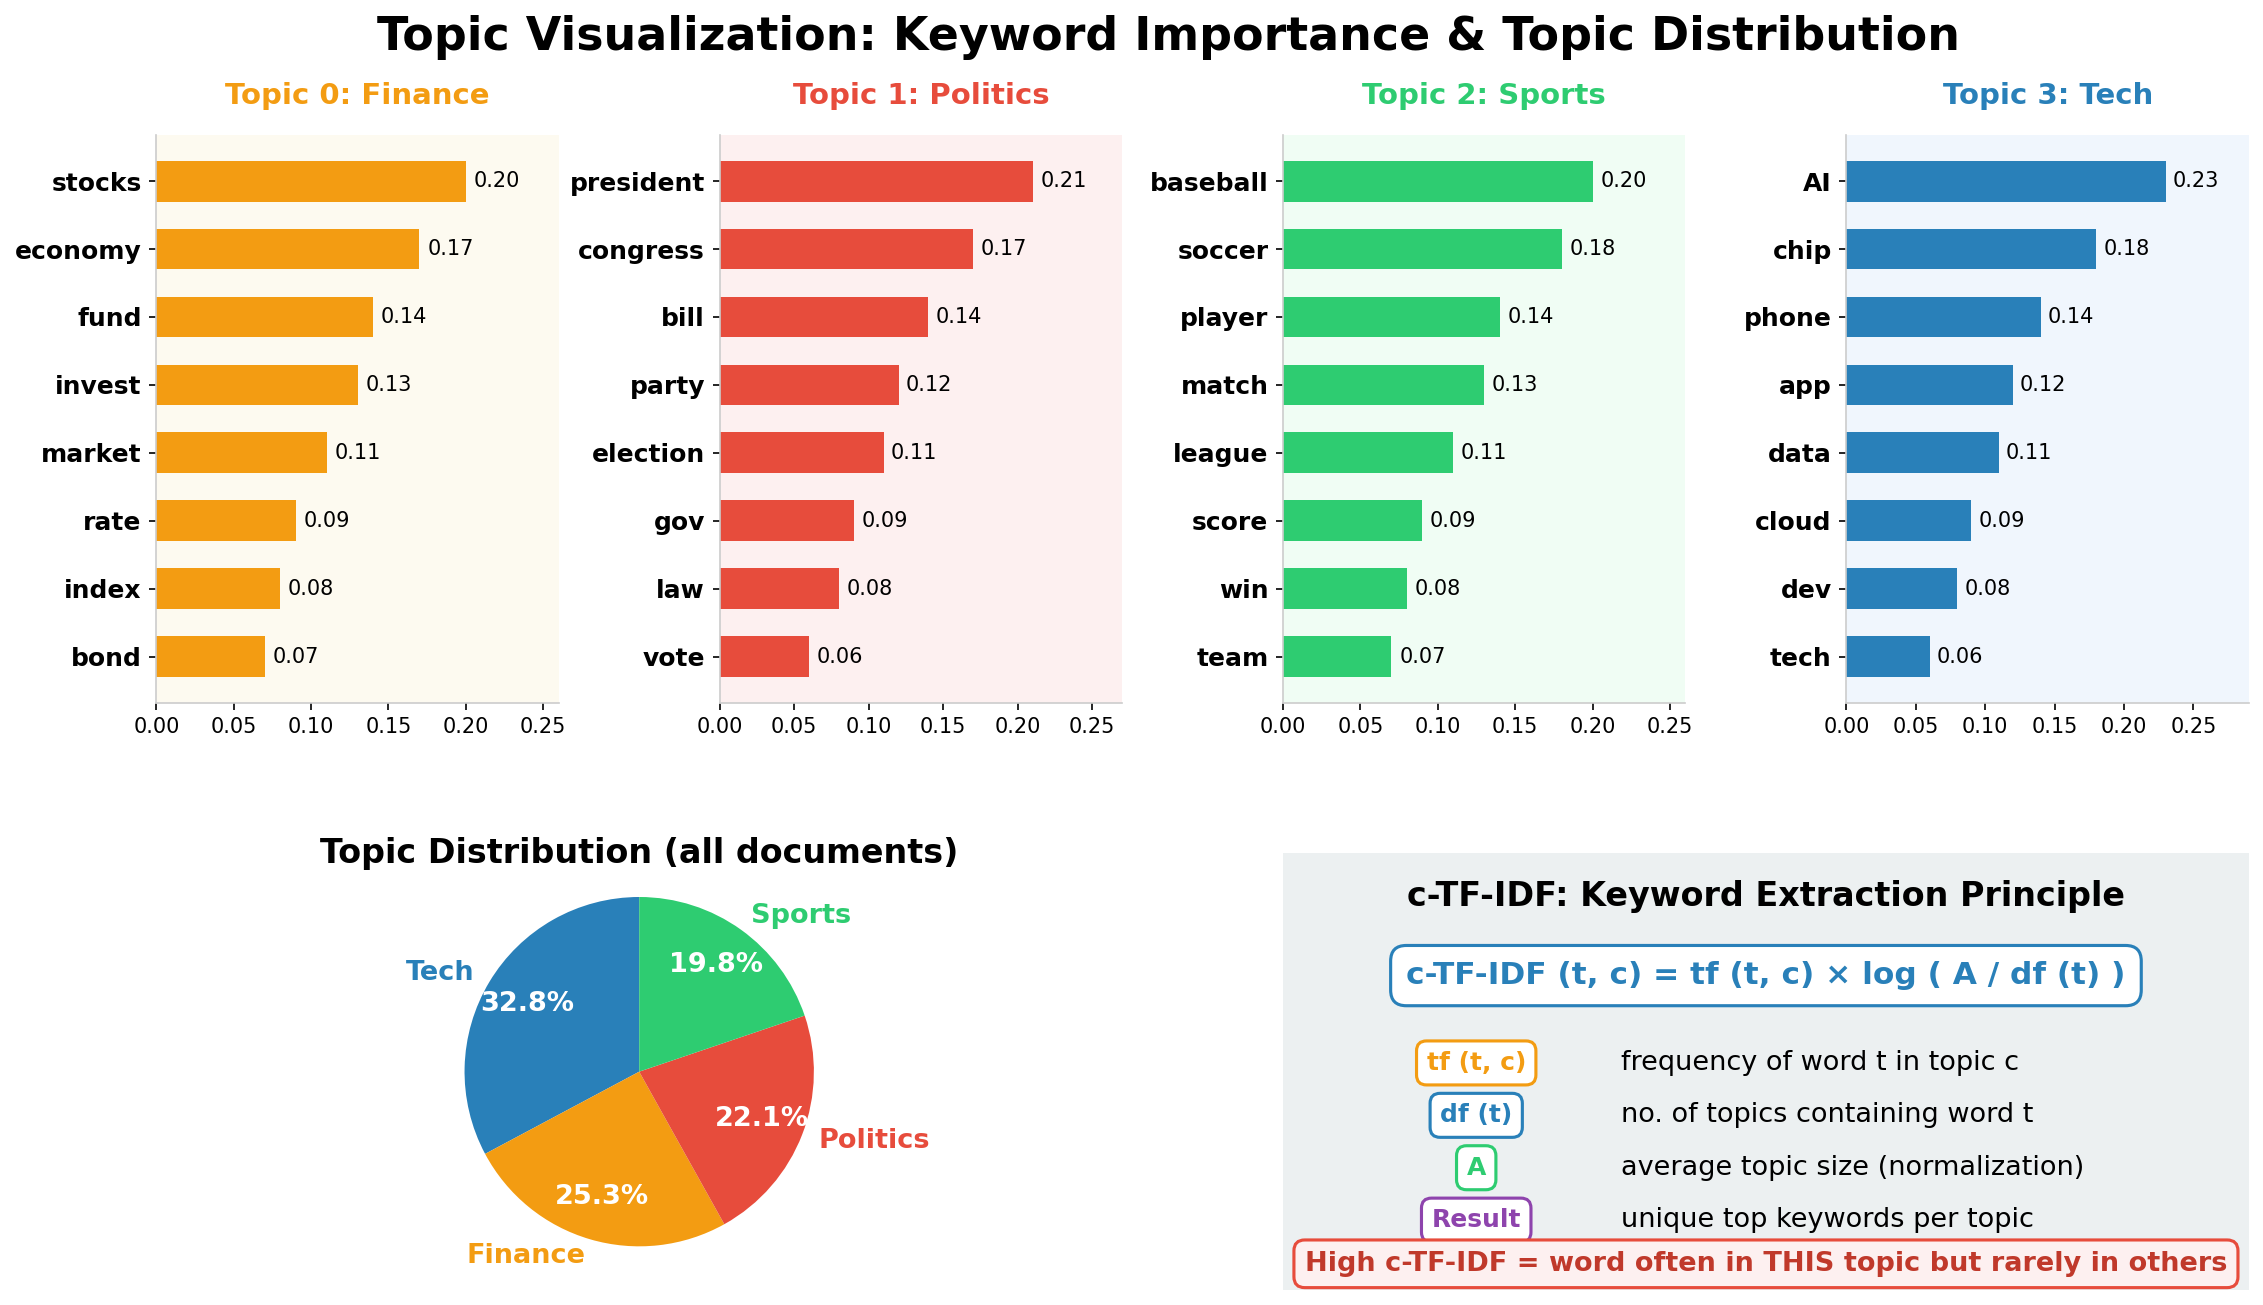

#### 두 시각화 비교

| 시각화 | 무엇을 보여주나? | 어떻게 읽나? | 활용 포인트 |
|--------|----------------|------------|------------|
| **워드클라우드** | 각 토픽의 핵심 키워드 | 단어가 클수록 해당 토픽에서 중요한 키워드 | 토픽이 어떤 주제인지 직관적 파악 |
| **파이차트** | 전체 문서 중 각 토픽의 비중 | 가장 큰 조각 = 가장 많이 다뤄진 주제 | 데이터의 주제별 분포 파악 |

#### c-TF-IDF: 토픽 키워드 추출 원리

BERTopic은 일반 TF-IDF 대신 **c-TF-IDF (Class-based TF-IDF)** 를 사용합니다:

```
일반 TF-IDF:  "이 단어가 이 문서에서 얼마나 중요한가?"
c-TF-IDF:     "이 단어가 이 토픽에서 다른 토픽보다 얼마나 더 많이 등장하는가?"
```

- **TF** (Term Frequency): 해당 토픽 내 단어 출현 빈도
- **IDF** (Inverse Document Frequency): 다른 토픽에서는 덜 나오는 단어에 높은 가중치

> 💡 **워드클라우드의 한계**: 시각적으로 직관적이지만, 실제 c-TF-IDF 점수와  
> 단어 크기가 정확히 비례하지 않을 수 있습니다 (시각화 도구의 특성).  
> **정확한 키워드 중요도**는 `topic_model.get_topic(topic_id)` 결과를 직접 확인하세요.

> 📊 **파이차트 해석 시 주의사항**: 토픽 크기가 작다고 중요하지 않은 것은 아닙니다.  
> 드물게 등장하는 이슈(예: 특정 사건)도 매우 중요할 수 있습니다.  
> 빈도(크기)와 중요성은 별개로 판단해야 합니다.

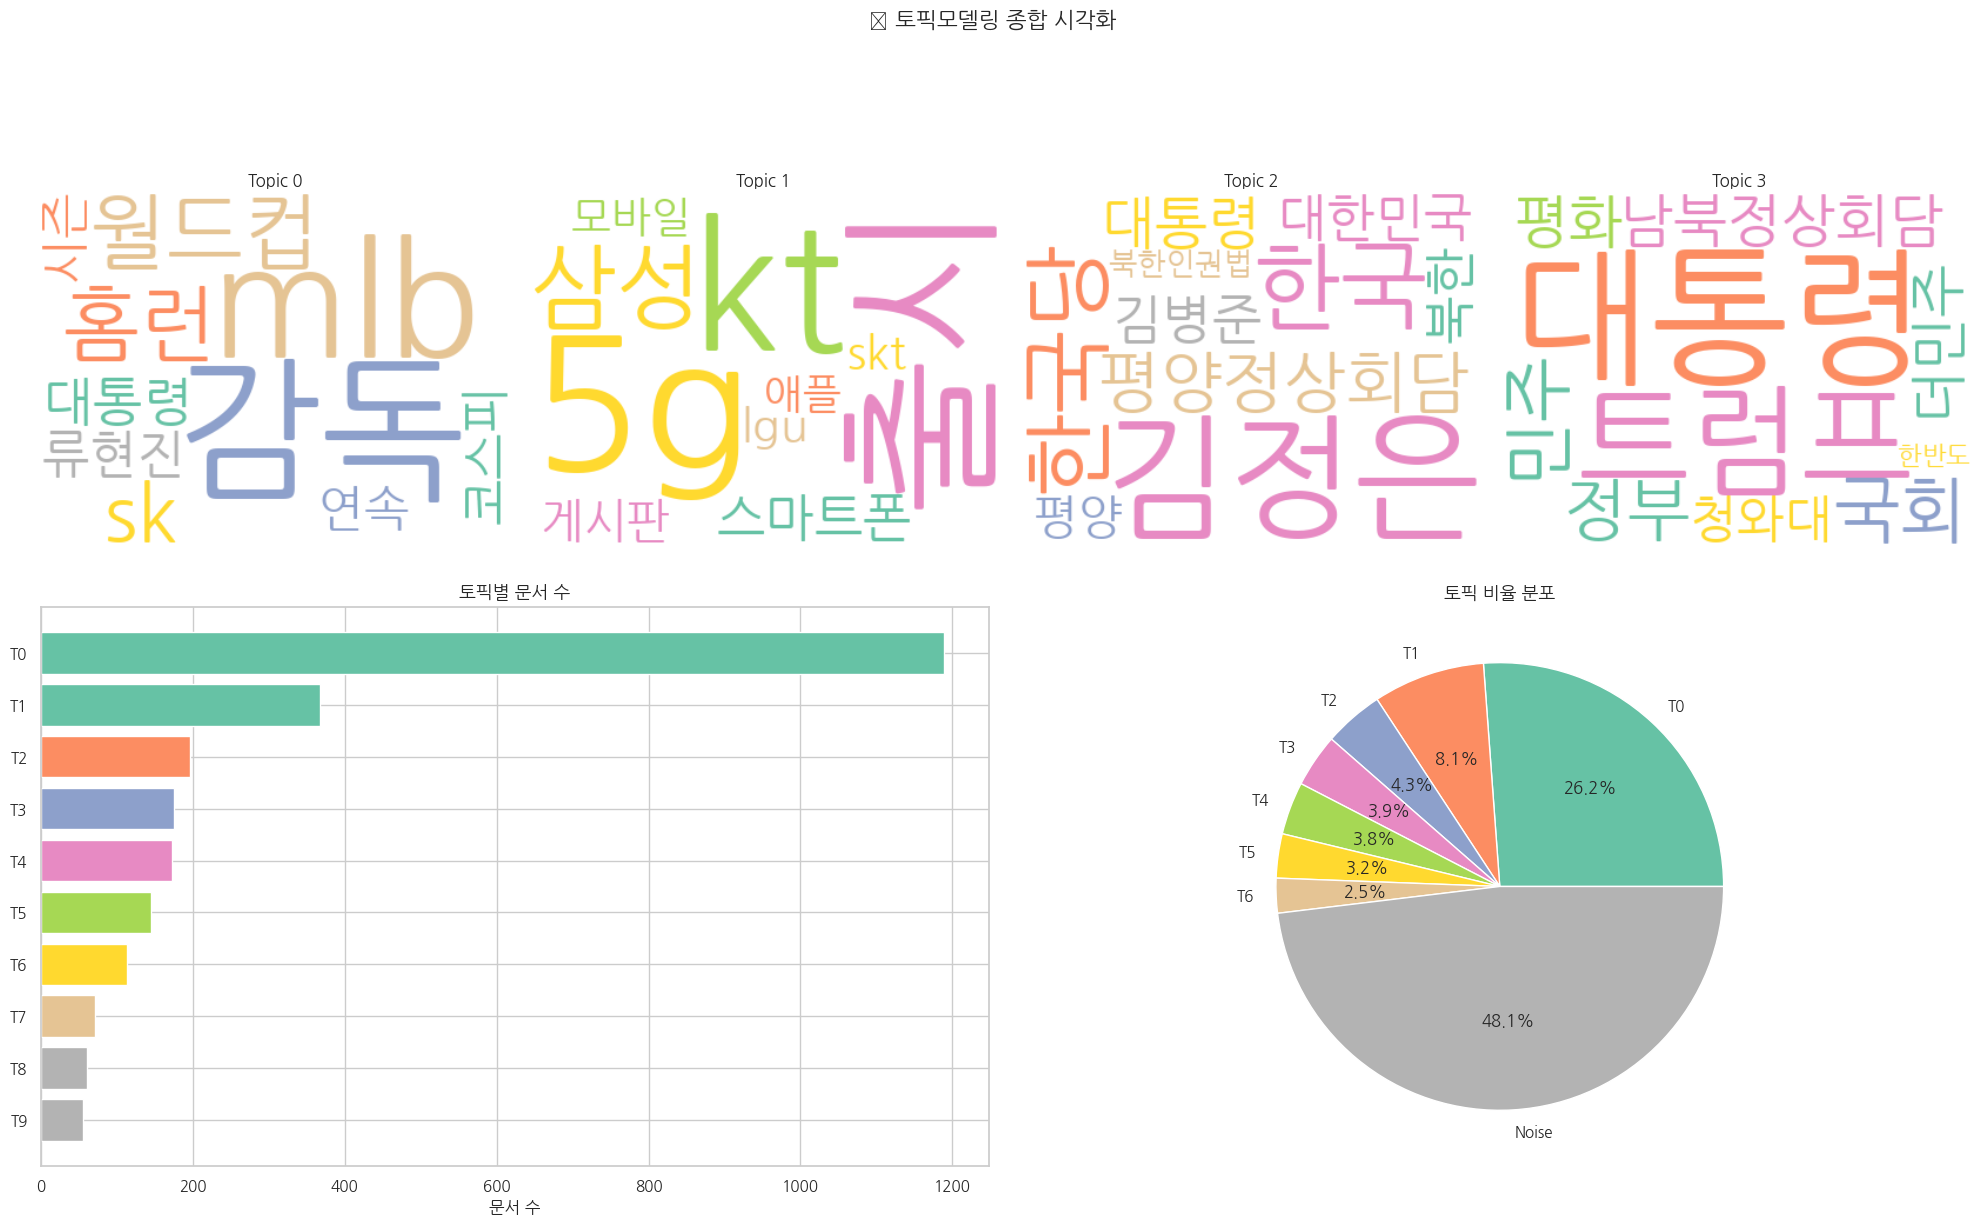

In [ ]:
# === 워드클라우드 + 토픽 분포 ===
from wordcloud import WordCloud

fig = plt.figure(figsize=(20, 12))

# 상단: 주요 토픽 워드클라우드 (4개)
n_wc = min(4, len(topic_ids_valid))
for idx in range(n_wc):
    ax = fig.add_subplot(2, n_wc, idx + 1)
    t = topic_ids_valid[idx]
    topic_words = topic_model.get_topic(t)

    if topic_words:
        word_freq = {w: max(s, 0.001) for w, s in topic_words[:20]}

        # 앞서 설정한 KOREAN_FONT_PATH 재사용
        wc = WordCloud(
            width=400, height=300,
            background_color='white',
            colormap='Set2',
            font_path=font_name,  # Cell 2에서 설정한 한글 폰트
            max_words=20,
            prefer_horizontal=0.7
        )

        try:
            wc.generate_from_frequencies(word_freq)
            ax.imshow(wc, interpolation='bilinear')
        except:
            # 한글 폰트 문제시 텍스트로 대체
            words_text = "\n".join([f"{w}: {s:.3f}" for w, s in topic_words[:8]])
            ax.text(0.5, 0.5, words_text, transform=ax.transAxes,
                   ha='center', va='center', fontsize=10)

    ax.set_title(f"Topic {t}", fontsize=12, fontweight='bold')
    ax.axis('off')

# 하단 왼쪽: 토픽 크기 분포
ax_dist = fig.add_subplot(2, 2, 3)
topic_counts = topic_model.get_topic_info()
topic_counts_valid = topic_counts[topic_counts['Topic'] != -1].head(10)

colors = plt.cm.Set2(np.linspace(0, 1, len(topic_counts_valid)))
ax_dist.barh(range(len(topic_counts_valid)), topic_counts_valid['Count'].values, color=colors)
ax_dist.set_yticks(range(len(topic_counts_valid)))
ax_dist.set_yticklabels([f"T{t}" for t in topic_counts_valid['Topic'].values])
ax_dist.invert_yaxis()
ax_dist.set_title("토픽별 문서 수", fontsize=13, fontweight='bold')
ax_dist.set_xlabel("문서 수")

# 하단 오른쪽: 토픽 비율 파이차트
ax_pie = fig.add_subplot(2, 2, 4)
sizes = topic_counts_valid['Count'].values[:7]
pie_labels = [f"T{t}" for t in topic_counts_valid['Topic'].values[:7]]
noise_count = topic_counts[topic_counts['Topic'] == -1]['Count'].values
if len(noise_count) > 0:
    sizes = np.append(sizes, noise_count[0])
    pie_labels.append("Noise")

ax_pie.pie(sizes, labels=pie_labels, autopct='%1.1f%%', colors=plt.cm.Set2(np.linspace(0, 1, len(sizes))))
ax_pie.set_title("토픽 비율 분포", fontsize=13, fontweight='bold')

plt.suptitle("📊 토픽모델링 종합 시각화", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
# 🎓 Part 5. 정리 및 요약

## 오늘 배운 3가지 태스크 비교

| 항목 | 감성분석 | 다중분류 | 토픽모델링 |
|------|----------|----------|------------|
| **유형** | 지도학습 (이진) | 지도학습 (다중) | 비지도학습 |
| **목적** | 감정 판별 | 카테고리 분류 | 주제 발견 |
| **레이블** | 필요 (긍/부정) | 필요 (카테고리) | 불필요 |
| **모델** | KLUE-BERT (2-class) | KLUE-BERT (7-class) | BERTopic |
| **데이터셋** | NSMC (영화 리뷰) | KLUE-YNAT (뉴스) | KLUE-YNAT (레이블 미사용) |
| **핵심 기법** | 파인튜닝 | 파인튜닝 + 층화추출 | 임베딩 + 클러스터링 |
| **평가 지표** | Accuracy, F1 | Macro-F1, Confusion Matrix | Coherence Score |
| **심화 분석** | 오답분석, 신뢰도 보정 | 혼동행렬, 오분류 패턴 | 토픽 병합, 워드클라우드 |

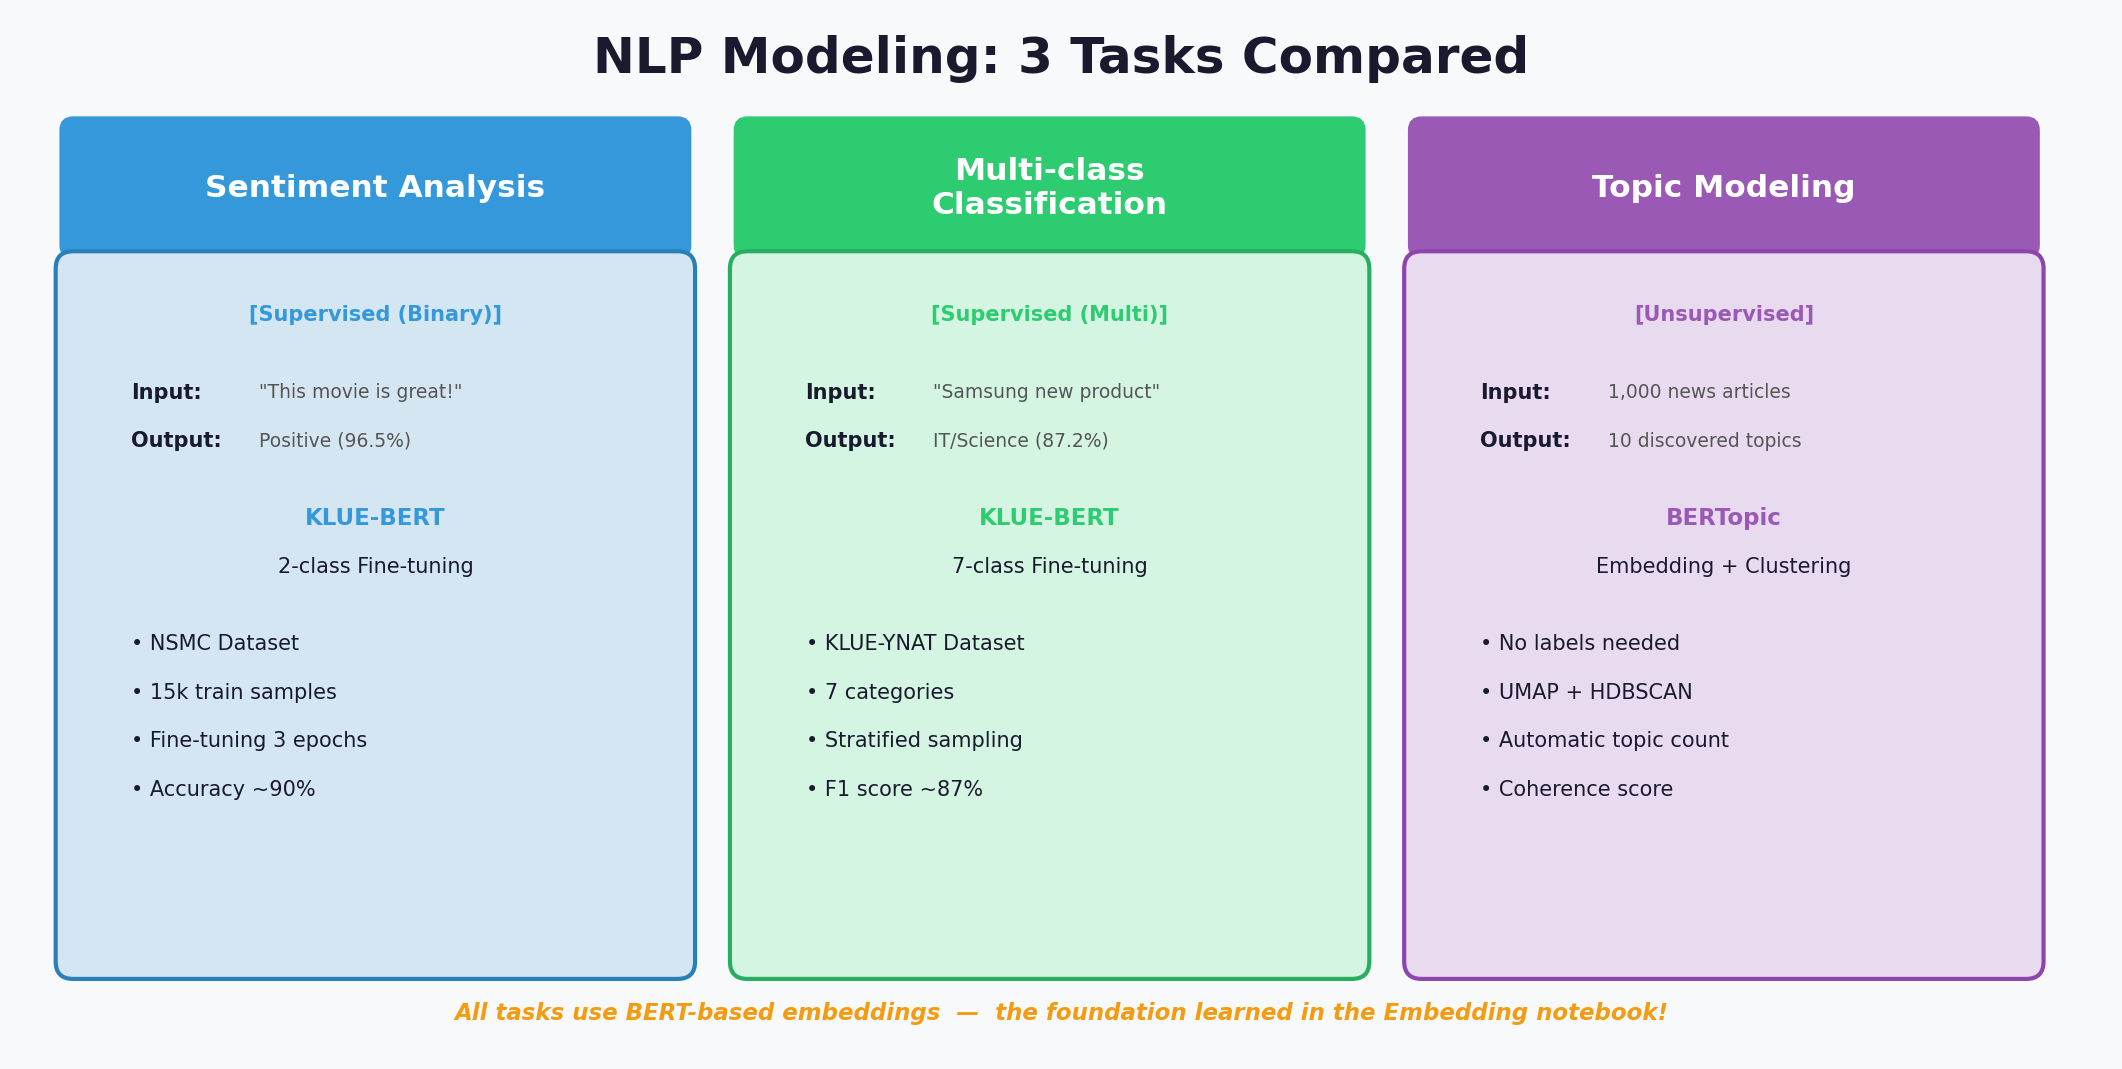

*▲ NLP Modeling 3가지 태스크 비교: 감성분석 vs 다중분류 vs 토픽모델링*

## 🛠️ 팁

### 1. 데이터가 가장 중요합니다
- 모델 성능의 80%는 데이터 품질에 달려 있습니다
- 레이블 불균형 → 층화 추출(Stratified Sampling) 필수
- 전처리(노이즈 제거, 정규화)에 충분한 시간을 투자하세요
- "Garbage in, Garbage out" — 좋은 모델도 나쁜 데이터는 극복하지 못합니다

### 2. 평가 지표를 올바르게 선택하세요
- 균형 데이터 → **Accuracy** 사용 가능
- 불균형 데이터 → Accuracy 대신 **F1-Score (Macro)** 사용
- 다중분류 → **혼동행렬**로 어떤 클래스끼리 혼동하는지 확인
- 토픽모델링 → **일관성 점수(Coherence Score)**로 토픽 품질 평가
- 신뢰도 중요 시 → **Calibration** 분석으로 과신/과소신 여부 확인

### 3. 오답 분석이 성능 향상의 핵심입니다
- "90%+ 확신했는데 틀린" 케이스를 반드시 직접 읽어보세요
- 패턴이 보이면 → 해당 패턴의 데이터를 더 수집하거나 레이블 기준을 명확히
- "왜 틀렸는가?" 를 항상 물어보세요 — 숫자가 아닌 실제 텍스트를 보는 것이 중요합니다

### 4. 실험을 반복하세요 (Iterate)
- 첫 번째 모델이 최선이 아닙니다
- 하이퍼파라미터 조정: `learning_rate`, `batch_size`, `num_epochs`
- 데이터 보강 후 재학습 → 성능 비교
- 여러 모델 앙상블로 성능 향상 가능

## 🚀 다음 단계

| 단계 | 주제 | 설명 | 전제 지식 |
|------|------|------|----------|
| 심화 1 | **대화형 모델** | 챗봇, 질의응답 시스템 | 이 교안 완료 |
| 심화 2 | **생성 모델** | GPT 기반 텍스트 생성, 요약 | 이 교안 완료 |
| 심화 3 | **RAG** | 검색 증강 생성 (Retrieval-Augmented Generation) | 임베딩 + 생성 모델 |
| 심화 4 | **프로덕션** | 모델 배포, FastAPI, 모니터링 | 기본 웹 개발 |

## 📚 참고 자료

- [KLUE 벤치마크](https://klue-benchmark.com/) — 한국어 NLP 표준 벤치마크
- [Hugging Face Transformers 문서](https://huggingface.co/docs/transformers/) — 사전학습 모델 활용법
- [BERTopic 공식 문서](https://maartengr.github.io/BERTopic/) — 토픽모델링 심화
- [NSMC 데이터셋](https://github.com/e9t/nsmc) — 한국어 감성분석 벤치마크

In [ ]:
# 🎯 보너스: 직접 텍스트 분석 체험
print("=" * 60)
print("🎯 보너스: 나만의 텍스트 분석")
print("=" * 60)
print()

# 감성분석 모델과 다중분류 모델로 동시 분석
# (앞에서 CPU로 이동시킨 모델들을 다시 활용합니다)
test_text = "인공지능이 의료 분야에서 획기적인 성과를 거두고 있다"  # ← 바꿔보세요!

print(f"입력 텍스트: {test_text}")
print()

# 감성분석 (CPU에 있는 모델 사용)
model.eval()
device_sent = next(model.parameters()).device  # cpu
inputs_sent = tokenizer(test_text, return_tensors='pt', truncation=True,
                         max_length=128, padding=True).to(device_sent)
with torch.no_grad():
    outputs_sent = model(**inputs_sent)
    prob_sent = torch.softmax(outputs_sent.logits, dim=-1)[0]

sent_result = "긍정 👍" if prob_sent[1] > prob_sent[0] else "부정 👎"
print(f"📊 감성분석: {sent_result} (확신도: {max(prob_sent).item():.3f})")

# 다중분류 (CPU에 있는 모델 사용)
model_mc.eval()
device_mc = next(model_mc.parameters()).device  # cpu
inputs_mc = tokenizer(test_text, return_tensors='pt', truncation=True,
                       max_length=64, padding=True).to(device_mc)
with torch.no_grad():
    outputs_mc = model_mc(**inputs_mc)
    prob_mc = torch.softmax(outputs_mc.logits, dim=-1)[0]

top3_idx = torch.topk(prob_mc, 3).indices
print(f"\n📂 다중분류 (Top-3):")
for idx in top3_idx:
    print(f"  {label_names[idx.item()]:8s}: {prob_mc[idx].item():.3f}")

# 토픽 매칭
topic_pred, topic_prob = topic_model.transform([test_text])
if topic_pred[0] != -1:
    matched_words = topic_model.get_topic(topic_pred[0])
    if matched_words:
        print(f"\n🏷️ 토픽모델링: Topic {topic_pred[0]}")
        print(f"  키워드: {', '.join([w for w, _ in matched_words[:5]])}")
else:
    print(f"\n🏷️ 토픽모델링: 매칭되는 토픽 없음 (Noise)")

print()
print("💡 위의 test_text를 바꿔서 다양한 텍스트로 실험해보세요!")


🎯 보너스: 나만의 텍스트 분석

입력 텍스트: 인공지능이 의료 분야에서 획기적인 성과를 거두고 있다

📊 감성분석: 긍정 👍 (확신도: 0.937)

📂 다중분류 (Top-3):
  IT/과학   : 0.953
  사회      : 0.018
  경제      : 0.016


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

2026-04-06 02:17:36,454 - BERTopic - Dimensionality - Reducing dimensionality of input embeddings.
2026-04-06 02:18:23,045 - BERTopic - Dimensionality - Completed ✓
2026-04-06 02:18:23,046 - BERTopic - Clustering - Approximating new points with `hdbscan_model`
2026-04-06 02:18:23,048 - BERTopic - Cluster - Completed ✓



🏷️ 토픽모델링: Topic 18
  키워드: ai, 인공지능, 로봇, vr, 네이버

💡 위의 test_text를 바꿔서 다양한 텍스트로 실험해보세요!
